# Benchmarks

Avaliações sobre `output/normalized.csv` (pipeline `classifier_api.ipynb`).

| # | Benchmark | Módulo | Saída |
|---|-----------|--------|-------|
| 1 | **Constância** (match exato de `normalized` por `original`) | `benchmark.benchmark` | `output/normalized.json` |
| 2 | **Por tipo de ataque** (`mode_match_rate` por `tipo_variacao`) | `benchmark.by_attack_type` | `output/by_attack_type.json` |
| 3 | **Weighted string distance** (constância com custo ponderado de edição) | `benchmark.weighted_distance` | `output/weighted_string_distance.json` |
| 4 | **Blocking** (clustering por unidade + similaridade) | `benchmark.blocking` | `output/blocking_results.json` |
| 5 | **Pairwise F1-Score** (hard cases com rótulo humano — gerado automaticamente) | `benchmark.ipynb` | `output/hard_cases.csv` |
| 6 | **Labeled Pairs F1-Score** (pares rotulados manualmente) | `benchmark.ipynb` | `output/labeled_pairs_f1.json` |
| 7 | **Constância por grupo** (union-find sobre label=1, consistência do normalizador) | enchmark.ipynb | — |
| 8 | **Baseline TF-IDF** (comparação com similaridade coseno sem LLM) | aseline.ipynb | output/baseline_metrics.json |

**Pré-requisitos:**
- `attack_augmentation.ipynb` → `data/attack.csv`
- `classifier_api.ipynb` (Passos 1-5) → `output/normalized.csv`
- `classifier_api.ipynb` (Passo 6) → `dados/pairs_normalized.csv`
- `baseline.ipynb` → `dados/baseline_predictions.csv`  

> **Nota sobre `normalized`:** a partir da versão atual, a coluna `normalized` em `output/normalized.csv` contém o **nome canônico completo** (`display_name`), não mais o `match_key` parcial. Re-rode `classifier_api.ipynb` para atualizar o arquivo.

## Setup

In [1]:
import sys
import json
from pathlib import Path


def _repo_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "benchmark" / "benchmark.py").is_file():
            return candidate
    raise FileNotFoundError(
        "Não achei benchmark/. Rode o notebook em qualquer subpasta do "
        "repositório invoice-data-normalizer."
    )


REPO_ROOT = _repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

OUTPUT_DIR = Path("output")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
NORMALIZED_PATH = "output/normalized.csv"
ATTACK_PATH     = "data/attack.csv"
WEIGHTED_STRING_DISTANCE_JSON = "output/weighted_string_distance.json"
BLOCKING_JSON   = "output/blocking_results.json"
HARD_CASES_CSV  = "output/hard_cases.csv"
PAIRWISE_F1_JSON = "output/pairwise_f1.json"

CONSISTENCY_JSON     = "output/normalized.json"
BY_ATTACK_TYPE_JSON  = "output/by_attack_type.json"

PAIRS_NORMALIZED_CSV  = "dados/pairs_normalized_run2.csv"
LABELED_PAIRS_F1_JSON = "output/labeled_pairs_f1.json"

## 4b. Utilitario -- Bootstrap CI (precision / recall / F1)

Reamostragem com reposicao sobre os *pares* (mantem a correspondencia rotulo-predicao de cada par), usada nas secoes abaixo para reportar IC 95% junto com precision/recall/F1. Com poucos positivos no ground truth (~28-31 em 1200), a margem de erro real do recall e maior que os 5% assumidos no calculo do tamanho de amostra -- por isso o IC importa mais que o ponto estimado sozinho.

In [3]:
import numpy as np

def bootstrap_pairwise_ci(y_true, y_pred, n_resamples=10000, confidence=0.95, seed=42):
    """IC bootstrap (percentil) para precision/recall/F1, reamostrando pares com reposicao."""
    y_true = np.asarray(y_true, dtype=np.int8)
    y_pred = np.asarray(y_pred, dtype=np.int8)
    n = len(y_true)
    if n == 0:
        raise ValueError("y_true vazio")

    rng = np.random.default_rng(seed)
    idx = rng.integers(0, n, size=(n_resamples, n))
    yt, yp = y_true[idx], y_pred[idx]

    tp = ((yt == 1) & (yp == 1)).sum(axis=1)
    fp = ((yt == 0) & (yp == 1)).sum(axis=1)
    fn = ((yt == 1) & (yp == 0)).sum(axis=1)

    pp, ap = tp + fp, tp + fn
    precision = np.where(pp > 0, tp / np.maximum(pp, 1), 0.0)
    recall    = np.where(ap > 0, tp / np.maximum(ap, 1), 0.0)
    denom = precision + recall
    f1 = np.where(denom > 0, 2 * precision * recall / np.maximum(denom, 1e-12), 0.0)

    alpha = 1 - confidence
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)

    def _ci(arr):
        return [round(float(np.percentile(arr, lo)), 4), round(float(np.percentile(arr, hi)), 4)]

    return {
        "precision_ci95": _ci(precision),
        "recall_ci95":    _ci(recall),
        "f1_ci95":        _ci(f1),
        "n_resamples":    n_resamples,
    }


def bootstrap_mean_ci(values, n_resamples=10000, confidence=0.95, seed=42):
    """IC bootstrap (percentil) para a media de uma lista de valores (ex.: constancia por grupo)."""
    values = np.asarray(values, dtype=float)
    n = len(values)
    if n == 0:
        raise ValueError("values vazio")

    rng = np.random.default_rng(seed)
    idx = rng.integers(0, n, size=(n_resamples, n))
    means = values[idx].mean(axis=1)

    alpha = 1 - confidence
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return [round(float(np.percentile(means, lo)), 4), round(float(np.percentile(means, hi)), 4)]


print("bootstrap_pairwise_ci / bootstrap_mean_ci definidos (n_resamples=10000, IC 95%).")


bootstrap_pairwise_ci / bootstrap_mean_ci definidos (n_resamples=10000, IC 95%).


## 1. Consistency Benchmark

Para cada `original`, mede quantas linhas compartilham o `normalized` dominante (constância = max_count / group_size).

In [4]:
from benchmark.benchmark import run as run_consistency

input_csv = Path(NORMALIZED_PATH).resolve()
if not input_csv.is_file():
    raise FileNotFoundError(
        f"CSV não encontrado: {input_csv}. Execute classifier_api.ipynb antes."
    )

results_json = Path(CONSISTENCY_JSON).resolve()
consistency = run_consistency(input_csv, results_json)

print("=" * 65)
print("  1. CONSISTENCY BENCHMARK")
print("=" * 65)
print("  Métricas agregadas:")
for k, v in consistency["metrics"].items():
    print(f"    {k:<22s} {v:.4f}" if isinstance(v, float) else f"    {k:<22s} {v}")
print()
print("  Melhor grouping:")
print(f"    original:    {consistency['best_grouping']['original']}")
print(f"    constancy:   {consistency['best_grouping']['constancy']:.4f}")
print(f"    dominant:    {consistency['best_grouping']['dominant_normalized']}")
print()
print("  Pior grouping:")
print(f"    original:    {consistency['worst_grouping']['original']}")
print(f"    constancy:   {consistency['worst_grouping']['constancy']:.4f}")
print(f"    dominant:    {consistency['worst_grouping']['dominant_normalized']}")
print()
print(f"  Salvo em: {CONSISTENCY_JSON}")

FileNotFoundError: CSV não encontrado: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\normalized.csv. Execute classifier_api.ipynb antes.

## 2. Consistency by Attack Type

Cruza `normalized.csv` com `attack.csv` pelo texto `attacked` e reporta, para cada `tipo_variacao`, a taxa em que o `normalized` coincide com o modo do grupo `original`.

Taxa mais baixa ⇒ aquele tipo de perturbação desestabiliza mais o normalizador.

In [ ]:
from benchmark.by_attack_type import compute as compute_by_attack_type, load_csv_dicts

norm_path = Path(NORMALIZED_PATH).resolve()
attack_path = Path(ATTACK_PATH).resolve()

if not norm_path.is_file():
    raise FileNotFoundError(f"CSV não encontrado: {norm_path}")
if not attack_path.is_file():
    raise FileNotFoundError(
        f"CSV não encontrado: {attack_path}. Execute attack_augmentation.ipynb antes."
    )

by_attack = compute_by_attack_type(
    load_csv_dicts(norm_path),
    load_csv_dicts(attack_path),
)

out_path = Path(BY_ATTACK_TYPE_JSON).resolve()
out_path.write_text(
    json.dumps(by_attack, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)

print("=" * 65)
print("  2. CONSISTENCY BY ATTACK TYPE")
print("=" * 65)
print(
    f"  joined {by_attack['rows_joined']} rows "
    f"({by_attack['rows_unmatched']} unmatched) "
    f"across {by_attack['n_originals']} originals"
)
print()
print(f"  {'tipo_variacao':<24s} {'n':>5s}  {'mode_match_rate':>15s}")
print(f"  {'-' * 24} {'-' * 5}  {'-' * 15}")
for row in by_attack["by_attack_type"]:
    print(
        f"  {row['tipo_variacao']:<24s} {row['n']:>5d}  "
        f"{row['mode_match_rate']:>15.4f}"
    )
print()
print(f"  Salvo em: {BY_ATTACK_TYPE_JSON}")

FileNotFoundError: CSV não encontrado: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\normalized.csv

## 3. Weighted String Distance Benchmark

Computa constância agrupando por distância de edição ponderada. Letras têm custo baixo, números têm custo muito alto, de modo que trocas de dígitos não agrupam.

In [ ]:
from benchmark.weighted_distance import run_benchmark_with_weighted_distance

input_csv = Path(NORMALIZED_PATH).resolve()
if not input_csv.is_file():
    raise FileNotFoundError(
        f"CSV não encontrado: {input_csv}. Execute classifier_api.ipynb antes."
    )

out_path = Path(WEIGHTED_STRING_DISTANCE_JSON).resolve()
weighted_results = run_benchmark_with_weighted_distance(input_csv, out_path)

print("=" * 65)
print("  3. WEIGHTED STRING DISTANCE BENCHMARK")
print("=" * 65)
print("  Métricas agregadas:")
for k, v in weighted_results["metrics"].items():
    print(f"    {k:<40s} {v:.4f}" if isinstance(v, float) else f"    {k:<40s} {v}")
print()
print(f"  Salvo em: {out_path}")

FileNotFoundError: CSV não encontrado: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\normalized.csv. Execute classifier_api.ipynb antes.

## 4. Blocking Benchmark

Computa a constância usando bloqueio por incompatibilidade de unidades e similaridade de strings.

In [ ]:
from benchmark.blocking import run_benchmark_with_blocking

input_csv = Path(NORMALIZED_PATH).resolve()
if not input_csv.is_file():
    raise FileNotFoundError(
        f"CSV não encontrado: {input_csv}. Execute classifier_api.ipynb antes."
    )

out_path = Path(BLOCKING_JSON).resolve()
blocking_results = run_benchmark_with_blocking(input_csv, out_path)

print("=" * 65)
print("  4. BLOCKING BENCHMARK")
print("=" * 65)
print("  Métricas agregadas:")
for k, v in blocking_results["metrics"].items():
    print(f"    {k:<30s} {v:.4f}" if isinstance(v, float) else f"    {k:<30s} {v}")
print()
print(f"  Salvo em: {out_path}")

FileNotFoundError: CSV não encontrado: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\normalized.csv. Execute classifier_api.ipynb antes.

## 5. Pairwise F1-Score Benchmark

Gera uma amostra de pares difíceis e calcula F1 com base na igualdade das normalizações.

In [5]:
from collections import defaultdict
from csv import DictReader, DictWriter
from difflib import SequenceMatcher
from itertools import combinations
import random

random.seed(42)

input_csv = Path(NORMALIZED_PATH).resolve()
if not input_csv.is_file():
    raise FileNotFoundError(
        f"CSV não encontrado: {input_csv}. Execute classifier_api.ipynb antes."
    )

reader = DictReader(input_csv.open(encoding="utf-8", newline=""))
rows = [
    {k.lstrip("\ufeff"): v for k, v in row.items()}
    for row in reader
]
if not rows:
    raise ValueError("CSV vazio: não há dados para gerar hard cases.")

groups = defaultdict(list)
for row in rows:
    groups[row["original"].strip()].append(row)

positive_candidates = []
for group in groups.values():
    if len(group) < 2:
        continue
    sample = group if len(group) <= 12 else random.sample(group, 12)
    for a, b in combinations(sample, 2):
        score = SequenceMatcher(None, a["attacked"].lower(), b["attacked"].lower()).ratio()
        positive_candidates.append((score, a, b))

positive_candidates.sort(key=lambda item: item[0], reverse=True)
positives = positive_candidates[:25]

original_keys = list(groups.keys())
negative_candidates = []

sampled_originals = random.sample(original_keys, min(len(original_keys), 50))
for orig_a, orig_b in combinations(sampled_originals, 2):
    sample_a = groups[orig_a] if len(groups[orig_a]) <= 8 else random.sample(groups[orig_a], 8)
    sample_b = groups[orig_b] if len(groups[orig_b]) <= 8 else random.sample(groups[orig_b], 8)
    for a in sample_a:
        for b in sample_b:
            score = SequenceMatcher(None, a["attacked"].lower(), b["attacked"].lower()).ratio()
            negative_candidates.append((score, a, b))

negative_candidates.sort(key=lambda item: item[0], reverse=True)
negatives = negative_candidates[:25]

hard_pairs = []
for score, a, b in positives + negatives:
    hard_pairs.append({
        "original_A": a["original"],
        "attacked_A": a["attacked"],
        "normalized_A": a["normalized"],
        "original_B": b["original"],
        "attacked_B": b["attacked"],
        "normalized_B": b["normalized"],
        "label": "1" if a["original"].strip() == b["original"].strip() else "0",
        "attack_similarity": f"{score:.4f}",
    })

output_path = Path(HARD_CASES_CSV).resolve()
output_path.parent.mkdir(parents=True, exist_ok=True)
with output_path.open("w", encoding="utf-8", newline="") as fh:
    writer = DictWriter(
        fh,
        fieldnames=[
            "original_A",
            "attacked_A",
            "normalized_A",
            "original_B",
            "attacked_B",
            "normalized_B",
            "label",
            "attack_similarity",
        ],
    )
    writer.writeheader()
    writer.writerows(hard_pairs)

print(f"Gerado {len(hard_pairs)} pares difíceis em: {output_path}")

FileNotFoundError: CSV não encontrado: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\normalized.csv. Execute classifier_api.ipynb antes.

In [6]:
from csv import DictReader
from pathlib import Path
import json

hard_path = Path(HARD_CASES_CSV).resolve()
if not hard_path.is_file():
    raise FileNotFoundError(f"Arquivo de hard cases não encontrado: {hard_path}")

pairs = list(DictReader(hard_path.open(encoding="utf-8", newline="")))
if not pairs:
    raise ValueError("Nenhum par encontrado em hard cases.")

true_positives = 0
false_positives = 0
false_negatives = 0
true_negatives = 0
errors = []
for row in pairs:
    label = int(row["label"])
    prediction = row["normalized_A"].strip() == row["normalized_B"].strip()
    if prediction and label == 1:
        true_positives += 1
    elif prediction and label == 0:
        false_positives += 1
        errors.append((row, "FP"))
    elif not prediction and label == 1:
        false_negatives += 1
        errors.append((row, "FN"))
    else:
        true_negatives += 1

precision = true_positives / (true_positives + false_positives) if (true_positives + false_positives) else 0.0
recall = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) else 0.0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0

metrics = {
    "true_positives": true_positives,
    "false_positives": false_positives,
    "false_negatives": false_negatives,
    "true_negatives": true_negatives,
    "precision": round(precision, 4),
    "recall": round(recall, 4),
    "f1_score": round(f1, 4),
    "num_pairs": len(pairs),
}

print("=" * 65)
print("  5. PAIRWISE F1-SCORE BENCHMARK")
print("=" * 65)
print("  Métricas:")
for k, v in metrics.items():
    print(f"    {k:<20s} {v}")
print()
print(f"  Hard cases lidos de: {hard_path}")

with Path(PAIRWISE_F1_JSON).open("w", encoding="utf-8") as fh:
    json.dump(metrics, fh, ensure_ascii=False, indent=2)

print(f"  Salvo métricas em: {Path(PAIRWISE_F1_JSON).resolve()}")

FileNotFoundError: Arquivo de hard cases não encontrado: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\hard_cases.csv

## 6. Labeled Pairs F1-Score (`pairs_to_label.csv`)

Lê `dados/pairs_normalized.csv` (gerado por `classifier_api.ipynb` — Passo 6) e calcula F1 com base em `item_a_normalized == item_b_normalized` versus o `label` humano.

- **Predição positiva**: normalizações idênticas → mesmo produto
- **TP**: par é match (label=1) e normalizações são iguais
- **FN**: par é match (label=1) mas normalizações divergem (falso negativo — normalizador inconsistente)
- **FP**: par não é match (label=0) mas normalizações colidiram (falso positivo — normalizador colapsa produtos diferentes)

In [7]:
import re
from csv import DictReader, DictWriter
from difflib import SequenceMatcher

# ── Parâmetros ────────────────────────────────────────────────
SIMILARITY_THRESHOLD = 0.90  # reduzido de 0.90 para capturar mais TPs com variações menores

# Captura dígitos com unidade opcional (64gb, 500ml, 21v, 12kg, 55pol, 4k, etc.)
_NUM_RE = re.compile(
    r"\d+(?:[.,]\d+)?\s?(?:gb|tb|mb|ml|kg|g(?!b)\b|l\b|v\b|w\b|pol|k\b|hz|mhz|ghz|mm|cm|rpm|ah?)\b",
    re.I,
)
# separa dimensoes coladas tipo "10cmx50m" -> "10cm x50m" (senao "cm" nao tem
# fronteira de palavra antes do "x" e o regex acima nao reconhece o numero)
_RE_DIM_X = re.compile(r"([a-zA-Z])x(\d)", re.I)

def _extract_numbers(text: str) -> frozenset:
    """Tokens numéricos com unidade, normalizados (vírgula → ponto, sem espaço)."""
    text = _RE_DIM_X.sub(r"\1 x\2", text)
    return frozenset(m.group().lower().replace(",", ".").replace(" ", "") for m in _NUM_RE.finditer(text))

def _str_sim(a: str, b: str) -> float:
    return SequenceMatcher(None, a.lower().strip(), b.lower().strip()).ratio()

def post_normalize(text: str) -> str:
    """Normaliza o nome canônico antes da comparação, sem alterar o CSV.
    - Remove vírgulas antes de dígitos: 'frontier, 2.5' -> 'frontier 2.5'
    - Normaliza hifens em códigos alfanuméricos: 'sx-2' -> 'sx2'
    """
    text = re.sub(r",\s*(\d)", r" \1", text)
    text = re.sub(r"([a-zA-Z])-(\d)", r"\1\2", text)
    text = re.sub(r"(\d)-([a-zA-Z])", r"\1\2", text)
    text = re.sub(r"\s{2,}", " ", text)
    return text.strip()

def _extract_qtd_number(value: str):
    """Primeiro inteiro num valor de quantidade ("kit 12" -> 12, "3" -> 3)."""
    if not value:
        return None
    m = re.search(r"\d+", str(value))
    return int(m.group()) if m else None


# Bloqueio por "palavra + numero divergente" (ex.: "lamina 10" vs "lamina 15",
# "32 led" vs "30 leds", "3 lugares" vs "2 lugares") -- specs soltas em
# outros_atributos, sem unidade reconhecida por _NUM_RE. So dispara quando a
# MESMA palavra aparece nos dois lados com numero diferente (testado contra
# os pares positivos reais: so afetou o caso "Strada 2010" vs "Strada 2009",
# que e uma divergencia real de especificacao, aceito).
_RE_WORD_THEN_NUM = re.compile(r"\b([a-zà-úçã]{3,})\s+(\d+)\b", re.I)
_RE_NUM_THEN_WORD = re.compile(r"\b(\d+)\s+([a-zà-úçã]{3,})\b", re.I)

def _word_number_pairs(text: str) -> dict:
    pairs = {}
    for w, n in _RE_WORD_THEN_NUM.findall(text):
        pairs[w.lower().rstrip("s")] = n
    for n, w in _RE_NUM_THEN_WORD.findall(text):
        pairs.setdefault(w.lower().rstrip("s"), n)
    return pairs

def _has_word_number_conflict(a: str, b: str) -> bool:
    pa, pb = _word_number_pairs(a), _word_number_pairs(b)
    return any(w in pb and pa[w] != pb[w] for w in pa)


def predict_weighted(norm_a: str, norm_b: str, qtd_a: str = "", qtd_b: str = "") -> tuple[float, int]:
    """
    Etapa 0 — bloqueio por quantidade: se ambos tiverem quantidade extraída e os
        números divergirem, bloqueia direto. Cobre contagens sem unidade
        ("kit 12" vs "20 unidades") que o regex de números-com-unidade da
        Etapa 2 não reconhece (ex.: "aromatizante - 12" vs "- 20" tinha
        similaridade 0.97, passava do threshold; agora bloqueia aqui).
    Etapa 1 — post_normalize: remove vírgulas antes de dígitos e hifens em códigos.
    Etapa 2 — bloqueio por número: bloqueia só se os conjuntos de números CONFLITAM
        (nem um é subconjunto do outro). Permite que uma descrição mais detalhada
        ('1cv 4a') seja comparada com uma mais curta ('1cv') que omite a spec extra.
    Etapa 3 — similaridade de string >= SIMILARITY_THRESHOLD.
    """
    # Ausencia de quantidade == 1 unidade implicita (mesma convencao do
    # _normalize_quantidade no classifier_api). Sem o "or 1", um par "1 vs 15"
    # escapava do bloqueio porque o lado "1" virava None na exibicao.
    n_qtd_a = _extract_qtd_number(qtd_a) or 1
    n_qtd_b = _extract_qtd_number(qtd_b) or 1
    if n_qtd_a != n_qtd_b:
        return 0.0, 0

    norm_a_clean = post_normalize(norm_a)
    norm_b_clean = post_normalize(norm_b)

    nums_a = _extract_numbers(norm_a_clean)
    nums_b = _extract_numbers(norm_b_clean)
    if nums_a and nums_b and not (nums_a <= nums_b or nums_b <= nums_a):
        return 0.0, 0
    if _has_word_number_conflict(norm_a_clean, norm_b_clean):
        return 0.0, 0
    sim = _str_sim(norm_a_clean, norm_b_clean)
    return round(sim, 4), 1 if sim >= SIMILARITY_THRESHOLD else 0


# ── Carrega CSV e enriquece ───────────────────────────────────
pairs_path = Path(PAIRS_NORMALIZED_CSV).resolve()
if not pairs_path.is_file():
    raise FileNotFoundError(
        f"CSV não encontrado: {pairs_path}. "
        "Execute classifier_api.ipynb (Passo 6) antes."
    )

with pairs_path.open(encoding="utf-8-sig", newline="") as fh:
    pairs = list(DictReader(fh))

if not pairs:
    raise ValueError("CSV de pares normalizado está vazio.")

for row in pairs:
    norm_a = row["item_a_normalized"].strip()
    norm_b = row["item_b_normalized"].strip()
    norm_a_clean = post_normalize(norm_a)
    norm_b_clean = post_normalize(norm_b)
    row["exact_match_pred"]  = "1" if norm_a_clean == norm_b_clean else "0"
    sim, wpred               = predict_weighted(norm_a, norm_b, row.get("a_quantidade", ""), row.get("b_quantidade", ""))
    row["string_similarity"] = f"{sim:.4f}"
    row["weighted_pred"]     = str(wpred)

fieldnames = list(pairs[0].keys())
with pairs_path.open("w", encoding="utf-8-sig", newline="") as fh:
    writer = DictWriter(fh, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(pairs)

print(f"CSV enriquecido salvo: {pairs_path}")
print(f"Parâmetros: threshold={SIMILARITY_THRESHOLD} | post_normalize=ON | bloqueio=subconjunto\n")

# ── F1 para os dois métodos ───────────────────────────────────
def compute_metrics(pairs, pred_col):
    tp = fp = fn = tn = 0
    for row in pairs:
        label = int(row["label"].strip())
        pred  = int(row[pred_col])
        if   pred == 1 and label == 1: tp += 1
        elif pred == 1 and label == 0: fp += 1
        elif pred == 0 and label == 1: fn += 1
        else:                          tn += 1
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall    = tp / (tp + fn) if (tp + fn) else 0.0
    f1        = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return dict(tp=tp, fp=fp, fn=fn, tn=tn,
                precision=round(precision, 4), recall=round(recall, 4),
                f1_score=round(f1, 4), num_pairs=len(pairs))

metrics_exact    = compute_metrics(pairs, "exact_match_pred")
metrics_weighted = compute_metrics(pairs, "weighted_pred")

for title, m in [("Exact Match  (post_normalize aplicado)", metrics_exact),
                 (f"Weighted (bloqueio subconjunto + similaridade >= {SIMILARITY_THRESHOLD})", metrics_weighted)]:
    print("=" * 65)
    print(f"  {title}")
    print("=" * 65)
    for k, v in m.items():
        print(f"    {k:<20s} {v}")
    print()

out_path = Path(LABELED_PAIRS_F1_JSON).resolve()
out_path.parent.mkdir(parents=True, exist_ok=True)
with out_path.open("w", encoding="utf-8") as fh:
    json.dump({
        "exact_match":        metrics_exact,
        "weighted":           metrics_weighted,
        "similarity_threshold": SIMILARITY_THRESHOLD,
    }, fh, ensure_ascii=False, indent=2)
print(f"Métricas salvas em: {out_path}")

# IC 95% bootstrap (10000 reamostragens sobre os pares) + n_positive/n_negative explicitos
_y_true = [int(row["label"].strip()) for row in pairs]
_y_pred_exact    = [int(row["exact_match_pred"]) for row in pairs]
_y_pred_weighted = [int(row["weighted_pred"])    for row in pairs]

ci_exact    = bootstrap_pairwise_ci(_y_true, _y_pred_exact)
ci_weighted = bootstrap_pairwise_ci(_y_true, _y_pred_weighted)

metrics_exact["n_positive"]    = metrics_exact["tp"] + metrics_exact["fn"]
metrics_exact["n_negative"]    = metrics_exact["fp"] + metrics_exact["tn"]
metrics_weighted["n_positive"] = metrics_weighted["tp"] + metrics_weighted["fn"]
metrics_weighted["n_negative"] = metrics_weighted["fp"] + metrics_weighted["tn"]
metrics_exact.update(ci_exact)
metrics_weighted.update(ci_weighted)

print(f"  IC 95% Exact    -> precision {ci_exact['precision_ci95']}  recall {ci_exact['recall_ci95']}  f1 {ci_exact['f1_ci95']}")
print(f"  IC 95% Weighted -> precision {ci_weighted['precision_ci95']}  recall {ci_weighted['recall_ci95']}  f1 {ci_weighted['f1_ci95']}")
print(f"  n_positive={metrics_exact['n_positive']}  n_negative={metrics_exact['n_negative']}  (n={metrics_exact['num_pairs']})")

with out_path.open("w", encoding="utf-8") as fh:
    json.dump({
        "exact_match":         metrics_exact,
        "weighted":            metrics_weighted,
        "similarity_threshold": SIMILARITY_THRESHOLD,
    }, fh, ensure_ascii=False, indent=2)
print(f"Metricas (com IC) re-salvas em: {out_path}")


CSV enriquecido salvo: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\dados\pairs_normalized_run2.csv
Parâmetros: threshold=0.9 | post_normalize=ON | bloqueio=subconjunto

  Exact Match  (post_normalize aplicado)
    tp                   14
    fp                   1
    fn                   16
    tn                   1169
    precision            0.9333
    recall               0.4667
    f1_score             0.6222
    num_pairs            1200

  Weighted (bloqueio subconjunto + similaridade >= 0.9)
    tp                   20
    fp                   1
    fn                   10
    tn                   1169
    precision            0.9524
    recall               0.6667
    f1_score             0.7843
    num_pairs            1200

Métricas salvas em: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\labeled_pairs_f1.json
  IC 95% Exact    -> precision [0.7778, 1.0]  recall [0.2857, 0.6522]  f1 [0.4324, 0.7755]
  IC 95% Weighted -> precision [0.84, 1.0]  re

### 6b. Comparação Estruturada (campo a campo)

Em vez de achatar o JSON numa string, compara os campos extraídos individualmente:

| Campo | Lógica |
|---|---|
| `marca`, `modelo`, `capacidade_volume`, `voltagem` | **Bloqueio duro** — se ambos presentes e diferentes → prediz 0 |
| `tipo_produto` | **Soft match** — se similaridade < 0.45 → prediz 0 |
| Sinal positivo | Se ≥1 campo coincide → prediz 1 |
| Fallback | Se todos nulos → usa similaridade da string canônica ≥ 0.75 |

**Pré-requisito:** re-executar o Passo 6 de `classifier_api.ipynb` para gerar as colunas `a_marca`, `a_modelo`, etc. no CSV.

In [8]:
import re
from csv import DictReader, DictWriter
from difflib import SequenceMatcher

# ── Parâmetros ────────────────────────────────────────────────
SIMILARITY_THRESHOLD = 0.90  # alinhado com a celula 13020c99 -- estava divergente em 0.85

# Captura dígitos com unidade opcional (64gb, 500ml, 21v, 12kg, 55pol, 4k, etc.)
_NUM_RE = re.compile(
    r"\d+(?:[.,]\d+)?\s?(?:gb|tb|mb|ml|kg|g(?!b)\b|l\b|v\b|w\b|pol|k\b|hz|mhz|ghz|mm|cm|rpm|ah?)\b",
    re.I,
)
# separa dimensoes coladas tipo "10cmx50m" -> "10cm x50m" (senao "cm" nao tem
# fronteira de palavra antes do "x" e o regex acima nao reconhece o numero)
_RE_DIM_X = re.compile(r"([a-zA-Z])x(\d)", re.I)

def _extract_numbers(text: str) -> frozenset:
    """Tokens numéricos com unidade, normalizados (vírgula → ponto, sem espaço)."""
    text = _RE_DIM_X.sub(r"\1 x\2", text)
    return frozenset(m.group().lower().replace(",", ".").replace(" ", "") for m in _NUM_RE.finditer(text))

def _str_sim(a: str, b: str) -> float:
    return SequenceMatcher(None, a.lower().strip(), b.lower().strip()).ratio()

def post_normalize(text: str) -> str:
    """Normaliza o nome canônico antes da comparação, sem alterar o CSV.
    - Remove vírgulas antes de dígitos: 'frontier, 2.5' -> 'frontier 2.5'
    - Normaliza hifens em códigos alfanuméricos: 'sx-2' -> 'sx2'
    """
    text = re.sub(r",\s*(\d)", r" \1", text)
    text = re.sub(r"([a-zA-Z])-(\d)", r"\1\2", text)
    text = re.sub(r"(\d)-([a-zA-Z])", r"\1\2", text)
    text = re.sub(r"\s{2,}", " ", text)
    return text.strip()

def _extract_qtd_number(value: str):
    """Primeiro inteiro num valor de quantidade ("kit 12" -> 12, "3" -> 3)."""
    if not value:
        return None
    m = re.search(r"\d+", str(value))
    return int(m.group()) if m else None


# Bloqueio por "palavra + numero divergente" (ex.: "lamina 10" vs "lamina 15",
# "32 led" vs "30 leds", "3 lugares" vs "2 lugares") -- specs soltas em
# outros_atributos, sem unidade reconhecida por _NUM_RE. So dispara quando a
# MESMA palavra aparece nos dois lados com numero diferente (testado contra
# os pares positivos reais: so afetou o caso "Strada 2010" vs "Strada 2009",
# que e uma divergencia real de especificacao, aceito).
_RE_WORD_THEN_NUM = re.compile(r"\b([a-zà-úçã]{3,})\s+(\d+)\b", re.I)
_RE_NUM_THEN_WORD = re.compile(r"\b(\d+)\s+([a-zà-úçã]{3,})\b", re.I)

def _word_number_pairs(text: str) -> dict:
    pairs = {}
    for w, n in _RE_WORD_THEN_NUM.findall(text):
        pairs[w.lower().rstrip("s")] = n
    for n, w in _RE_NUM_THEN_WORD.findall(text):
        pairs.setdefault(w.lower().rstrip("s"), n)
    return pairs

def _has_word_number_conflict(a: str, b: str) -> bool:
    pa, pb = _word_number_pairs(a), _word_number_pairs(b)
    return any(w in pb and pa[w] != pb[w] for w in pa)


def predict_weighted(norm_a: str, norm_b: str, qtd_a: str = "", qtd_b: str = "") -> tuple[float, int]:
    """
    Etapa 0 — bloqueio por quantidade: se ambos tiverem quantidade extraída e os
        números divergirem, bloqueia direto. Cobre contagens sem unidade
        ("kit 12" vs "20 unidades") que o regex de números-com-unidade da
        Etapa 2 não reconhece (ex.: "aromatizante - 12" vs "- 20" tinha
        similaridade 0.97, passava do threshold; agora bloqueia aqui).
    Etapa 1 — post_normalize: remove vírgulas antes de dígitos e hifens em códigos.
    Etapa 2 — bloqueio por número: bloqueia só se os conjuntos de números CONFLITAM
        (nem um é subconjunto do outro). Permite que uma descrição mais detalhada
        ('1cv 4a') seja comparada com uma mais curta ('1cv') que omite a spec extra.
    Etapa 3 — similaridade de string >= SIMILARITY_THRESHOLD.
    """
    # Ausencia de quantidade == 1 unidade implicita (mesma convencao do
    # _normalize_quantidade no classifier_api). Sem o "or 1", um par "1 vs 15"
    # escapava do bloqueio porque o lado "1" virava None na exibicao.
    n_qtd_a = _extract_qtd_number(qtd_a) or 1
    n_qtd_b = _extract_qtd_number(qtd_b) or 1
    if n_qtd_a != n_qtd_b:
        return 0.0, 0

    norm_a_clean = post_normalize(norm_a)
    norm_b_clean = post_normalize(norm_b)

    nums_a = _extract_numbers(norm_a_clean)
    nums_b = _extract_numbers(norm_b_clean)
    if nums_a and nums_b and not (nums_a <= nums_b or nums_b <= nums_a):
        return 0.0, 0
    if _has_word_number_conflict(norm_a_clean, norm_b_clean):
        return 0.0, 0
    sim = _str_sim(norm_a_clean, norm_b_clean)
    return round(sim, 4), 1 if sim >= SIMILARITY_THRESHOLD else 0


# ── Carrega CSV e enriquece ───────────────────────────────────
pairs_path = Path(PAIRS_NORMALIZED_CSV).resolve()
if not pairs_path.is_file():
    raise FileNotFoundError(
        f"CSV não encontrado: {pairs_path}. "
        "Execute classifier_api.ipynb (Passo 6) antes."
    )

with pairs_path.open(encoding="utf-8-sig", newline="") as fh:
    pairs = list(DictReader(fh))

if not pairs:
    raise ValueError("CSV de pares normalizado está vazio.")

for row in pairs:
    norm_a = row["item_a_normalized"].strip()
    norm_b = row["item_b_normalized"].strip()
    norm_a_clean = post_normalize(norm_a)
    norm_b_clean = post_normalize(norm_b)
    row["exact_match_pred"]  = "1" if norm_a_clean == norm_b_clean else "0"
    sim, wpred               = predict_weighted(norm_a, norm_b, row.get("a_quantidade", ""), row.get("b_quantidade", ""))
    row["string_similarity"] = f"{sim:.4f}"
    row["weighted_pred"]     = str(wpred)

fieldnames = list(pairs[0].keys())
with pairs_path.open("w", encoding="utf-8-sig", newline="") as fh:
    writer = DictWriter(fh, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(pairs)

print(f"CSV enriquecido salvo: {pairs_path}")
print(f"Parâmetros: threshold={SIMILARITY_THRESHOLD} | post_normalize=ON | bloqueio=subconjunto\n")

# ── F1 para os dois métodos ───────────────────────────────────
def compute_metrics(pairs, pred_col):
    tp = fp = fn = tn = 0
    for row in pairs:
        label = int(row["label"].strip())
        pred  = int(row[pred_col])
        if   pred == 1 and label == 1: tp += 1
        elif pred == 1 and label == 0: fp += 1
        elif pred == 0 and label == 1: fn += 1
        else:                          tn += 1
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall    = tp / (tp + fn) if (tp + fn) else 0.0
    f1        = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return dict(tp=tp, fp=fp, fn=fn, tn=tn,
                precision=round(precision, 4), recall=round(recall, 4),
                f1_score=round(f1, 4), num_pairs=len(pairs))

metrics_exact    = compute_metrics(pairs, "exact_match_pred")
metrics_weighted = compute_metrics(pairs, "weighted_pred")

for title, m in [("Exact Match  (post_normalize aplicado)", metrics_exact),
                 (f"Weighted (bloqueio subconjunto + similaridade >= {SIMILARITY_THRESHOLD})", metrics_weighted)]:
    print("=" * 65)
    print(f"  {title}")
    print("=" * 65)
    for k, v in m.items():
        print(f"    {k:<20s} {v}")
    print()

out_path = Path(LABELED_PAIRS_F1_JSON).resolve()
out_path.parent.mkdir(parents=True, exist_ok=True)
with out_path.open("w", encoding="utf-8") as fh:
    json.dump({
        "exact_match":        metrics_exact,
        "weighted":           metrics_weighted,
        "similarity_threshold": SIMILARITY_THRESHOLD,
    }, fh, ensure_ascii=False, indent=2)
print(f"Métricas salvas em: {out_path}")

# IC 95% bootstrap (10000 reamostragens sobre os pares) + n_positive/n_negative explicitos
_y_true = [int(row["label"].strip()) for row in pairs]
_y_pred_exact    = [int(row["exact_match_pred"]) for row in pairs]
_y_pred_weighted = [int(row["weighted_pred"])    for row in pairs]

ci_exact    = bootstrap_pairwise_ci(_y_true, _y_pred_exact)
ci_weighted = bootstrap_pairwise_ci(_y_true, _y_pred_weighted)

metrics_exact["n_positive"]    = metrics_exact["tp"] + metrics_exact["fn"]
metrics_exact["n_negative"]    = metrics_exact["fp"] + metrics_exact["tn"]
metrics_weighted["n_positive"] = metrics_weighted["tp"] + metrics_weighted["fn"]
metrics_weighted["n_negative"] = metrics_weighted["fp"] + metrics_weighted["tn"]
metrics_exact.update(ci_exact)
metrics_weighted.update(ci_weighted)

print(f"  IC 95% Exact    -> precision {ci_exact['precision_ci95']}  recall {ci_exact['recall_ci95']}  f1 {ci_exact['f1_ci95']}")
print(f"  IC 95% Weighted -> precision {ci_weighted['precision_ci95']}  recall {ci_weighted['recall_ci95']}  f1 {ci_weighted['f1_ci95']}")
print(f"  n_positive={metrics_exact['n_positive']}  n_negative={metrics_exact['n_negative']}  (n={metrics_exact['num_pairs']})")

with out_path.open("w", encoding="utf-8") as fh:
    json.dump({
        "exact_match":         metrics_exact,
        "weighted":            metrics_weighted,
        "similarity_threshold": SIMILARITY_THRESHOLD,
    }, fh, ensure_ascii=False, indent=2)
print(f"Metricas (com IC) re-salvas em: {out_path}")


CSV enriquecido salvo: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\dados\pairs_normalized_run2.csv
Parâmetros: threshold=0.9 | post_normalize=ON | bloqueio=subconjunto

  Exact Match  (post_normalize aplicado)
    tp                   14
    fp                   1
    fn                   16
    tn                   1169
    precision            0.9333
    recall               0.4667
    f1_score             0.6222
    num_pairs            1200

  Weighted (bloqueio subconjunto + similaridade >= 0.9)
    tp                   20
    fp                   1
    fn                   10
    tn                   1169
    precision            0.9524
    recall               0.6667
    f1_score             0.7843
    num_pairs            1200

Métricas salvas em: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\labeled_pairs_f1.json
  IC 95% Exact    -> precision [0.7778, 1.0]  recall [0.2857, 0.6522]  f1 [0.4324, 0.7755]
  IC 95% Weighted -> precision [0.84, 1.0]  re

### 6d. Cerebras gpt-oss-120b (`pairs_normalized_cerebras120b.csv`)

Mesmas métricas da seção 6, aplicadas às normalizações geradas pelo Cerebras gpt-oss-120b. **Não faz parte dos 3 modelos reportados no artigo** (Gemini, GPT-5.4-mini, DeepSeek).  
**Nota:** este arquivo foi gerado por uma versão anterior do classifier_api.ipynb; a célula que o produzia foi reaproveitada para a seção da DeepSeek (Passo 9) e não há mais como regerá-lo a partir do notebook atual. Se o arquivo não existir em `dados/`, esta seção pula.

In [9]:
_csv_cbr  = "dados/pairs_normalized_cerebras120b.csv"
_json_cbr = "output/labeled_pairs_f1_cerebras120b.json"

_path_cbr = Path(_csv_cbr).resolve()
if not _path_cbr.is_file():
    print(f"[SKIP] CSV não encontrado: {_path_cbr}\nExecute classifier_api.ipynb (Passo 9) antes.")
else:
    from csv import DictReader, DictWriter as _DW
    with _path_cbr.open(encoding="utf-8-sig", newline="") as fh:
        _pairs_cbr = list(DictReader(fh))

    for row in _pairs_cbr:
        na = row["item_a_normalized"].strip()
        nb = row["item_b_normalized"].strip()
        row["exact_match_pred"]  = "1" if post_normalize(na) == post_normalize(nb) else "0"
        sim, wpred               = predict_weighted(na, nb, row.get("a_quantidade", ""), row.get("b_quantidade", ""))
        row["string_similarity"] = f"{sim:.4f}"
        row["weighted_pred"]     = str(wpred)

    with _path_cbr.open("w", encoding="utf-8-sig", newline="") as fh:
        w = _DW(fh, fieldnames=list(_pairs_cbr[0].keys()))
        w.writeheader(); w.writerows(_pairs_cbr)

    _m_exact_cbr    = compute_metrics(_pairs_cbr, "exact_match_pred")
    _m_weighted_cbr = compute_metrics(_pairs_cbr, "weighted_pred")

    for title, m in [("Exact Match", _m_exact_cbr),
                     (f"Weighted (bloqueio subconjunto + sim >= {SIMILARITY_THRESHOLD})", _m_weighted_cbr)]:
        print("=" * 65)
        print(f"  {title}")
        print("=" * 65)
        for k, v in m.items():
            print(f"    {k:<20s} {v}")
        print()

    with Path(_json_cbr).open("w", encoding="utf-8") as fh:
        json.dump({"exact_match": _m_exact_cbr, "weighted": _m_weighted_cbr,
                   "similarity_threshold": SIMILARITY_THRESHOLD}, fh, ensure_ascii=False, indent=2)
    print(f"Métricas salvas em: {Path(_json_cbr).resolve()}")

    # IC 95% bootstrap + n_positive/n_negative explicitos
    _y_true_cbr = [int(row["label"].strip()) for row in _pairs_cbr]
    _y_pred_exact_cbr    = [int(row["exact_match_pred"]) for row in _pairs_cbr]
    _y_pred_weighted_cbr = [int(row["weighted_pred"])    for row in _pairs_cbr]

    _ci_exact_cbr    = bootstrap_pairwise_ci(_y_true_cbr, _y_pred_exact_cbr)
    _ci_weighted_cbr = bootstrap_pairwise_ci(_y_true_cbr, _y_pred_weighted_cbr)

    _m_exact_cbr["n_positive"]    = _m_exact_cbr["tp"] + _m_exact_cbr["fn"]
    _m_exact_cbr["n_negative"]    = _m_exact_cbr["fp"] + _m_exact_cbr["tn"]
    _m_weighted_cbr["n_positive"] = _m_weighted_cbr["tp"] + _m_weighted_cbr["fn"]
    _m_weighted_cbr["n_negative"] = _m_weighted_cbr["fp"] + _m_weighted_cbr["tn"]
    _m_exact_cbr.update(_ci_exact_cbr)
    _m_weighted_cbr.update(_ci_weighted_cbr)

    print(f"  IC 95% Exact    -> precision {_ci_exact_cbr['precision_ci95']}  recall {_ci_exact_cbr['recall_ci95']}  f1 {_ci_exact_cbr['f1_ci95']}")
    print(f"  IC 95% Weighted -> precision {_ci_weighted_cbr['precision_ci95']}  recall {_ci_weighted_cbr['recall_ci95']}  f1 {_ci_weighted_cbr['f1_ci95']}")

    with Path(_json_cbr).open("w", encoding="utf-8") as fh:
        json.dump({"exact_match": _m_exact_cbr, "weighted": _m_weighted_cbr,
                   "similarity_threshold": SIMILARITY_THRESHOLD}, fh, ensure_ascii=False, indent=2)
    print(f"Metricas (com IC) re-salvas em: {Path(_json_cbr).resolve()}")


[SKIP] CSV não encontrado: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\dados\pairs_normalized_cerebras120b.csv
Execute classifier_api.ipynb (Passo 9) antes.


### 6e. GPT-5.4 mini — OpenAI (`pairs_normalized_openai_gpt5.4mini.csv`)

Mesmas métricas da seção 6, aplicadas às normalizações geradas pelo GPT-5.4 mini via OpenAI.

In [10]:
_csv_gpt  = "dados/pairs_normalized_openai_gpt5.4mini.csv"
_json_gpt = "output/labeled_pairs_f1_gpt5.4mini.json"

_path_gpt = Path(_csv_gpt).resolve()
if not _path_gpt.is_file():
    print(f"[SKIP] CSV não encontrado: {_path_gpt}")
else:
    from csv import DictReader, DictWriter as _DW
    with _path_gpt.open(encoding="utf-8-sig", newline="") as fh:
        _pairs_gpt = list(DictReader(fh))

    for row in _pairs_gpt:
        na = row["item_a_normalized"].strip()
        nb = row["item_b_normalized"].strip()
        row["exact_match_pred"]  = "1" if post_normalize(na) == post_normalize(nb) else "0"
        sim, wpred               = predict_weighted(na, nb, row.get("a_quantidade", ""), row.get("b_quantidade", ""))
        row["string_similarity"] = f"{sim:.4f}"
        row["weighted_pred"]     = str(wpred)

    with _path_gpt.open("w", encoding="utf-8-sig", newline="") as fh:
        w = _DW(fh, fieldnames=list(_pairs_gpt[0].keys()))
        w.writeheader(); w.writerows(_pairs_gpt)

    _m_exact_gpt    = compute_metrics(_pairs_gpt, "exact_match_pred")
    _m_weighted_gpt = compute_metrics(_pairs_gpt, "weighted_pred")

    print(f"Parametros: threshold={SIMILARITY_THRESHOLD} | post_normalize=ON | bloqueio=subconjunto (mesma predict_weighted do Gemini)\n")
    for title, m in [("Exact Match (post_normalize aplicado)", _m_exact_gpt),
                     (f"Weighted (bloqueio subconjunto + sim >= {SIMILARITY_THRESHOLD})", _m_weighted_gpt)]:
        print("=" * 65)
        print(f"  {title}")
        print("=" * 65)
        for k, v in m.items():
            print(f"    {k:<20s} {v}")
        print()

    with Path(_json_gpt).open("w", encoding="utf-8") as fh:
        json.dump({"exact_match": _m_exact_gpt, "weighted": _m_weighted_gpt,
                   "similarity_threshold": SIMILARITY_THRESHOLD}, fh, ensure_ascii=False, indent=2)
    print(f"Métricas salvas em: {Path(_json_gpt).resolve()}")

    # IC 95% bootstrap + n_positive/n_negative explicitos
    _y_true_gpt = [int(row["label"].strip()) for row in _pairs_gpt]
    _y_pred_exact_gpt    = [int(row["exact_match_pred"]) for row in _pairs_gpt]
    _y_pred_weighted_gpt = [int(row["weighted_pred"])    for row in _pairs_gpt]

    _ci_exact_gpt    = bootstrap_pairwise_ci(_y_true_gpt, _y_pred_exact_gpt)
    _ci_weighted_gpt = bootstrap_pairwise_ci(_y_true_gpt, _y_pred_weighted_gpt)

    _m_exact_gpt["n_positive"]    = _m_exact_gpt["tp"] + _m_exact_gpt["fn"]
    _m_exact_gpt["n_negative"]    = _m_exact_gpt["fp"] + _m_exact_gpt["tn"]
    _m_weighted_gpt["n_positive"] = _m_weighted_gpt["tp"] + _m_weighted_gpt["fn"]
    _m_weighted_gpt["n_negative"] = _m_weighted_gpt["fp"] + _m_weighted_gpt["tn"]
    _m_exact_gpt.update(_ci_exact_gpt)
    _m_weighted_gpt.update(_ci_weighted_gpt)

    print(f"  IC 95% Exact    -> precision {_ci_exact_gpt['precision_ci95']}  recall {_ci_exact_gpt['recall_ci95']}  f1 {_ci_exact_gpt['f1_ci95']}")
    print(f"  IC 95% Weighted -> precision {_ci_weighted_gpt['precision_ci95']}  recall {_ci_weighted_gpt['recall_ci95']}  f1 {_ci_weighted_gpt['f1_ci95']}")

    with Path(_json_gpt).open("w", encoding="utf-8") as fh:
        json.dump({"exact_match": _m_exact_gpt, "weighted": _m_weighted_gpt,
                   "similarity_threshold": SIMILARITY_THRESHOLD}, fh, ensure_ascii=False, indent=2)
    print(f"Metricas (com IC) re-salvas em: {Path(_json_gpt).resolve()}")


Parametros: threshold=0.9 | post_normalize=ON | bloqueio=subconjunto (mesma predict_weighted do Gemini)

  Exact Match (post_normalize aplicado)
    tp                   10
    fp                   8
    fn                   20
    tn                   1162
    precision            0.5556
    recall               0.3333
    f1_score             0.4167
    num_pairs            1200

  Weighted (bloqueio subconjunto + sim >= 0.9)
    tp                   13
    fp                   15
    fn                   17
    tn                   1155
    precision            0.4643
    recall               0.4333
    f1_score             0.4483
    num_pairs            1200

Métricas salvas em: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\labeled_pairs_f1_gpt5.4mini.json
  IC 95% Exact    -> precision [0.3077, 0.7895]  recall [0.1667, 0.5152]  f1 [0.2222, 0.5854]
  IC 95% Weighted -> precision [0.2727, 0.6538]  recall [0.2581, 0.6154]  f1 [0.2745, 0.6]
Metricas (com IC) re-salva

### 6f. DeepSeek V4 Flash (`pairs_normalized_deepseek.csv`)

Mesma avaliação de F1 para o **DeepSeek V4 Flash** (modo não-pensante, `extra_body={"thinking":{"type":"disabled"}}`).
Reutiliza `compute_metrics`, `post_normalize` e `predict_weighted` definidos na seção 6.

In [11]:
_csv_ds  = "dados/pairs_normalized_deepseek.csv"
_json_ds = "output/labeled_pairs_f1_deepseek.json"
_path_ds = Path(_csv_ds).resolve()

if not _path_ds.is_file():
    print(f"[SKIP] CSV não encontrado: {_path_ds}")
else:
    from csv import DictReader as _DR_ds, DictWriter as _DW_ds
    with _path_ds.open(encoding="utf-8-sig", newline="") as fh:
        _pairs_ds = list(_DR_ds(fh))

    for row in _pairs_ds:
        na = row["item_a_normalized"].strip()
        nb = row["item_b_normalized"].strip()
        row["exact_match_pred"]  = "1" if post_normalize(na) == post_normalize(nb) else "0"
        sim, wpred               = predict_weighted(na, nb, row.get("a_quantidade", ""), row.get("b_quantidade", ""))
        row["string_similarity"] = f"{sim:.4f}"
        row["weighted_pred"]     = str(wpred)

    with _path_ds.open("w", encoding="utf-8-sig", newline="") as fh:
        w = _DW_ds(fh, fieldnames=list(_pairs_ds[0].keys()))
        w.writeheader(); w.writerows(_pairs_ds)

    _m_exact_ds    = compute_metrics(_pairs_ds, "exact_match_pred")
    _m_weighted_ds = compute_metrics(_pairs_ds, "weighted_pred")

    print(f"Parametros: threshold={SIMILARITY_THRESHOLD} | post_normalize=ON | bloqueio=subconjunto (mesma predict_weighted do Gemini)\n")
    for _label, _m in [("Exact Match (post_normalize aplicado)", _m_exact_ds), (f"Weighted (bloqueio subconjunto + sim >= {SIMILARITY_THRESHOLD})", _m_weighted_ds)]:
        print("=" * 65)
        print(f"  {_label}")
        print("=" * 65)
        for k, v in _m.items():
            print(f"    {k:<24s} {v}")

    import json as _jmod
    Path("output").mkdir(exist_ok=True)
    with Path(_json_ds).open("w", encoding="utf-8") as fh:
        _jmod.dump({"exact_match": _m_exact_ds, "weighted": _m_weighted_ds,
                    "similarity_threshold": SIMILARITY_THRESHOLD},
                   fh, ensure_ascii=False, indent=2)
    print(f"\nSalvo: {_json_ds}")

    # IC 95% bootstrap + n_positive/n_negative explicitos
    _y_true_ds = [int(row["label"].strip()) for row in _pairs_ds]
    _y_pred_exact_ds    = [int(row["exact_match_pred"]) for row in _pairs_ds]
    _y_pred_weighted_ds = [int(row["weighted_pred"])    for row in _pairs_ds]

    _ci_exact_ds    = bootstrap_pairwise_ci(_y_true_ds, _y_pred_exact_ds)
    _ci_weighted_ds = bootstrap_pairwise_ci(_y_true_ds, _y_pred_weighted_ds)

    _m_exact_ds["n_positive"]    = _m_exact_ds["tp"] + _m_exact_ds["fn"]
    _m_exact_ds["n_negative"]    = _m_exact_ds["fp"] + _m_exact_ds["tn"]
    _m_weighted_ds["n_positive"] = _m_weighted_ds["tp"] + _m_weighted_ds["fn"]
    _m_weighted_ds["n_negative"] = _m_weighted_ds["fp"] + _m_weighted_ds["tn"]
    _m_exact_ds.update(_ci_exact_ds)
    _m_weighted_ds.update(_ci_weighted_ds)

    print(f"  IC 95% Exact    -> precision {_ci_exact_ds['precision_ci95']}  recall {_ci_exact_ds['recall_ci95']}  f1 {_ci_exact_ds['f1_ci95']}")
    print(f"  IC 95% Weighted -> precision {_ci_weighted_ds['precision_ci95']}  recall {_ci_weighted_ds['recall_ci95']}  f1 {_ci_weighted_ds['f1_ci95']}")

    with Path(_json_ds).open("w", encoding="utf-8") as fh:
        _jmod.dump({"exact_match": _m_exact_ds, "weighted": _m_weighted_ds,
                    "similarity_threshold": SIMILARITY_THRESHOLD},
                   fh, ensure_ascii=False, indent=2)
    print(f"Metricas (com IC) re-salvas em: {_json_ds}")


Parametros: threshold=0.9 | post_normalize=ON | bloqueio=subconjunto (mesma predict_weighted do Gemini)

  Exact Match (post_normalize aplicado)
    tp                       13
    fp                       21
    fn                       17
    tn                       1149
    precision                0.3824
    recall                   0.4333
    f1_score                 0.4062
    num_pairs                1200
  Weighted (bloqueio subconjunto + sim >= 0.9)
    tp                       16
    fp                       26
    fn                       14
    tn                       1144
    precision                0.381
    recall                   0.5333
    f1_score                 0.4444
    num_pairs                1200

Salvo: output/labeled_pairs_f1_deepseek.json
  IC 95% Exact    -> precision [0.2195, 0.55]  recall [0.2593, 0.6176]  f1 [0.2456, 0.5495]
  IC 95% Weighted -> precision [0.2333, 0.5319]  recall [0.3478, 0.7097]  f1 [0.2903, 0.579]
Metricas (com IC) re-salvas em: ou

## Matriz de Confusão — Labeled Pairs

Comparação visual dos dois métodos de predição sobre os 1200 pares rotulados.

In [12]:
def print_confusion_matrix(m: dict, title: str) -> None:
    tp, fp, fn, tn = m["tp"], m["fp"], m["fn"], m["tn"]
    total = tp + fp + fn + tn
    w = 14

    print(f"\n{'─' * 58}")
    print(f"  {title}")
    print(f"{'─' * 58}")
    print(f"  {'':>{w}}  {'Pred MATCH':>{w}}  {'Pred NO-MATCH':>{w}}")
    print(f"  {'─' * (w * 3 + 6)}")
    print(f"  {'Real MATCH':>{w}}  {f'TP = {tp}':>{w}}  {f'FN = {fn}':>{w}}")
    print(f"  {'Real NO-MATCH':>{w}}  {f'FP = {fp}':>{w}}  {f'TN = {tn}':>{w}}")
    print(f"  {'─' * (w * 3 + 6)}")
    print(f"  Precision : {m['precision']:.4f}   Recall : {m['recall']:.4f}   F1 : {m['f1_score']:.4f}")
    print(f"  Accuracy  : {(tp + tn) / total:.4f}  ({tp + tn}/{total} corretos)")

print_confusion_matrix(metrics_exact,    "Exact Match  (item_a_normalized == item_b_normalized)")
print_confusion_matrix(metrics_weighted, f"Weighted  (bloqueio por número + similaridade ≥ {SIMILARITY_THRESHOLD})")

print()
print("  FN = matches reais com normalizações divergentes  → inconsistência do LLM")
print("  FP = não-matches com normalização colapsada       → normalização genérica demais")


──────────────────────────────────────────────────────────
  Exact Match  (item_a_normalized == item_b_normalized)
──────────────────────────────────────────────────────────
                      Pred MATCH   Pred NO-MATCH
  ────────────────────────────────────────────────
      Real MATCH         TP = 14         FN = 16
   Real NO-MATCH          FP = 1       TN = 1169
  ────────────────────────────────────────────────
  Precision : 0.9333   Recall : 0.4667   F1 : 0.6222
  Accuracy  : 0.9858  (1183/1200 corretos)

──────────────────────────────────────────────────────────
  Weighted  (bloqueio por número + similaridade ≥ 0.9)
──────────────────────────────────────────────────────────
                      Pred MATCH   Pred NO-MATCH
  ────────────────────────────────────────────────
      Real MATCH         TP = 20         FN = 10
   Real NO-MATCH          FP = 1       TN = 1169
  ────────────────────────────────────────────────
  Precision : 0.9524   Recall : 0.6667   F1 : 0.7843
  Ac

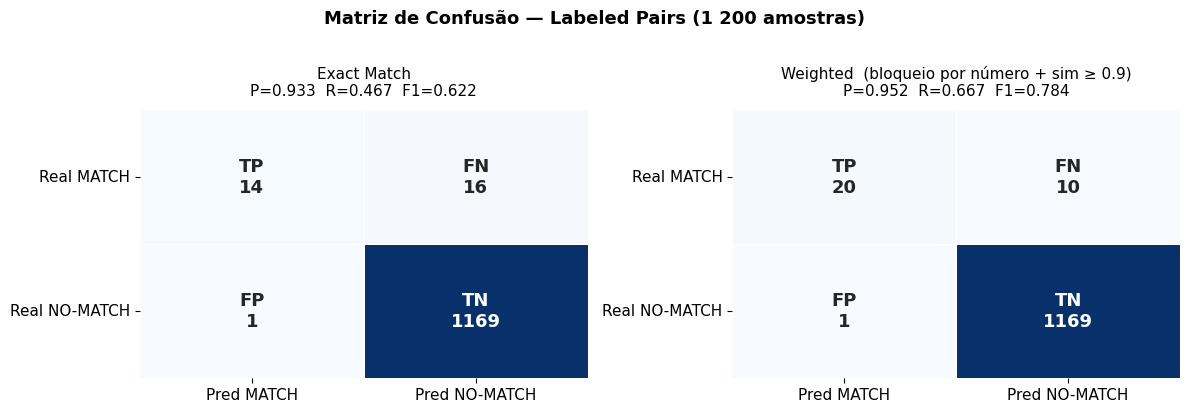

Salvo em: output/confusion_matrix.png


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

def plot_confusion_matrix(m: dict, title: str, ax: plt.Axes) -> None:
    matrix = np.array([[m["tp"], m["fn"]],
                        [m["fp"], m["tn"]]])
    labels = np.array([
        [f"TP\n{m['tp']}", f"FN\n{m['fn']}"],
        [f"FP\n{m['fp']}", f"TN\n{m['tn']}"],
    ])

    sns.heatmap(
        matrix,
        annot=labels,
        fmt="",
        cmap="Blues",
        linewidths=0.5,
        linecolor="white",
        cbar=False,
        ax=ax,
        annot_kws={"size": 13, "weight": "bold"},
    )
    ax.set_xticklabels(["Pred MATCH", "Pred NO-MATCH"], fontsize=11)
    ax.set_yticklabels(["Real MATCH", "Real NO-MATCH"], fontsize=11, rotation=0)
    ax.set_title(
        f"{title}\nP={m['precision']:.3f}  R={m['recall']:.3f}  F1={m['f1_score']:.3f}",
        fontsize=11, pad=10,
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Matriz de Confusão — Labeled Pairs (1 200 amostras)", fontsize=13, fontweight="bold", y=1.02)

plot_confusion_matrix(metrics_exact,    "Exact Match", axes[0])
plot_confusion_matrix(metrics_weighted, f"Weighted  (bloqueio por número + sim ≥ {SIMILARITY_THRESHOLD})", axes[1])

plt.tight_layout()
plt.savefig("output/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
print("Salvo em: output/confusion_matrix.png")

In [14]:
import pandas as pd

# Carregar os pares enriquecidos
df = pd.read_csv("dados/pairs_normalized.csv")
df['label'] = df['label'].astype(int)
df['exact_match_pred'] = df['exact_match_pred'].astype(int)

# Filtro de Falsos Negativos (Atrapalham o Recall)
# Itens são iguais, mas a normalização gerou strings diferentes
fn_df = df[(df['label'] == 1) & (df['exact_match_pred'] == 0)]

# Filtro de Falsos Positivos (Atrapalham a Precision)
# Itens são diferentes, mas a normalização os tornou idênticos
fp_df = df[(df['label'] == 0) & (df['exact_match_pred'] == 1)]

colunas_interesse = ['item_a_normalized', 'item_b_normalized'] 

print(f"--- FALSOS POSITIVOS: {len(fp_df)} (Deixou genérico demais) ---")
display(fp_df[colunas_interesse].head(10))

print(f"\n--- FALSOS NEGATIVOS: {len(fn_df)} (Inconsistente na formatação) ---")
display(fn_df[colunas_interesse].head(10))

--- FALSOS POSITIVOS: 1 (Deixou genérico demais) ---


,item_a_normalized,item_b_normalized
1163,estetoscópio Littmann classic iii,estetoscópio Littmann classic iii



--- FALSOS NEGATIVOS: 16 (Inconsistente na formatação) ---


,item_a_normalized,item_b_normalized
50,grama erva gato - 6,sementes grama erva gatos - 6
80,sementes grama erva gatos - 3,grama erva gato - 6
148,"cartão memória Sandisk ultra, classe 10 - 64 gb","cartão memória Sandisk ultra, micro sd xc - 64 gb"
341,"carburador cht, gasolina","carburador cht 1.6, gasolina"
353,iluminador luz estúdio - 2,iluminador estúdio - 2
533,faixa adesiva - 5 cm,faixa adesiva máquina tatoo - 5 cm
627,esparadrapo Missner 10cm x 50mt,esparadrapo Missner 10cm x 50m
674,"controle longa distancia Stetsom sx-2, 500 metros","controle longa distancia Stetsom amarelo sx2, ..."
707,top biquíni cropped com bojo,top biquíni com bojo
765,lâmina trator Husqvarna lt 1597 - 2,"lâmina faca Husqvarna lt131 lt1597, 18538 - 2"


## 7. Constância das Normalizações (grupos do mesmo produto)

Para cada grupo de títulos que representam o **mesmo produto** (pares com `label=1` unidos transitivamente via union-find), calcula a constância das normalizações usando distância de edição ponderada — letras têm custo baixo, dígitos têm custo alto, impedindo que quantidades diferentes sejam agrupadas.

- **Constância exata**: fração do grupo que gerou a string normalizada dominante idêntica
- **Constância ponderada**: fração do grupo no cluster dominante por distância ponderada (tolera typos/abreviações, rejeita trocas de dígito)

In [15]:
from collections import Counter, defaultdict
from benchmark.weighted_distance import constancy_with_weighted_distance

# ── Reconstrói mapeamento título → normalização ───────────────
title_to_norm: dict[str, str] = {}
for row in pairs:
    title_to_norm[row["title_a"].strip()] = row["item_a_normalized"].strip()
    title_to_norm[row["title_b"].strip()] = row["item_b_normalized"].strip()

# ── Union-Find sobre pares label=1 ────────────────────────────
parent: dict[str, str] = {}

def _find(x: str) -> str:
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent.setdefault(parent[x], parent[x])
        x = parent[x]
    return x

def _union(a: str, b: str) -> None:
    pa, pb = _find(a), _find(b)
    if pa != pb:
        parent[pa] = pb

for row in pairs:
    if row["label"].strip() == "1":
        _union(row["title_a"].strip(), row["title_b"].strip())

# ── Agrupa normalizações por produto ──────────────────────────
groups_norm: dict[str, list[str]] = defaultdict(list)
for title, norm in title_to_norm.items():
    if title in parent:
        groups_norm[_find(title)].append(norm)

# ── Calcula constância por grupo ──────────────────────────────
group_results = []
for root, norms in groups_norm.items():
    if len(norms) < 2:
        continue
    counter = Counter(norms)
    exact_dom = max(counter.values())
    constancy_exact = exact_dom / len(norms)

    constancy_wd, _, dom_wd, _ = constancy_with_weighted_distance(norms)

    group_results.append({
        "group_size":        len(norms),
        "constancy_exact":   round(constancy_exact, 4),
        "constancy_weighted": round(constancy_wd, 4),
        "dominant_norm":     counter.most_common(1)[0][0],
        "all_norms":         norms,
    })

group_results.sort(key=lambda r: r["constancy_exact"])

# ── Métricas agregadas ────────────────────────────────────────
if group_results:
    mean_exact    = sum(r["constancy_exact"]    for r in group_results) / len(group_results)
    mean_weighted = sum(r["constancy_weighted"] for r in group_results) / len(group_results)
    n_perfect_exact    = sum(1 for r in group_results if r["constancy_exact"]    == 1.0)
    n_perfect_weighted = sum(1 for r in group_results if r["constancy_weighted"] == 1.0)
else:
    mean_exact = mean_weighted = 0.0
    n_perfect_exact = n_perfect_weighted = 0

print("=" * 65)
print("  7. CONSTÂNCIA POR GRUPO DE PRODUTO")
print("=" * 65)
print(f"  Grupos avaliados (≥2 títulos): {len(group_results)}")
print(f"  {'Métrica':<35s} {'Exata':>8s}  {'Ponderada':>9s}")
print(f"  {'─' * 35} {'─' * 8}  {'─' * 9}")
print(f"  {'Constância média':<35s} {mean_exact:>8.4f}  {mean_weighted:>9.4f}")
print(f"  {'Grupos com constância = 1.0':<35s} {n_perfect_exact:>8d}  {n_perfect_weighted:>9d}")
print(f"  {'Total de grupos':<35s} {len(group_results):>8d}")
print()

if group_results:
    print("  Grupos com menor constância exata:")
    for r in group_results[:5]:
        print(f"    constância exata={r['constancy_exact']:.2f}  ponderada={r['constancy_weighted']:.2f}  (n={r['group_size']})")
        for n in r["all_norms"]:
            print(f"      · {n}")
        print()

# Distribuicao de tamanho dos grupos + IC 95% da constancia media
from collections import Counter as _Counter30
group_size_distribution = dict(sorted(_Counter30(r["group_size"] for r in group_results).items()))

if group_results:
    ci_mean_exact    = bootstrap_mean_ci([r["constancy_exact"]    for r in group_results])
    ci_mean_weighted = bootstrap_mean_ci([r["constancy_weighted"] for r in group_results])
else:
    ci_mean_exact = ci_mean_weighted = [None, None]

print("  Distribuicao de tamanho dos grupos (group_size -> numero de grupos):")
for size, count in group_size_distribution.items():
    print(f"    {size:>3d} titulos : {count} grupo(s)")
print()
print(f"  IC 95% constancia media exata    : {ci_mean_exact}")
print(f"  IC 95% constancia media ponderada: {ci_mean_weighted}")

CONSTANCY_GROUPS_JSON = Path("output/constancy_groups.json")
with CONSTANCY_GROUPS_JSON.open("w", encoding="utf-8") as fh:
    json.dump({
        "n_groups":                     len(group_results),
        "mean_constancy_exact":         round(mean_exact, 4) if group_results else None,
        "mean_constancy_exact_ci95":    ci_mean_exact,
        "mean_constancy_weighted":      round(mean_weighted, 4) if group_results else None,
        "mean_constancy_weighted_ci95": ci_mean_weighted,
        "group_size_distribution":      group_size_distribution,
        "groups":                       group_results,
    }, fh, ensure_ascii=False, indent=2)
print(f"\nSalvo em: {CONSTANCY_GROUPS_JSON.resolve()}")


  7. CONSTÂNCIA POR GRUPO DE PRODUTO
  Grupos avaliados (≥2 títulos): 26
  Métrica                                Exata  Ponderada
  ─────────────────────────────────── ────────  ─────────
  Constância média                      0.6795     0.8718
  Grupos com constância = 1.0                9         19
  Total de grupos                           26

  Grupos com menor constância exata:
    constância exata=0.50  ponderada=1.00  (n=2)
      · grama erva gato - 6
      · sementes grama erva gatos - 6

    constância exata=0.50  ponderada=0.50  (n=2)
      · cartão memória Sandisk ultra, classe 10 - 64 gb
      · cartão memória Sandisk ultra, micro sd xc - 64 gb

    constância exata=0.50  ponderada=1.00  (n=2)
      · controle longa distancia Stetsom amarelo sx2, 500m
      · controle longa distancia Stetsom sx-2, 500 metros

    constância exata=0.50  ponderada=0.50  (n=2)
      · porta toalha Deca 2040.c.flx, barra
      · porta toalha Deca 2040 c37, izy

    constância exata=0.50  po

### 7b. Constância — OpenAI gpt-5.4-mini

Mesma análise de constância por grupo usando `dados/pairs_normalized_openai_gpt5.4mini.csv`.  
Reutiliza o union-find de `label=1` já construído na seção 7.

In [28]:
_csv_7b = "dados/pairs_normalized_openai_gpt5.4mini.csv"
_path_7b = Path(_csv_7b).resolve()
if not _path_7b.is_file():
    _csv_7b = "dados/pairs_normalized_openai_gpt4omini.csv"
    _path_7b = Path(_csv_7b).resolve()

if not _path_7b.is_file():
    print(f"[SKIP] nenhum CSV gpt4omini/gpt5.4mini encontrado em dados/")
else:
    from csv import DictReader as _DR7b
    from collections import defaultdict as _dd7b, Counter as _Cnt7b
    with _path_7b.open(encoding="utf-8-sig", newline="") as fh:
        _pairs_7b = list(_DR7b(fh))

    _t2n_7b = {}
    for row in _pairs_7b:
        _t2n_7b[row["title_a"].strip()] = row["item_a_normalized"].strip()
        _t2n_7b[row["title_b"].strip()] = row["item_b_normalized"].strip()

    _gn_7b = _dd7b(list)
    for title, norm in _t2n_7b.items():
        if title in parent:
            _gn_7b[_find(title)].append(norm)

    _res_7b = []
    for root, norms in _gn_7b.items():
        if len(norms) < 2: continue
        cnt = _Cnt7b(norms)
        ce = max(cnt.values()) / len(norms)
        cw, _, _, _ = constancy_with_weighted_distance(norms)
        _res_7b.append({"group_size": len(norms), "constancy_exact": round(ce,4),
                        "constancy_weighted": round(cw,4), "all_norms": norms})
    _res_7b.sort(key=lambda r: r["constancy_exact"])

    if _res_7b:
        _me = sum(r["constancy_exact"]    for r in _res_7b) / len(_res_7b)
        _mw = sum(r["constancy_weighted"] for r in _res_7b) / len(_res_7b)
        _pe = sum(1 for r in _res_7b if r["constancy_exact"]    == 1.0)
        _pw = sum(1 for r in _res_7b if r["constancy_weighted"] == 1.0)
    else:
        _me = _mw = 0.0; _pe = _pw = 0

    _model_label = "gpt-5.4-mini" if "gpt5.4" in _csv_7b else "gpt-4o-mini"
    print("=" * 65)
    print(f"  7b. CONSTÂNCIA — OpenAI {_model_label}")
    print("=" * 65)
    print(f"  Grupos avaliados (≥2 títulos): {len(_res_7b)}")
    print(f"  {'Métrica':<35s} {'Exata':>8s}  {'Ponderada':>9s}")
    print(f"  {'─'*35} {'─'*8}  {'─'*9}")
    print(f"  {'Constância média':<35s} {_me:>8.4f}  {_mw:>9.4f}")
    print(f"  {'Grupos com constância = 1.0':<35s} {_pe:>8d}  {_pw:>9d}")
    print(f"  {'Total de grupos':<35s} {len(_res_7b):>8d}")
    if _res_7b:
        print("\n  Grupos com menor constância exata:")
        for r in _res_7b[:5]:
            print(f"    exata={r['constancy_exact']:.2f}  pond={r['constancy_weighted']:.2f}  (n={r['group_size']})")
            for n in r["all_norms"]: print(f"      · {n}")

    _gsd_7b = dict(sorted(_Cnt7b(r["group_size"] for r in _res_7b).items()))
    if _res_7b:
        _ci_me_7b = bootstrap_mean_ci([r["constancy_exact"]    for r in _res_7b])
        _ci_mw_7b = bootstrap_mean_ci([r["constancy_weighted"] for r in _res_7b])
    else:
        _ci_me_7b = _ci_mw_7b = [None, None]
    print(f"\n  IC 95% constancia media exata    : {_ci_me_7b}")
    print(f"  IC 95% constancia media ponderada: {_ci_mw_7b}")

    _CONSTANCY_JSON_7b = Path("output/constancy_groups_gpt.json")
    with _CONSTANCY_JSON_7b.open("w", encoding="utf-8") as fh:
        json.dump({
            "n_groups":                     len(_res_7b),
            "mean_constancy_exact":         round(_me, 4) if _res_7b else None,
            "mean_constancy_exact_ci95":    _ci_me_7b,
            "mean_constancy_weighted":      round(_mw, 4) if _res_7b else None,
            "mean_constancy_weighted_ci95": _ci_mw_7b,
            "group_size_distribution":      _gsd_7b,
            "groups":                       _res_7b,
        }, fh, ensure_ascii=False, indent=2)
    print(f"  Salvo em: {_CONSTANCY_JSON_7b.resolve()}")

  7b. CONSTÂNCIA — OpenAI gpt-5.4-mini
  Grupos avaliados (≥2 títulos): 26
  Métrica                                Exata  Ponderada
  ─────────────────────────────────── ────────  ─────────
  Constância média                      0.6282     0.8269
  Grupos com constância = 1.0                6         17
  Total de grupos                           26

  Grupos com menor constância exata:
    exata=0.50  pond=1.00  (n=2)
      · grama gato - kit 3
      · sementes - kit 3
    exata=0.50  pond=0.50  (n=2)
      · cartao memoria Sandisk ultra, classe 10 - 64 gb
      · cartão memória Sandisk micro sd xc - 64 gb
    exata=0.50  pond=1.00  (n=2)
      · balde pipoca Personali - 30
      · balde pipoca Personali - kit 30
    exata=0.50  pond=1.00  (n=2)
      · controle Stetsom amarelo sx2 - 500 ml
      · controle Stetsom sx-2, 500 metros
    exata=0.50  pond=0.50  (n=2)
      · porta toalha Deca 2040.c.flx
      · porta toalha Deca izy 2040 c37

  IC 95% constancia media exata    : [0.551

### 7c. Constância — Cerebras gpt-oss-120b

Mesma análise de constância por grupo usando `dados/pairs_normalized_cerebras120b.csv`.  
Reutiliza o union-find de `label=1` já construído na seção 7.

In [17]:
_csv_7c = "dados/pairs_normalized_cerebras120b.csv"
_path_7c = Path(_csv_7c).resolve()

if not _path_7c.is_file():
    print(f"[SKIP] {_path_7c} não encontrado.")
else:
    from csv import DictReader as _DR7c
    from collections import defaultdict as _dd7c, Counter as _Cnt7c
    with _path_7c.open(encoding="utf-8-sig", newline="") as fh:
        _pairs_7c = list(_DR7c(fh))

    _t2n_7c = {}
    for row in _pairs_7c:
        _t2n_7c[row["title_a"].strip()] = row["item_a_normalized"].strip()
        _t2n_7c[row["title_b"].strip()] = row["item_b_normalized"].strip()

    _gn_7c = _dd7c(list)
    for title, norm in _t2n_7c.items():
        if title in parent:
            _gn_7c[_find(title)].append(norm)

    _res_7c = []
    for root, norms in _gn_7c.items():
        if len(norms) < 2: continue
        cnt = _Cnt7c(norms)
        ce = max(cnt.values()) / len(norms)
        cw, _, _, _ = constancy_with_weighted_distance(norms)
        _res_7c.append({"group_size": len(norms), "constancy_exact": round(ce,4),
                        "constancy_weighted": round(cw,4), "all_norms": norms})
    _res_7c.sort(key=lambda r: r["constancy_exact"])

    if _res_7c:
        _me = sum(r["constancy_exact"]    for r in _res_7c) / len(_res_7c)
        _mw = sum(r["constancy_weighted"] for r in _res_7c) / len(_res_7c)
        _pe = sum(1 for r in _res_7c if r["constancy_exact"]    == 1.0)
        _pw = sum(1 for r in _res_7c if r["constancy_weighted"] == 1.0)
    else:
        _me = _mw = 0.0; _pe = _pw = 0

    print("=" * 65)
    print("  7c. CONSTÂNCIA — Cerebras gpt-oss-120b")
    print("=" * 65)
    print(f"  Grupos avaliados (≥2 títulos): {len(_res_7c)}")
    print(f"  {'Métrica':<35s} {'Exata':>8s}  {'Ponderada':>9s}")
    print(f"  {'─'*35} {'─'*8}  {'─'*9}")
    print(f"  {'Constância média':<35s} {_me:>8.4f}  {_mw:>9.4f}")
    print(f"  {'Grupos com constância = 1.0':<35s} {_pe:>8d}  {_pw:>9d}")
    print(f"  {'Total de grupos':<35s} {len(_res_7c):>8d}")
    if _res_7c:
        print("\n  Grupos com menor constância exata:")
        for r in _res_7c[:5]:
            print(f"    exata={r['constancy_exact']:.2f}  pond={r['constancy_weighted']:.2f}  (n={r['group_size']})")
            for n in r["all_norms"]: print(f"      · {n}")

[SKIP] C:\Users\nunes\invoice-data-normalizer\main_supersaurus\dados\pairs_normalized_cerebras120b.csv não encontrado.


### 7d. Constância — DeepSeek V4 Flash

Mesma análise de constância por grupo usando `dados/pairs_normalized_deepseek.csv`.
Reutiliza o union-find de `label=1` já construído na seção 7.

In [29]:
_csv_7d = "dados/pairs_normalized_deepseek.csv"
_path_7d = Path(_csv_7d).resolve()

if not _path_7d.is_file():
    print(f"[SKIP] {_path_7d} não encontrado.")
else:
    from csv import DictReader as _DR7d
    from collections import defaultdict as _dd7d, Counter as _Cnt7d
    with _path_7d.open(encoding="utf-8-sig", newline="") as fh:
        _pairs_7d = list(_DR7d(fh))

    _t2n_7d = {}
    for row in _pairs_7d:
        _t2n_7d[row["title_a"].strip()] = row["item_a_normalized"].strip()
        _t2n_7d[row["title_b"].strip()] = row["item_b_normalized"].strip()

    _gn_7d = _dd7d(list)
    for title, norm in _t2n_7d.items():
        if title in parent:
            _gn_7d[_find(title)].append(norm)

    _res_7d = []
    for root, norms in _gn_7d.items():
        if len(norms) < 2: continue
        cnt = _Cnt7d(norms)
        ce = max(cnt.values()) / len(norms)
        cw, _, _, _ = constancy_with_weighted_distance(norms)
        _res_7d.append({"group_size": len(norms), "constancy_exact": round(ce, 4),
                        "constancy_weighted": round(cw, 4), "all_norms": norms})
    _res_7d.sort(key=lambda r: r["constancy_exact"])

    if _res_7d:
        _me = sum(r["constancy_exact"]    for r in _res_7d) / len(_res_7d)
        _mw = sum(r["constancy_weighted"] for r in _res_7d) / len(_res_7d)
        _pe = sum(1 for r in _res_7d if r["constancy_exact"]    == 1.0)
        _pw = sum(1 for r in _res_7d if r["constancy_weighted"] == 1.0)
    else:
        _me = _mw = 0.0; _pe = _pw = 0

    print("=" * 65)
    print("  7d. CONSTÂNCIA — DeepSeek V4 Flash")
    print("=" * 65)
    print(f"  Grupos avaliados (>=2 títulos): {len(_res_7d)}")
    print(f"  {'Métrica':<35s} {'Exata':>8s}  {'Ponderada':>9s}")
    print(f"  {'─'*35} {'─'*8}  {'─'*9}")
    print(f"  {'Constância média':<35s} {_me:>8.4f}  {_mw:>9.4f}")
    print(f"  {'Grupos com constância = 1.0':<35s} {_pe:>8d}  {_pw:>9d}")
    print(f"  {'Total de grupos':<35s} {len(_res_7d):>8d}")
    if _res_7d:
        print("\n  Grupos com menor constância exata:")
        for r in _res_7d[:5]:
            print(f"    exata={r['constancy_exact']:.2f}  pond={r['constancy_weighted']:.2f}  (n={r['group_size']})")
            for n in r["all_norms"]: print(f"      · {n}")

    _gsd_7d = dict(sorted(_Cnt7d(r["group_size"] for r in _res_7d).items()))
    if _res_7d:
        _ci_me_7d = bootstrap_mean_ci([r["constancy_exact"]    for r in _res_7d])
        _ci_mw_7d = bootstrap_mean_ci([r["constancy_weighted"] for r in _res_7d])
    else:
        _ci_me_7d = _ci_mw_7d = [None, None]
    print(f"\n  IC 95% constancia media exata    : {_ci_me_7d}")
    print(f"  IC 95% constancia media ponderada: {_ci_mw_7d}")

    _CONSTANCY_JSON_7d = Path("output/constancy_groups_deepseek.json")
    with _CONSTANCY_JSON_7d.open("w", encoding="utf-8") as fh:
        json.dump({
            "n_groups":                     len(_res_7d),
            "mean_constancy_exact":         round(_me, 4) if _res_7d else None,
            "mean_constancy_exact_ci95":    _ci_me_7d,
            "mean_constancy_weighted":      round(_mw, 4) if _res_7d else None,
            "mean_constancy_weighted_ci95": _ci_mw_7d,
            "group_size_distribution":      _gsd_7d,
            "groups":                       _res_7d,
        }, fh, ensure_ascii=False, indent=2)
    print(f"  Salvo em: {_CONSTANCY_JSON_7d.resolve()}")

  7d. CONSTÂNCIA — DeepSeek V4 Flash
  Grupos avaliados (>=2 títulos): 26
  Métrica                                Exata  Ponderada
  ─────────────────────────────────── ────────  ─────────
  Constância média                      0.6859     0.8846
  Grupos com constância = 1.0                9         20
  Total de grupos                           26

  Grupos com menor constância exata:
    exata=0.50  pond=1.00  (n=2)
      · grama erva gato - 3
      · sementes grama erva gatos - 3
    exata=0.50  pond=0.50  (n=2)
      · cartão memória Sandisk classe 10 - 64 gb
      · cartão memória Sandisk full hd - 64 gb
    exata=0.50  pond=1.00  (n=2)
      · controle Stetsom amarelo sx2, 500m
      · controle Stetsom sx-2, 500 metros
    exata=0.50  pond=0.50  (n=2)
      · porta toalha Deca 2040.c.flx
      · porta toalha Deca izy 2040 c37
    exata=0.50  pond=1.00  (n=2)
      · esfregão
      · vassoura esfregão

  IC 95% constancia media exata    : [0.5962, 0.7756]
  IC 95% constancia med

## 8. Comparação com Baseline — TF-IDF

Carrega dados/baseline_predictions.csv gerado por aseline.ipynb e compara os baselines TF-IDF com o pipeline LLM (seções 6 e 7).

**Pré-requisito:** executar aseline.ipynb antes desta seção.

| Método | Precision | Recall | F1 |
|---|---|---|---|
| TF-IDF word (threshold ótimo) | — | — | — |
| TF-IDF char (threshold ótimo) | — | — | — |
| LLM Exact Match | 0.6667 | 0.4516 | 0.5385 |
| LLM Weighted | 0.5556 | 0.4839 | 0.5172 |

In [27]:
import json
import pandas as pd
from pathlib import Path

BASELINE_CSV  = "dados/baseline_predictions.csv"
BASELINE_JSON = "output/baseline_metrics.json"

baseline_path = Path(BASELINE_CSV).resolve()
if not baseline_path.is_file():
    raise FileNotFoundError(
        f"CSV nao encontrado: {baseline_path}.\n"
        "Execute baseline.ipynb antes desta secao."
    )

df_bl = pd.read_csv(baseline_path, dtype=str, encoding="utf-8-sig")
df_bl["label"] = df_bl["label"].astype(int)

metrics_json = Path(BASELINE_JSON)
if metrics_json.is_file():
    bl_metrics = json.loads(metrics_json.read_text(encoding="utf-8"))
else:
    bl_metrics = {}

def compute_from_df(df, pred_col):
    df[pred_col] = df[pred_col].astype(int)
    tp = int(((df[pred_col] == 1) & (df["label"] == 1)).sum())
    fp = int(((df[pred_col] == 1) & (df["label"] == 0)).sum())
    fn = int(((df[pred_col] == 0) & (df["label"] == 1)).sum())
    tn = int(((df[pred_col] == 0) & (df["label"] == 0)).sum())
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec  = tp / (tp + fn) if (tp + fn) else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return dict(tp=tp, fp=fp, fn=fn, tn=tn,
                precision=round(prec,4), recall=round(rec,4), f1_score=round(f1,4),
                n_positive=tp + fn, n_negative=fp + tn, num_pairs=len(df))

m_word = compute_from_df(df_bl, "pred_tfidf_word")
m_char = compute_from_df(df_bl, "pred_tfidf_char")

# IC 95% bootstrap (colunas ja convertidas para int por compute_from_df acima)
ci_word = bootstrap_pairwise_ci(df_bl["label"].tolist(), df_bl["pred_tfidf_word"].tolist())
ci_char = bootstrap_pairwise_ci(df_bl["label"].tolist(), df_bl["pred_tfidf_char"].tolist())
m_word.update(ci_word)
m_char.update(ci_char)

bl_metrics["tfidf_word_optimal"] = {**bl_metrics.get("tfidf_word_optimal", {}), **m_word}
bl_metrics["tfidf_char_optimal"] = {**bl_metrics.get("tfidf_char_optimal", {}), **m_char}
with metrics_json.open("w", encoding="utf-8") as fh:
    json.dump(bl_metrics, fh, ensure_ascii=False, indent=2)

# Metricas do LLM principal (secao 6, Gemini 3.1 Flash-Lite) lidas do resultado
# ja calculado em memoria -- antes estava hardcoded com valores desatualizados
# (0.6667/0.4516), divergentes do que a secao 6 realmente calculava.
m_llm_exact    = metrics_exact
m_llm_weighted = metrics_weighted

thr_word = bl_metrics.get('tfidf_word_optimal', {}).get('threshold', '?')
thr_char = bl_metrics.get('tfidf_char_optimal', {}).get('threshold', '?')

print('=' * 68)
print('  8. COMPARACAO COM BASELINES TF-IDF')
print('=' * 68)
print(f"  {'Metodo':<38s} {'Prec':>6s} {'Rec':>6s} {'F1':>6s}")
print(f"  {'-' * 38} {'-' * 6} {'-' * 6} {'-' * 6}")
print(f"  {f'TF-IDF word  (thr={thr_word})':<38s} {m_word['precision']:>6.4f} {m_word['recall']:>6.4f} {m_word['f1_score']:>6.4f}")
print(f"  {f'TF-IDF char  (thr={thr_char})':<38s} {m_char['precision']:>6.4f} {m_char['recall']:>6.4f} {m_char['f1_score']:>6.4f}")
print(f"  {'Gemini 3.1 Flash-Lite (Exact)':<38s} {m_llm_exact['precision']:>6.4f} {m_llm_exact['recall']:>6.4f} {m_llm_exact['f1_score']:>6.4f}")
print(f"  {'Gemini 3.1 Flash-Lite (Weighted)':<38s} {m_llm_weighted['precision']:>6.4f} {m_llm_weighted['recall']:>6.4f} {m_llm_weighted['f1_score']:>6.4f}")
print()
print(f"  IC 95% TF-IDF word  -> precision {ci_word['precision_ci95']}  recall {ci_word['recall_ci95']}  f1 {ci_word['f1_ci95']}")
print(f"  IC 95% TF-IDF char  -> precision {ci_char['precision_ci95']}  recall {ci_char['recall_ci95']}  f1 {ci_char['f1_ci95']}")

  8. COMPARACAO COM BASELINES TF-IDF
  Metodo                                   Prec    Rec     F1
  -------------------------------------- ------ ------ ------
  TF-IDF word  (thr=0.608)               0.5405 0.6667 0.5970
  TF-IDF char  (thr=0.7789)              0.5135 0.6333 0.5672
  Gemini 3.1 Flash-Lite (Exact)          0.9333 0.4667 0.6222
  Gemini 3.1 Flash-Lite (Weighted)       0.9524 0.6667 0.7843

  IC 95% TF-IDF word  -> precision [0.3721, 0.7]  recall [0.4839, 0.8333]  f1 [0.4444, 0.7246]
  IC 95% TF-IDF char  -> precision [0.35, 0.675]  recall [0.4516, 0.8]  f1 [0.4082, 0.6984]


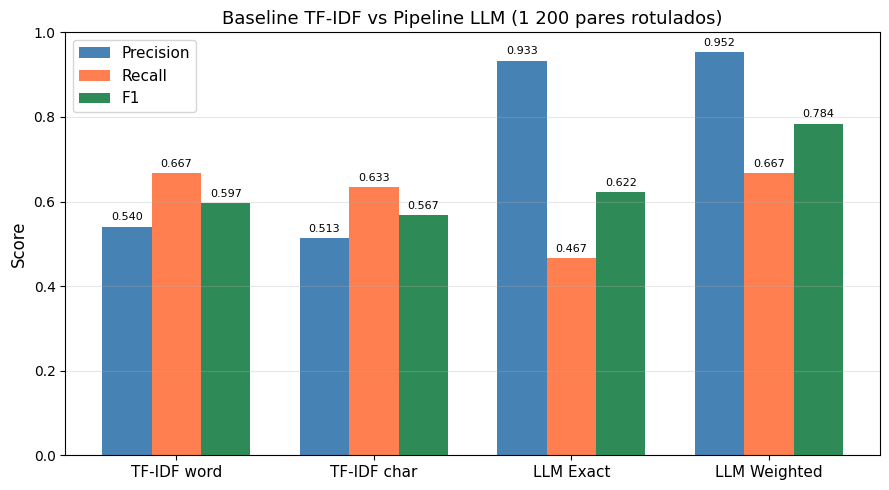

Salvo em: output/baseline_vs_llm.png


In [26]:
import matplotlib.pyplot as plt
import numpy as np

methods  = ['TF-IDF word', 'TF-IDF char', 'LLM Exact', 'LLM Weighted']
precs    = [m_word['precision'], m_char['precision'], m_llm_exact['precision'], m_llm_weighted['precision']]
recs     = [m_word['recall'],    m_char['recall'],    m_llm_exact['recall'],    m_llm_weighted['recall']]
f1s      = [m_word['f1_score'],  m_char['f1_score'],  m_llm_exact['f1_score'],  m_llm_weighted['f1_score']]

x = np.arange(len(methods))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 5))
bars_p = ax.bar(x - width, precs, width, label='Precision', color='steelblue')
bars_r = ax.bar(x,         recs,  width, label='Recall',    color='coral')
bars_f = ax.bar(x + width, f1s,   width, label='F1',        color='seagreen')

ax.set_xticks(x)
ax.set_xticklabels(methods, fontsize=11)
ax.set_ylim(0, 1.0)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Baseline TF-IDF vs Pipeline LLM (1 200 pares rotulados)', fontsize=13)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)

for bar in [*bars_p, *bars_r, *bars_f]:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 0.01, f'{h:.3f}',
            ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('output/baseline_vs_llm.png', dpi=150, bbox_inches='tight')
plt.show()
print('Salvo em: output/baseline_vs_llm.png')

## 9. Estabilidade entre execuções (não-determinismo do modelo)

Fonte de incerteza **diferente** da IC bootstrap da Seção 6 (aquela mede incerteza de amostragem sobre os 1.200 pares fixos; esta mede o quanto a própria extração do LLM muda entre execuções repetidas do mesmo modelo/prompt/dataset, com `temperature=0`). As duas **não devem ser somadas** — são reportadas separadamente.

Requer rodar `classifier_api.ipynb` mais de uma vez por modelo com `RUN_ID=2,3,4,5` (ver célula de configuração), sem sobrescrever os arquivos canônicos (`RUN_ID=1`, sem sufixo, é o que a Tabela 3 já usa). Recomendação: piloto com `RUN_ID=2` só no Gemini primeiro — se a estabilidade de extração vier ≥0,99, o efeito é pequeno e as demais execuções servem só de confirmação barata; se vier ≤0,90, vale investigar antes de rodar os outros 3 modelos.

Duas métricas, calculadas por modelo a partir de todas as execuções encontradas:
1. **Variação das métricas finais** (precision/recall/F1, exact e weighted): média e desvio-padrão entre execuções.
2. **Estabilidade de extração**: fração de títulos únicos cujo `item_*_normalized` (nome canônico) é *idêntico* em todas as execuções encontradas — isola o efeito antes do limiar de matching, análogo à constância da Seção 7, mas entre execuções em vez de entre grupo de produto.

In [21]:
import glob
import json
import numpy as np
import pandas as pd
import re as _re_stab
from collections import defaultdict
from pathlib import Path

def _find_run_files(pattern: str) -> dict[int, str]:
    """{run_id: caminho}, incluindo run 1 (arquivo canonico sem sufixo _run{k})."""
    runs = {}
    canonical = pattern.format(suffix="")
    if Path(canonical).is_file():
        runs[1] = canonical
    for p in glob.glob(pattern.format(suffix="_run*")):
        m = _re_stab.search(r"_run(\d+)\.csv$", p)
        if m:
            runs[int(m.group(1))] = p
    return dict(sorted(runs.items()))


MODEL_RUN_PATTERNS = {
    "Gemini 3.1 Flash-Lite": "dados/pairs_normalized{suffix}.csv",
    "GPT-5.4-mini":          "dados/pairs_normalized_openai_gpt5.4mini{suffix}.csv",
    "DeepSeek V4 Flash":     "dados/pairs_normalized_deepseek{suffix}.csv",
}

RUN_STABILITY_JSON = Path("output/run_stability.json")


def analyze_model_stability(model_name: str) -> dict | None:
    """Roda a analise de estabilidade pra UM modelo, imprime o relatorio no
    mesmo formato de sempre, e salva/atualiza so a entrada desse modelo em
    output/run_stability.json (preserva o que ja tiver sido salvo pros outros).
    """
    pattern = MODEL_RUN_PATTERNS[model_name]
    runs = _find_run_files(pattern)
    print("=" * 65)
    print(f"  {model_name} -- {len(runs)} execucao(oes) encontrada(s): {list(runs.keys())}")
    print("=" * 65)
    if len(runs) < 2:
        print("  Menos de 2 execucoes -> pulado. Rode classifier_api.ipynb com")
        print("  RUN_ID=2 (piloto) ou 2..5 (completo) para habilitar esta secao.\n")
        return None

    dfs = {}
    for run_id, path in runs.items():
        df = pd.read_csv(path, dtype=str, encoding="utf-8-sig")
        df["item_a_normalized"] = df["item_a_normalized"].fillna("")
        df["item_b_normalized"] = df["item_b_normalized"].fillna("")
        if "a_quantidade" not in df.columns:
            df["a_quantidade"] = ""
        if "b_quantidade" not in df.columns:
            df["b_quantidade"] = ""
        df["a_quantidade"] = df["a_quantidade"].fillna("")
        df["b_quantidade"] = df["b_quantidade"].fillna("")
        df["exact_match_pred"] = [
            "1" if post_normalize(a) == post_normalize(b) else "0"
            for a, b in zip(df["item_a_normalized"], df["item_b_normalized"])
        ]
        df["weighted_pred"] = [
            str(predict_weighted(a, b, qa, qb)[1])
            for a, b, qa, qb in zip(df["item_a_normalized"], df["item_b_normalized"],
                                     df["a_quantidade"], df["b_quantidade"])
        ]
        dfs[run_id] = df

    per_run = []
    for run_id, df in dfs.items():
        records = df.to_dict("records")
        per_run.append({
            "run": run_id,
            "exact": compute_metrics(records, "exact_match_pred"),
            "weighted": compute_metrics(records, "weighted_pred"),
        })

    variation_summary = {}
    for variant in ["exact", "weighted"]:
        prec = [r[variant]["precision"] for r in per_run]
        rec  = [r[variant]["recall"]    for r in per_run]
        f1   = [r[variant]["f1_score"]  for r in per_run]
        variation_summary[variant] = {
            "precision_mean": round(float(np.mean(prec)), 4), "precision_std": round(float(np.std(prec, ddof=1)), 4),
            "recall_mean":    round(float(np.mean(rec)),  4), "recall_std":    round(float(np.std(rec,  ddof=1)), 4),
            "f1_mean":        round(float(np.mean(f1)),   4), "f1_std":        round(float(np.std(f1,   ddof=1)), 4),
            "per_run_values": {"precision": prec, "recall": rec, "f1": f1},
        }
        v = variation_summary[variant]
        print(f"  [{variant:8s}] precision: media={v['precision_mean']:.4f} dp={v['precision_std']:.4f}  valores={prec}")
        print(f"  [{variant:8s}] recall:    media={v['recall_mean']:.4f} dp={v['recall_std']:.4f}  valores={rec}")
        print(f"  [{variant:8s}] f1:        media={v['f1_mean']:.4f} dp={v['f1_std']:.4f}  valores={f1}")
        print()

    title_to_norms = defaultdict(set)
    for run_id, df in dfs.items():
        for col_title, col_norm in [("title_a", "item_a_normalized"), ("title_b", "item_b_normalized")]:
            for t, n in zip(df[col_title], df[col_norm]):
                title_to_norms[t.strip()].add(n.strip())

    n_titles  = len(title_to_norms)
    n_stable  = sum(1 for norms in title_to_norms.values() if len(norms) == 1)
    stab_rate = n_stable / n_titles if n_titles else 0.0
    print(f"  Estabilidade de extracao: {n_stable}/{n_titles} titulos unicos ({stab_rate:.4f}) "
          f"com normalizado identico nas {len(runs)} execucoes")

    unstable_examples = [
        {"title": t, "normalizacoes": sorted(norms)}
        for t, norms in title_to_norms.items() if len(norms) > 1
    ][:5]
    if unstable_examples:
        print("\n  Exemplos de titulos instaveis:")
        for ex in unstable_examples:
            print(f"    {ex['title']!r}")
            for n in ex["normalizacoes"]:
                print(f"      -> {n!r}")
    print()

    result = {
        "runs": list(runs.keys()),
        "metrics_variation": variation_summary,
        "extraction_stability_rate": round(stab_rate, 4),
        "n_titles_unique": n_titles,
        "n_titles_stable": n_stable,
        "unstable_examples": unstable_examples,
    }

    all_results = {}
    if RUN_STABILITY_JSON.is_file():
        all_results = json.loads(RUN_STABILITY_JSON.read_text(encoding="utf-8"))
    all_results[model_name] = result
    RUN_STABILITY_JSON.write_text(json.dumps(all_results, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Salvo em: {RUN_STABILITY_JSON.resolve()}")

    return result


In [22]:
_ = analyze_model_stability("Gemini 3.1 Flash-Lite")


  Gemini 3.1 Flash-Lite -- 3 execucao(oes) encontrada(s): [1, 2, 3]
  [exact   ] precision: media=0.9333 dp=0.0000  valores=[0.9333, 0.9333, 0.9333]
  [exact   ] recall:    media=0.4667 dp=0.0000  valores=[0.4667, 0.4667, 0.4667]
  [exact   ] f1:        media=0.6222 dp=0.0000  valores=[0.6222, 0.6222, 0.6222]

  [weighted] precision: media=0.9524 dp=0.0000  valores=[0.9524, 0.9524, 0.9524]
  [weighted] recall:    media=0.6667 dp=0.0000  valores=[0.6667, 0.6667, 0.6667]
  [weighted] f1:        media=0.7843 dp=0.0000  valores=[0.7843, 0.7843, 0.7843]

  Estabilidade de extracao: 2267/2267 titulos unicos (1.0000) com normalizado identico nas 3 execucoes

Salvo em: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\run_stability.json


In [23]:
_ = analyze_model_stability("GPT-5.4-mini")


  GPT-5.4-mini -- 3 execucao(oes) encontrada(s): [1, 2, 3]
  [exact   ] precision: media=0.5850 dp=0.0279  valores=[0.5556, 0.6111, 0.5882]
  [exact   ] recall:    media=0.3444 dp=0.0193  valores=[0.3333, 0.3667, 0.3333]
  [exact   ] f1:        media=0.4335 dp=0.0219  valores=[0.4167, 0.4583, 0.4255]

  [weighted] precision: media=0.5020 dp=0.0387  valores=[0.4643, 0.5417, 0.5]
  [weighted] recall:    media=0.4222 dp=0.0192  valores=[0.4333, 0.4333, 0.4]
  [weighted] f1:        media=0.4581 dp=0.0204  valores=[0.4483, 0.4815, 0.4444]

  Estabilidade de extracao: 1190/2267 titulos unicos (0.5249) com normalizado identico nas 3 execucoes

  Exemplos de titulos instaveis:
    'Pulseira Casio Original Prata Gshock Dw5600e'
      -> 'pulseira Casio prata dw5600e'
      -> 'pulseira Casio prata dw5600e, gshock'
    'Trimpot 3386f De 500k Uma Volta Lote Com 25 Peças'
      -> 'trimpot 3386f - 25 500000 ml'
      -> 'trimpot 3386f, 500k - 25'
      -> 'trimpot 3386f, uma volta - 25 500 k'
    

In [24]:
_ = analyze_model_stability("DeepSeek V4 Flash")


  DeepSeek V4 Flash -- 3 execucao(oes) encontrada(s): [1, 2, 3]
  [exact   ] precision: media=0.4174 dp=0.0310  valores=[0.3824, 0.4412, 0.4286]
  [exact   ] recall:    media=0.4778 dp=0.0385  valores=[0.4333, 0.5, 0.5]
  [exact   ] f1:        media=0.4455 dp=0.0342  valores=[0.4062, 0.4688, 0.4615]

  [weighted] precision: media=0.4312 dp=0.0468  valores=[0.381, 0.4737, 0.439]
  [weighted] recall:    media=0.5778 dp=0.0385  valores=[0.5333, 0.6, 0.6]
  [weighted] f1:        media=0.4936 dp=0.0441  valores=[0.4444, 0.5294, 0.507]

  Estabilidade de extracao: 1638/2267 titulos unicos (0.7225) com normalizado identico nas 3 execucoes

  Exemplos de titulos instaveis:
    'Pulseira Casio Original Prata Gshock Dw5600e'
      -> 'pulseira Casio prata dw5600e'
      -> 'relógio Casio prata dw5600e'
    'Cadeirinha Reclinável Preta Maestro Bebê 0 À 25 Kg Multikids'
      -> 'cadeirinha Multikids preta maestro - 25 kg'
      -> 'cadeirinha Multikids preta maestro, 25kg'
    'Discos Pastilhas S

## 10. Análises complementares — só recálculo (sem chamadas novas à API)

Tudo nesta seção usa as saídas **já salvas** em `dados/` (3 execuções por modelo) e no Golden Set do AI-PAVE-Br (`revisao/pave/`). Nenhum CSV de entrada é reescrito; as saídas vão para `output/sec10/`.

| # | Análise | O que resolve no texto |
|---|---------|------------------------|
| 10.1 | Média ± desvio-padrão das 3 execuções (VP, FP, FN, P, R, F1) por modelo e variante | O número principal deixa de depender da primeira execução |
| 10.2 | Erros do Gemini na variante ponderada (FN e FP), com títulos originais e canônicos e o motivo de cada erro | Explica por que o melhor modelo perde um terço dos pares |
| 10.3 | Ablação do bloqueio: ponderada só com similaridade e sem cada regra individualmente | Demonstra o efeito do bloqueio, hoje só afirmado |
| 10.4 | Curva do limiar (0,80 a 0,98, passo 0,02) + validação cruzada do limiar | Mostra se 0,90 é robusto e responde à crítica de ajuste no conjunto de avaliação |
| 10.5 | IC 95% bootstrap (sobre itens) no Golden Set, com ΔF1 pareado | Diz com base estatística se o TAIL “empata” ou “fica abaixo” |

**Pré-requisitos (no kernel atual):** Setup, Seção 4b (bootstrap), a primeira célula da Seção 6 (`post_normalize`, `predict_weighted`, `compute_metrics`) e a célula de definição da Seção 9 (`_find_run_files`, `MODEL_RUN_PATTERNS`). A regra ponderada usada aqui é **a mesma** da Seção 6 — a célula 10.0 confere isso par a par.

In [30]:
# ── 10.0 Preparação: carrega as execuções e decompõe a regra ponderada ──────────
import sys
import json
import numpy as np
import pandas as pd
from pathlib import Path

_req = ["post_normalize", "predict_weighted", "_extract_numbers", "_extract_qtd_number",
        "_has_word_number_conflict", "_str_sim", "SIMILARITY_THRESHOLD",
        "_find_run_files", "MODEL_RUN_PATTERNS", "REPO_ROOT", "OUTPUT_DIR"]
_faltando = [n for n in _req if n not in globals()]
if _faltando:
    raise NameError(f"Rode antes Setup, Seção 4b, Seção 6 (1ª célula) e Seção 9 (definições). Faltando: {_faltando}")

THR_PADRAO = 0.90
if SIMILARITY_THRESHOLD != THR_PADRAO:
    raise ValueError(f"SIMILARITY_THRESHOLD={SIMILARITY_THRESHOLD}, esperado {THR_PADRAO} (valor do artigo)")

SEC10_DIR = OUTPUT_DIR / "sec10"
SEC10_DIR.mkdir(parents=True, exist_ok=True)

# Nome legível -> coluna booleana. A ordem é a mesma em que predict_weighted testa.
ROTULO_BLOQUEIO = {
    "quantidade":         "bloq_quantidade",
    "números c/ unidade": "bloq_numeros",
    "palavra+número":     "bloq_palavra_numero",
}
BLOQUEIOS = list(ROTULO_BLOQUEIO.values())


def decompoe_par(norm_a: str, norm_b: str, qtd_a: str = "", qtd_b: str = "") -> dict:
    """Mesmas etapas de predict_weighted, mas devolvendo cada regra separadamente.

    predict_weighted == (sim >= limiar) and not (qualquer bloqueio). Separar as
    regras permite variar o limiar (10.4) e desligar bloqueios (10.3) sem
    duplicar a lógica.
    """
    q_a = _extract_qtd_number(qtd_a) or 1
    q_b = _extract_qtd_number(qtd_b) or 1
    a, b = post_normalize(norm_a), post_normalize(norm_b)
    nums_a, nums_b = _extract_numbers(a), _extract_numbers(b)
    return {
        "bloq_quantidade":     q_a != q_b,
        "bloq_numeros":        bool(nums_a and nums_b and not (nums_a <= nums_b or nums_b <= nums_a)),
        "bloq_palavra_numero": _has_word_number_conflict(a, b),
        "sim":                 _str_sim(a, b),
        "exact":               a == b,
    }


def pred_ponderada(df: pd.DataFrame, limiar: float = THR_PADRAO, bloqueios=BLOQUEIOS) -> np.ndarray:
    bloqueado = df[list(bloqueios)].any(axis=1).values if bloqueios else np.zeros(len(df), bool)
    return ((df["sim"].values >= limiar) & ~bloqueado).astype(int)


def metricas(y, p) -> dict:
    y, p = np.asarray(y), np.asarray(p)
    tp = int(((y == 1) & (p == 1)).sum())
    fp = int(((y == 0) & (p == 1)).sum())
    fn = int(((y == 1) & (p == 0)).sum())
    P = tp / (tp + fp) if tp + fp else 0.0
    R = tp / (tp + fn) if tp + fn else 0.0
    F = 2 * P * R / (P + R) if P + R else 0.0
    return dict(tp=tp, fp=fp, fn=fn, precision=P, recall=R, f1=F)


def media_dp(valores) -> tuple[float, float]:
    v = np.asarray(valores, float)
    return float(v.mean()), (float(v.std(ddof=1)) if len(v) > 1 else float("nan"))


def fmt_md(media: float, dp: float, casas: int = 3) -> str:
    return f"{media:.{casas}f}" if np.isnan(dp) else f"{media:.{casas}f} ± {dp:.{casas}f}"


MODELOS = list(MODEL_RUN_PATTERNS)
RUNS: dict[str, dict[int, pd.DataFrame]] = {}
_ref_titulos = None

for modelo, padrao in MODEL_RUN_PATTERNS.items():
    RUNS[modelo] = {}
    for run_id, caminho in _find_run_files(padrao).items():
        df = pd.read_csv(caminho, dtype=str, encoding="utf-8-sig")
        for c in ["item_a_normalized", "item_b_normalized", "a_quantidade", "b_quantidade"]:
            df[c] = df[c].fillna("") if c in df.columns else ""
        df["label"] = df["label"].astype(int)
        dec = pd.DataFrame([decompoe_par(a, b, qa, qb) for a, b, qa, qb in
                            zip(df["item_a_normalized"], df["item_b_normalized"],
                                df["a_quantidade"], df["b_quantidade"])])
        df = pd.concat([df.drop(columns=[c for c in dec.columns if c in df.columns]).reset_index(drop=True), dec], axis=1)
        df["pred_exact"] = df["exact"].astype(int)
        df["pred_weighted"] = pred_ponderada(df)

        # Conferência: a decomposição reproduz predict_weighted par a par.
        ref = np.array([predict_weighted(a, b, qa, qb)[1] for a, b, qa, qb in
                        zip(df["item_a_normalized"], df["item_b_normalized"],
                            df["a_quantidade"], df["b_quantidade"])])
        assert (ref == df["pred_weighted"].values).all(), f"decomposição diverge de predict_weighted em {caminho}"

        # Todas as execuções devem ter os mesmos pares, na mesma ordem, com os mesmos rótulos.
        chave = list(zip(df["title_a"], df["title_b"], df["label"]))
        if _ref_titulos is None:
            _ref_titulos = chave
        assert chave == _ref_titulos, f"pares/rotulos diferentes em {caminho}"
        RUNS[modelo][run_id] = df

Y = np.array([c[2] for c in _ref_titulos])
print(f"{len(Y)} pares, {Y.sum()} positivos. Regra ponderada conferida contra predict_weighted (limiar {THR_PADRAO}).")
for modelo in MODELOS:
    print(f"  {modelo:24s} execuções: {sorted(RUNS[modelo])}")

1200 pares, 30 positivos. Regra ponderada conferida contra predict_weighted (limiar 0.9).
  Gemini 3.1 Flash-Lite    execuções: [1, 2, 3]
  GPT-5.4-mini             execuções: [1, 2, 3]
  DeepSeek V4 Flash        execuções: [1, 2, 3]


In [31]:
# ── 10.0b Padrão das figuras do TCC ─────────────────────────────────────────────
# Vírgula decimal, sinal de menos tipográfico (sem "−0,0") e exportação em PDF
# (vetorial) + PNG 300 dpi em figuras_tcc/, pasta versionada (output/ não é).
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

FIG_DIR = Path("figuras_tcc")
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})


def br(v: float, casas: int = 3, sinal: bool = False) -> str:
    """Número no padrão brasileiro: 0,784 · +2,1 · −3,9 · 0,0 (nunca −0,0)."""
    v = 0.0 if round(v, casas) == 0 else v
    s = f"{v:+.{casas}f}" if (sinal and v != 0) else f"{v:.{casas}f}"
    return s.replace(".", ",").replace("-", "−")


_fmt_eixo = FuncFormatter(lambda x, _: f"{x:g}".replace(".", ",").replace("-", "−"))


def eixos_br(ax, x: bool = True, y: bool = True) -> None:
    if x:
        ax.xaxis.set_major_formatter(_fmt_eixo)
    if y:
        ax.yaxis.set_major_formatter(_fmt_eixo)


def salva_figura(fig, nome: str, copia: Path | None = None) -> None:
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{nome}.{ext}", dpi=300, bbox_inches="tight")
    if copia is not None:
        fig.savefig(copia, dpi=300, bbox_inches="tight")
    print(f"Figura salva em: {FIG_DIR / (nome + '.pdf')} e .png (300 dpi)")

### 10.1 Média das três execuções (VP, FP, FN, precisão, recall, F1)

Para cada modelo e variante, as métricas de cada execução e a média ± desvio-padrão amostral (ddof = 1, n = 3). O F1 reportado é a **média dos F1 por execução**. A variação aqui é só não-determinismo do modelo com `temperature=0`, e não deve ser somada ao IC bootstrap da Seção 6, que mede incerteza de amostragem dos pares.

In [32]:
# ── 10.1 Média ± dp das execuções ───────────────────────────────────────────────
VARIANTES = [("Exact", "pred_exact"), ("Ponderada", "pred_weighted")]
_ks = ["tp", "fp", "fn", "precision", "recall", "f1"]

linhas, por_execucao = [], []
for modelo in MODELOS:
    for variante, col in VARIANTES:
        ms = []
        for run_id, df in RUNS[modelo].items():
            m = metricas(df["label"], df[col])
            ms.append(m)
            por_execucao.append(dict(modelo=modelo, variante=variante, execucao=run_id, **m))
        linha = dict(modelo=modelo, variante=variante, n_execucoes=len(ms))
        for k in _ks:
            linha[f"{k}_media"], linha[f"{k}_dp"] = media_dp([m[k] for m in ms])
        linhas.append(linha)

tab_media = pd.DataFrame(linhas)
tab_por_exec = pd.DataFrame(por_execucao)
tab_media.to_csv(SEC10_DIR / "10_1_media_execucoes.csv", index=False)
tab_por_exec.to_csv(SEC10_DIR / "10_1_por_execucao.csv", index=False)

vis = pd.DataFrame({
    "Modelo":   tab_media["modelo"],
    "Variante": tab_media["variante"],
    "n":        tab_media["n_execucoes"],
    "VP":       [fmt_md(r.tp_media, r.tp_dp, 1) for r in tab_media.itertuples()],
    "FP":       [fmt_md(r.fp_media, r.fp_dp, 1) for r in tab_media.itertuples()],
    "FN":       [fmt_md(r.fn_media, r.fn_dp, 1) for r in tab_media.itertuples()],
    "Precisão": [fmt_md(r.precision_media, r.precision_dp) for r in tab_media.itertuples()],
    "Recall":   [fmt_md(r.recall_media, r.recall_dp) for r in tab_media.itertuples()],
    "F1":       [fmt_md(r.f1_media, r.f1_dp) for r in tab_media.itertuples()],
})
print("Média ± desvio-padrão sobre as execuções (1.200 pares, 30 positivos)")
display(vis)

print("\nF1 por execução:")
display(tab_por_exec.pivot_table(index=["modelo", "variante"], columns="execucao", values="f1").round(4))

# Quanto o número da 1ª execução (o que está no artigo) se afasta da média
print("\nExecução 1 vs média (variante ponderada):")
for modelo in MODELOS:
    f1_r1 = tab_por_exec.query("modelo == @modelo and variante == 'Ponderada' and execucao == 1")["f1"].iloc[0]
    r = tab_media.query("modelo == @modelo and variante == 'Ponderada'").iloc[0]
    print(f"  {modelo:24s} exec.1 = {f1_r1:.4f}   média = {r.f1_media:.4f} ± {r.f1_dp:.4f}   diferença = {100*(f1_r1 - r.f1_media):+.1f} pp")
print(f"\nSalvo em: {SEC10_DIR / '10_1_media_execucoes.csv'} e 10_1_por_execucao.csv")

Média ± desvio-padrão sobre as execuções (1.200 pares, 30 positivos)


,Modelo,Variante,n,VP,FP,FN,Precisão,Recall,F1
0,Gemini 3.1 Flash-Lite,Exact,3,14.0 ± 0.0,1.0 ± 0.0,16.0 ± 0.0,0.933 ± 0.000,0.467 ± 0.000,0.622 ± 0.000
1,Gemini 3.1 Flash-Lite,Ponderada,3,20.0 ± 0.0,1.0 ± 0.0,10.0 ± 0.0,0.952 ± 0.000,0.667 ± 0.000,0.784 ± 0.000
2,GPT-5.4-mini,Exact,3,10.3 ± 0.6,7.3 ± 0.6,19.7 ± 0.6,0.585 ± 0.028,0.344 ± 0.019,0.434 ± 0.022
3,GPT-5.4-mini,Ponderada,3,12.7 ± 0.6,12.7 ± 2.1,17.3 ± 0.6,0.502 ± 0.039,0.422 ± 0.019,0.458 ± 0.020
4,DeepSeek V4 Flash,Exact,3,14.3 ± 1.2,20.0 ± 1.0,15.7 ± 1.2,0.417 ± 0.031,0.478 ± 0.038,0.446 ± 0.034
5,DeepSeek V4 Flash,Ponderada,3,17.3 ± 1.2,23.0 ± 3.0,12.7 ± 1.2,0.431 ± 0.047,0.578 ± 0.038,0.494 ± 0.044



F1 por execução:


execucao                              1       2       3
modelo                variante                         
DeepSeek V4 Flash     Exact      0.4062  0.4688  0.4615
                      Ponderada  0.4444  0.5294  0.5070
GPT-5.4-mini          Exact      0.4167  0.4583  0.4255
                      Ponderada  0.4483  0.4815  0.4444
Gemini 3.1 Flash-Lite Exact      0.6222  0.6222  0.6222
                      Ponderada  0.7843  0.7843  0.7843


Execução 1 vs média (variante ponderada):
  Gemini 3.1 Flash-Lite    exec.1 = 0.7843   média = 0.7843 ± 0.0000   diferença = +0.0 pp
  GPT-5.4-mini             exec.1 = 0.4483   média = 0.4581 ± 0.0204   diferença = -1.0 pp
  DeepSeek V4 Flash        exec.1 = 0.4444   média = 0.4936 ± 0.0440   diferença = -4.9 pp

Salvo em: output\sec10\10_1_media_execucoes.csv e 10_1_por_execucao.csv


#### 10.1b Intervalos de confiança das diferenças entre modelos

Diferença de F1 entre o Gemini e cada um dos outros modelos, usando a **média das três execuções** de cada um (agosto). IC 95% por bootstrap pareado sobre clusters de produto (10.000 reamostragens, semente 42), com a mesma reamostragem para todos os modelos e execuções — o mesmo método do `T3_significancia.csv`, que usa só a execução 1.

In [33]:
# ── 10.1b IC das diferenças entre modelos (média das execuções) ────────────────
for _p in [str(Path.cwd()), str(REPO_ROOT / "revisao")]:
    if _p not in sys.path:
        sys.path.insert(0, _p)
import grupo2 as g2
from gerar_numeros import _clusters

_ref = MODELOS[0]                                   # Gemini 3.1 Flash-Lite
_d0 = RUNS[_ref][min(RUNS[_ref])]
CID = _clusters(_d0["title_a"], _d0["title_b"], _d0["label"])

linhas = []
for variante, col in VARIANTES:
    B = {m: g2.f1_boot(Y, [df[col].values for df in RUNS[m].values()], CID) for m in MODELOS}
    for outro in MODELOS[1:]:
        delta = B[_ref][0] - B[outro][0]
        lo, hi = g2.ic95(B[_ref][1] - B[outro][1])
        linhas.append({
            "variante": variante, "comparação": f"{_ref} − {outro}",
            "F1 Gemini (média)": round(B[_ref][0], 4), "F1 outro (média)": round(B[outro][0], 4),
            "ΔF1 (pp)": round(100 * delta, 1), "IC95% (pp)": f"[{100*lo:.1f}; {100*hi:.1f}]",
            "significativo": "sim" if (lo > 0 or hi < 0) else "não",
        })
tab_dif_modelos = pd.DataFrame(linhas)
tab_dif_modelos.to_csv(SEC10_DIR / "10_1b_ic_diferencas_modelos.csv", index=False)
display(tab_dif_modelos.set_index(["variante", "comparação"]))
print(f"Salvo em: {SEC10_DIR / '10_1b_ic_diferencas_modelos.csv'}")

F1 Gemini (média)  \
variante  comparação                                                     
Exact     Gemini 3.1 Flash-Lite − GPT-5.4-mini                  0.6222   
          Gemini 3.1 Flash-Lite − DeepSeek V4 Flash             0.6222   
Ponderada Gemini 3.1 Flash-Lite − GPT-5.4-mini                  0.7843   
          Gemini 3.1 Flash-Lite − DeepSeek V4 Flash             0.7843   

                                                     F1 outro (média)  \
variante  comparação                                                    
Exact     Gemini 3.1 Flash-Lite − GPT-5.4-mini                 0.4335   
          Gemini 3.1 Flash-Lite − DeepSeek V4 Flash            0.4455   
Ponderada Gemini 3.1 Flash-Lite − GPT-5.4-mini                 0.4581   
          Gemini 3.1 Flash-Lite − DeepSeek V4 Flash            0.4936   

                                                     ΔF1 (pp)    IC95% (pp)  \
variante  comparação                                                          
Exact     Gemini 3.1 Flash-Lite − GPT-5.4-mini           18.9   [2.0; 36.9]   
          Gemini 3.1 Flash-Lite − DeepSeek V4 Flash      17.7   [1.7; 32.6]   
Ponderada Gemini 3.1 Flash-Lite − GPT-5.4-mini           32.6  [15.6; 52.0]   
          Gemini 3.1 Flash-Lite − DeepSeek V4 Flash      29.1  [17.5; 42.1]   

                                                    significativo  
variante  comparação                                               
Exact     Gemini 3.1 Flash-Lite − GPT-5.4-mini                sim  
          Gemini 3.1 Flash-Lite − DeepSeek V4 Flash           sim  
Ponderada Gemini 3.1 Flash-Lite − GPT-5.4-mini                sim  
          Gemini 3.1 Flash-Lite − DeepSeek V4 Flash           sim

Salvo em: output\sec10\10_1b_ic_diferencas_modelos.csv


### 10.2 Erros do Gemini na variante ponderada

Todos os falsos negativos e falsos positivos do Gemini 3.1 Flash-Lite na variante ponderada (limiar 0,90), com os dois títulos originais, os dois nomes canônicos, as quantidades extraídas, a similaridade e **o motivo** do erro:

- **bloqueado: …** — o par tinha similaridade suficiente (ou não), mas uma regra de bloqueio o descartou (o nome da regra é dado);
- **similaridade < 0,90** — nenhum bloqueio disparou, e os nomes canônicos ficaram distantes demais;
- **FP** — nomes canônicos parecidos o bastante e nenhum bloqueio disparou.

Como o Gemini produz a mesma saída nas três execuções (Seção 9), a lista vale para todas; a célula confere isso.

In [34]:
# ── 10.2 Lista de erros do Gemini (ponderada) ───────────────────────────────────
GEMINI = "Gemini 3.1 Flash-Lite"
runs_g = RUNS[GEMINI]
_mat = np.array([df["pred_weighted"].values for df in runs_g.values()])
print(f"Predições ponderadas idênticas nas {len(runs_g)} execuções do Gemini: {bool((_mat == _mat[0]).all())}")
df_g = runs_g[min(runs_g)]


def _motivo(r) -> tuple[str, str]:
    """(motivo detalhado, motivo agrupado)."""
    regras = [nome for nome, col in ROTULO_BLOQUEIO.items() if r[col]]
    if r["label"] == 1:
        if regras:
            txt = "bloqueado: " + " + ".join(regras)
            return f"{txt} (sim = {r['sim']:.3f})", txt
        return f"similaridade {r['sim']:.3f} < {THR_PADRAO:.2f}", f"similaridade < {THR_PADRAO:.2f}"
    return f"similaridade {r['sim']:.3f} ≥ {THR_PADRAO:.2f}, nenhum bloqueio", "colisão (sim alta, sem bloqueio)"


erros = df_g[df_g["label"] != df_g["pred_weighted"]].copy()
erros["tipo"] = np.where(erros["label"] == 1, "FN", "FP")
erros[["motivo", "motivo_grupo"]] = [_motivo(r) for _, r in erros.iterrows()]
erros = erros.sort_values(["tipo", "motivo_grupo", "sim"], ascending=[False, True, False])

cols = ["tipo", "motivo", "motivo_grupo", "sim", "title_a", "title_b",
        "item_a_normalized", "item_b_normalized", "a_quantidade", "b_quantidade", *BLOQUEIOS]
erros[cols].to_csv(SEC10_DIR / "10_2_erros_gemini_ponderada.csv", index=False, encoding="utf-8-sig")

n_fn, n_fp = int((erros.tipo == "FN").sum()), int((erros.tipo == "FP").sum())
print(f"{n_fn} falsos negativos (de {int(Y.sum())} positivos) e {n_fp} falso(s) positivo(s)\n")
print("Resumo por motivo:")
display(erros.groupby(["tipo", "motivo_grupo"]).size().rename("pares").to_frame())

for i, r in enumerate(erros.itertuples(), 1):
    print(f"\n[{i:2d}] {r.tipo} — {r.motivo}")
    print(f"     título A   : {r.title_a}")
    print(f"     título B   : {r.title_b}")
    print(f"     canônico A : {r.item_a_normalized}" + (f"   [qtd: {r.a_quantidade}]" if r.a_quantidade else ""))
    print(f"     canônico B : {r.item_b_normalized}" + (f"   [qtd: {r.b_quantidade}]" if r.b_quantidade else ""))

print(f"\nSalvo em: {SEC10_DIR / '10_2_erros_gemini_ponderada.csv'}")

Predições ponderadas idênticas nas 3 execuções do Gemini: True
10 falsos negativos (de 30 positivos) e 1 falso(s) positivo(s)

Resumo por motivo:


pares
tipo motivo_grupo                           
FN   bloqueado: quantidade                 1
     similaridade < 0.90                   9
FP   colisão (sim alta, sem bloqueio)      1


[ 1] FP — similaridade 1.000 ≥ 0.90, nenhum bloqueio
     título A   : Estetoscópio Littmann Classic Iii ( Várias Cores) C Nota Fis
     título B   : Estetoscópio Littmann Classic Iii 3 + Estojo + Personalizado
     canônico A : estetoscópio Littmann classic iii
     canônico B : estetoscópio Littmann classic iii

[ 2] FN — bloqueado: quantidade (sim = 0.750)
     título A   : Sementes De Grama E Erva Dos Gatos - Kit 3 Envelopes  #s3ik
     título B   : Grama E Erva Dos Gatos - Kit 3 Envelopes De Cada #zdzb
     canônico A : sementes grama erva gatos - 3   [qtd: 3]
     canônico B : grama erva gato - 6   [qtd: 6]

[ 3] FN — similaridade 0.889 < 0.90
     título A   : Jaqueta Tutto Fyber 2xl
     título B   : Jaqueta Tutto Fyber Ii  
     canônico A : jaqueta Tutto fyber, 2xl
     canônico B : jaqueta Tutto fyber ii

[ 4] FN — similaridade 0.854 < 0.90
     título A   : Cartao De Memória 64gb Micro Sd Sandisk Ultra - Classe 10
     título B   : Cartão De Memoria Micro Sd Xc Sandisk Ult

### 10.3 Efeito do bloqueio (ablação)

A variante ponderada combina similaridade de string (≥ 0,90) com três regras de bloqueio. Aqui recalculamos a ponderada **só com a similaridade** e também **sem cada regra individualmente**, para os três modelos (média ± dp das execuções). A segunda tabela mostra o mecanismo: entre os pares com similaridade ≥ 0,90, quantos negativos o bloqueio descartou (FP evitados) e quantos positivos ele descartou por engano (VP perdidos).

In [35]:
# ── 10.3 Ablação do bloqueio ────────────────────────────────────────────────────
CONFIGS = {
    "Completa (3 bloqueios)":           BLOQUEIOS,
    "Só similaridade (sem bloqueio)":   [],
    "Sem bloqueio de quantidade":       [b for b in BLOQUEIOS if b != "bloq_quantidade"],
    "Sem bloqueio de números c/ unid.": [b for b in BLOQUEIOS if b != "bloq_numeros"],
    "Sem bloqueio palavra+número":      [b for b in BLOQUEIOS if b != "bloq_palavra_numero"],
}

linhas = []
for modelo in MODELOS:
    for nome, bl in CONFIGS.items():
        ms = [metricas(df["label"], pred_ponderada(df, THR_PADRAO, bl)) for df in RUNS[modelo].values()]
        linha = dict(modelo=modelo, configuracao=nome)
        for k in _ks:
            linha[f"{k}_media"], linha[f"{k}_dp"] = media_dp([m[k] for m in ms])
        linhas.append(linha)
tab_abl = pd.DataFrame(linhas)
_f1_full = tab_abl[tab_abl.configuracao == "Completa (3 bloqueios)"].set_index("modelo")["f1_media"]
tab_abl["delta_f1_vs_completa_pp"] = 100 * (tab_abl["f1_media"] - tab_abl["modelo"].map(_f1_full))
tab_abl.to_csv(SEC10_DIR / "10_3_ablacao_bloqueio.csv", index=False)

_ordem = list(CONFIGS)
def _pivot(fn):
    t = tab_abl.assign(v=[fn(r) for r in tab_abl.itertuples()]).pivot(index="configuracao", columns="modelo", values="v")
    return t.loc[_ordem, MODELOS]

print(f"F1 da variante ponderada (limiar {THR_PADRAO}), média ± dp das execuções")
display(_pivot(lambda r: fmt_md(r.f1_media, r.f1_dp)))
print("VP / FP / FN (médias)")
display(_pivot(lambda r: f"{r.tp_media:.1f} / {r.fp_media:.1f} / {r.fn_media:.1f}"))
print("ΔF1 em relação à variante completa (pp)")
display(_pivot(lambda r: f"{r.delta_f1_vs_completa_pp:+.1f}"))

# Mecanismo: o que cada regra faz entre os pares que passariam pela similaridade
mec = []
for modelo in MODELOS:
    for nome, col in [*ROTULO_BLOQUEIO.items(), ("qualquer regra", None)]:
        fp_ev, vp_perd = [], []
        for df in RUNS[modelo].values():
            passa = df["sim"].values >= THR_PADRAO
            blq = df[BLOQUEIOS].any(axis=1).values if col is None else df[col].values
            fp_ev.append(int((passa & blq & (df["label"].values == 0)).sum()))
            vp_perd.append(int((passa & blq & (df["label"].values == 1)).sum()))
        mec.append(dict(modelo=modelo, regra=nome,
                        fp_evitados_media=np.mean(fp_ev), vp_perdidos_media=np.mean(vp_perd)))
tab_mec = pd.DataFrame(mec)
tab_mec.to_csv(SEC10_DIR / "10_3_mecanismo_bloqueio.csv", index=False)
print(f"Entre pares com similaridade ≥ {THR_PADRAO}: FP evitados / VP perdidos por regra (médias; um par pode ser bloqueado por mais de uma regra)")
display(tab_mec.assign(v=[f"{a:.1f} / {b:.1f}" for a, b in zip(tab_mec.fp_evitados_media, tab_mec.vp_perdidos_media)])
        .pivot(index="regra", columns="modelo", values="v").loc[[*ROTULO_BLOQUEIO, "qualquer regra"], MODELOS])
print(f"Salvo em: {SEC10_DIR / '10_3_ablacao_bloqueio.csv'} e 10_3_mecanismo_bloqueio.csv")

F1 da variante ponderada (limiar 0.9), média ± dp das execuções


modelo,Gemini 3.1 Flash-Lite,GPT-5.4-mini,DeepSeek V4 Flash
configuracao,,,
Completa (3 bloqueios),0.784 ± 0.000,0.458 ± 0.020,0.494 ± 0.044
Só similaridade (sem bloqueio),0.667 ± 0.000,0.414 ± 0.031,0.428 ± 0.033
Sem bloqueio de quantidade,0.727 ± 0.000,0.428 ± 0.025,0.447 ± 0.037
Sem bloqueio de números c/ unid.,0.755 ± 0.000,0.458 ± 0.020,0.485 ± 0.047
Sem bloqueio palavra+número,0.741 ± 0.000,0.453 ± 0.025,0.480 ± 0.036


VP / FP / FN (médias)


modelo,Gemini 3.1 Flash-Lite,GPT-5.4-mini,DeepSeek V4 Flash
configuracao,,,
Completa (3 bloqueios),20.0 / 1.0 / 10.0,12.7 / 12.7 / 17.3,17.3 / 23.0 / 12.7
Só similaridade (sem bloqueio),20.0 / 10.0 / 10.0,12.7 / 18.7 / 17.3,17.3 / 33.7 / 12.7
Sem bloqueio de quantidade,20.0 / 5.0 / 10.0,12.7 / 16.7 / 17.3,17.3 / 30.3 / 12.7
Sem bloqueio de números c/ unid.,20.0 / 3.0 / 10.0,12.7 / 12.7 / 17.3,17.3 / 24.3 / 12.7
Sem bloqueio palavra+número,20.0 / 4.0 / 10.0,12.7 / 13.3 / 17.3,17.3 / 25.0 / 12.7


ΔF1 em relação à variante completa (pp)


modelo,Gemini 3.1 Flash-Lite,GPT-5.4-mini,DeepSeek V4 Flash
configuracao,,,
Completa (3 bloqueios),+0.0,+0.0,+0.0
Só similaridade (sem bloqueio),-11.8,-4.4,-6.5
Sem bloqueio de quantidade,-5.7,-3.1,-4.7
Sem bloqueio de números c/ unid.,-3.0,+0.0,-0.9
Sem bloqueio palavra+número,-4.4,-0.5,-1.4


Entre pares com similaridade ≥ 0.9: FP evitados / VP perdidos por regra (médias; um par pode ser bloqueado por mais de uma regra)


modelo,Gemini 3.1 Flash-Lite,GPT-5.4-mini,DeepSeek V4 Flash
regra,,,
quantidade,4.0 / 0.0,5.0 / 0.0,7.3 / 0.0
números c/ unidade,2.0 / 0.0,0.3 / 0.0,1.3 / 0.0
palavra+número,3.0 / 0.0,2.0 / 0.0,2.0 / 0.0
qualquer regra,9.0 / 0.0,6.0 / 0.0,10.7 / 0.0


Salvo em: output\sec10\10_3_ablacao_bloqueio.csv e 10_3_mecanismo_bloqueio.csv


### 10.4 Curva do limiar de similaridade

F1 da variante ponderada com limiares de 0,80 a 0,98 (passo 0,02), para os três modelos, com e sem bloqueio (média das execuções; a faixa sombreada é ± 1 dp entre execuções). A linha pontilhada marca o limiar do artigo (0,90).

F1 (média das execuções) por limiar — variante ponderada com bloqueio


modelo,Gemini 3.1 Flash-Lite,GPT-5.4-mini,DeepSeek V4 Flash
limiar,,,
0.80,0.5783,0.4629,0.4245
0.82,0.6316,0.5030,0.4586
0.84,0.6479,0.5073,0.4625
0.86,0.6364,0.4923,0.4644
0.88,0.7500,0.4717,0.4962
0.90,0.7843,0.4581,0.4936
0.92,0.7600,0.4647,0.4719
0.94,0.7347,0.4505,0.4805
0.96,0.7083,0.4594,0.4671


,"F1 @0,90",melhor limiar,F1 máx,"máx − @0,90 (pp)","F1 mín–máx em [0,86; 0,94]","F1 @0,90 só similaridade",F1 máx só similaridade
modelo,,,,,,,
Gemini 3.1 Flash-Lite,0.7843,0.90,0.7843,0.0,0.636–0.784,0.6667,0.6909
GPT-5.4-mini,0.4581,0.84,0.5073,4.9,0.450–0.492,0.4139,0.4475
DeepSeek V4 Flash,0.4936,0.88,0.4962,0.3,0.464–0.496,0.4282,0.4671


Figura salva em: figuras_tcc\curva_limiar.pdf e .png (300 dpi)


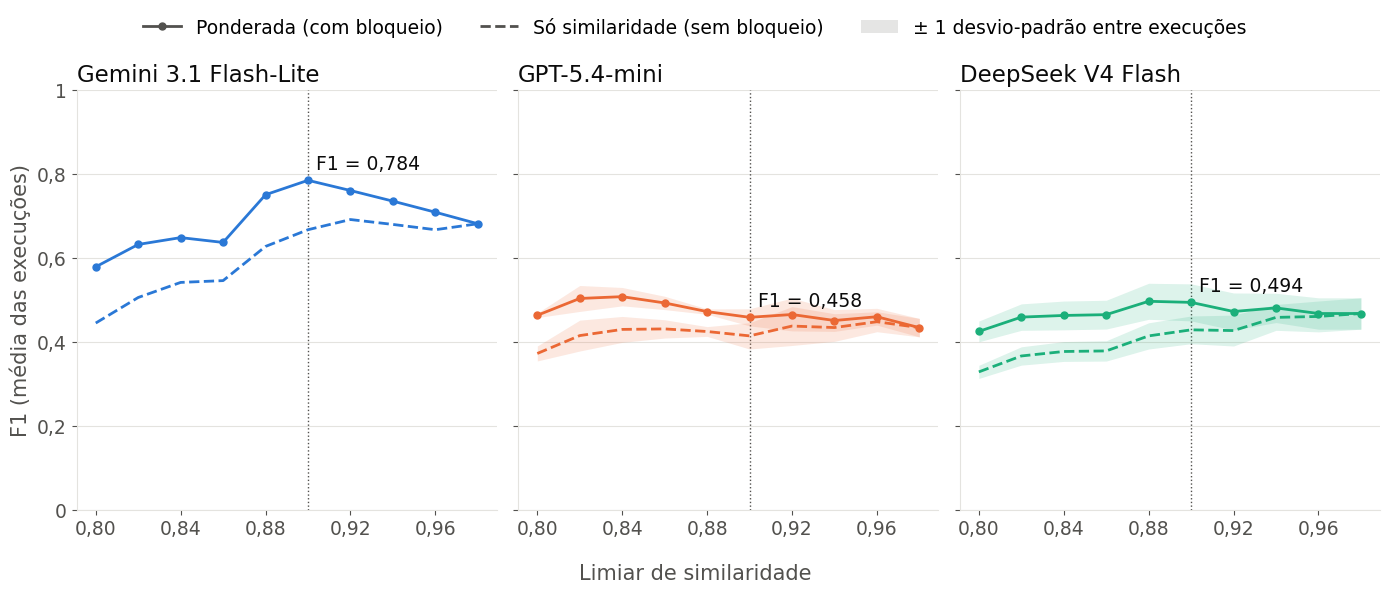

Salvo em: output\sec10\10_4_curva_limiar.csv e 10_4_curva_limiar.png


In [36]:
# ── 10.4 Curva do limiar ────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

LIMIARES = np.round(np.arange(0.80, 0.98 + 1e-9, 0.02), 2)
VARS_CURVA = {"com bloqueio": BLOQUEIOS, "só similaridade": []}

linhas = []
for modelo in MODELOS:
    for var, bl in VARS_CURVA.items():
        for thr in LIMIARES:
            ms = [metricas(df["label"], pred_ponderada(df, thr, bl)) for df in RUNS[modelo].values()]
            linha = dict(modelo=modelo, variante=var, limiar=float(thr))
            for k in _ks:
                linha[f"{k}_media"], linha[f"{k}_dp"] = media_dp([m[k] for m in ms])
            linhas.append(linha)
curva = pd.DataFrame(linhas)
curva.to_csv(SEC10_DIR / "10_4_curva_limiar.csv", index=False)

print("F1 (média das execuções) por limiar — variante ponderada com bloqueio")
display(curva[curva.variante == "com bloqueio"].pivot(index="limiar", columns="modelo", values="f1_media")[MODELOS].round(4))

resumo = []
for modelo in MODELOS:
    c = curva[(curva.modelo == modelo) & (curva.variante == "com bloqueio")].set_index("limiar")
    s = curva[(curva.modelo == modelo) & (curva.variante == "só similaridade")].set_index("limiar")
    viz = c.loc[0.86:0.94, "f1_media"]
    resumo.append({
        "modelo": modelo,
        "F1 @0,90": round(c.loc[0.90, "f1_media"], 4),
        "melhor limiar": c["f1_media"].idxmax(),
        "F1 máx": round(c["f1_media"].max(), 4),
        "máx − @0,90 (pp)": round(100 * (c["f1_media"].max() - c.loc[0.90, "f1_media"]), 1),
        "F1 mín–máx em [0,86; 0,94]": f"{viz.min():.3f}–{viz.max():.3f}",
        "F1 @0,90 só similaridade": round(s.loc[0.90, "f1_media"], 4),
        "F1 máx só similaridade": round(s["f1_media"].max(), 4),
    })
display(pd.DataFrame(resumo).set_index("modelo"))

# Figura: um painel por modelo; cor = modelo, traço = com/sem bloqueio.
CORES = {"Gemini 3.1 Flash-Lite": "#2a78d6", "GPT-5.4-mini": "#eb6834", "DeepSeek V4 Flash": "#1baf7a"}
TXT1, TXT2, GRADE = "#0b0b0b", "#52514e", "#e4e3df"

fig, axes = plt.subplots(1, len(MODELOS), figsize=(14, 5.4), sharey=True)
for ax, modelo in zip(axes, MODELOS):
    cor = CORES.get(modelo, TXT2)
    for var, estilo in [("com bloqueio", "-"), ("só similaridade", "--")]:
        sub = curva[(curva.modelo == modelo) & (curva.variante == var)]
        ax.plot(sub.limiar, sub.f1_media, estilo, color=cor, lw=2,
                marker="o" if estilo == "-" else None, ms=5, zorder=3)
        if (sub.f1_dp.fillna(0) > 0).any():
            ax.fill_between(sub.limiar, sub.f1_media - sub.f1_dp, sub.f1_media + sub.f1_dp,
                            color=cor, alpha=0.15, lw=0, zorder=2)
    ax.axvline(THR_PADRAO, color=TXT2, lw=1, ls=":", zorder=1)
    f90 = curva[(curva.modelo == modelo) & (curva.variante == "com bloqueio") & (curva.limiar == THR_PADRAO)].f1_media.iloc[0]
    ax.annotate(f"F1 = {br(f90)}", (THR_PADRAO, f90), xytext=(6, 8), textcoords="offset points",
                color=TXT1, fontsize=13.5)
    ax.set_title(modelo, loc="left", fontsize=16.5, color=TXT1)
    ax.set_xticks(LIMIARES[::2])
    ax.set_ylim(0, 1)
    ax.grid(axis="y", color=GRADE, lw=0.8)
    ax.set_axisbelow(True)
    for lado in ["top", "right"]:
        ax.spines[lado].set_visible(False)
    for lado in ["left", "bottom"]:
        ax.spines[lado].set_color(GRADE)
    ax.tick_params(colors=TXT2, labelsize=13.5)
    eixos_br(ax, x=False)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.2f}".replace(".", ",")))
axes[0].set_ylabel("F1 (média das execuções)", color=TXT2, fontsize=15)
fig.supxlabel("Limiar de similaridade", color=TXT2, fontsize=15)
from matplotlib.patches import Patch
fig.legend([Line2D([], [], color=TXT2, lw=2, marker="o", ms=5), Line2D([], [], color=TXT2, lw=2, ls="--"),
            Patch(facecolor=TXT2, alpha=0.15, lw=0)],
           ["Ponderada (com bloqueio)", "Só similaridade (sem bloqueio)", "± 1 desvio-padrão entre execuções"],
           loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.09), fontsize=13.5)
plt.tight_layout()
salva_figura(fig, "curva_limiar", SEC10_DIR / "10_4_curva_limiar.png")
plt.show()
print(f"Salvo em: {SEC10_DIR / '10_4_curva_limiar.csv'} e 10_4_curva_limiar.png")

#### 10.4b Limiar escolhido sem ver os dados de teste (validação cruzada)

A curva mostra a sensibilidade, mas o 0,90 continua escolhido olhando o conjunto inteiro. Para estimar o F1 **sem esse viés**, repetimos 200 vezes uma validação cruzada em 5 folds: em cada fold o limiar é escolhido (na grade 0,80–0,98) só com os outros 4 folds e aplicado ao fold de teste. Os folds são formados por **cluster de produto** (mesmo union-find de `revisao/gerar_numeros.py`), estratificados por clusters positivos, para que variantes do mesmo produto não fiquem dos dois lados. Se o F1 da validação cruzada ficar próximo do F1 @0,90, o limiar não é um ponto de sorte.

In [37]:
# ── 10.4b Validação cruzada do limiar ──────────────────────────────────────────
_rev = REPO_ROOT / "revisao"
if str(_rev) not in sys.path:
    sys.path.insert(0, str(_rev))
from gerar_numeros import _clusters

N_REP, K_FOLDS = 200, 5
_df0 = RUNS[MODELOS[0]][min(RUNS[MODELOS[0]])]
CID = _clusters(_df0["title_a"], _df0["title_b"], _df0["label"])
_pos_clusters = np.unique(CID[Y == 1])
_neg_clusters = np.setdiff1d(np.unique(CID), _pos_clusters)
print(f"{len(np.unique(CID))} clusters ({len(_pos_clusters)} com pares positivos)")


def _f1_vet(tp, fp, fn):
    d = 2 * tp + fp + fn
    return np.where(d > 0, 2 * tp / np.maximum(d, 1), 0.0)


def cv_limiar(df, n_rep=N_REP, k=K_FOLDS, seed=42):
    y = df["label"].values
    bloq = df[BLOQUEIOS].any(axis=1).values
    preds = (df["sim"].values[None, :] >= LIMIARES[:, None]) & ~bloq[None, :]     # (limiares, pares)
    tp_m, fp_m, fn_m = preds & (y == 1), preds & (y == 0), ~preds & (y == 1)
    rng = np.random.default_rng(seed)
    f1s, escolhidos = [], []
    for _ in range(n_rep):
        fold_do_cluster = np.empty(CID.max() + 1, int)
        for grupo in (_pos_clusters, _neg_clusters):            # estratificado: positivos espalhados nos folds
            g = rng.permutation(grupo)
            fold_do_cluster[g] = (np.arange(len(g)) + rng.integers(k)) % k
        fold = fold_do_cluster[CID]
        TP = FP = FN = 0
        for f in range(k):
            tr, te = fold != f, fold == f
            f1_tr = _f1_vet(tp_m[:, tr].sum(1), fp_m[:, tr].sum(1), fn_m[:, tr].sum(1))
            empates = np.flatnonzero(f1_tr == f1_tr.max())
            j = empates[len(empates) // 2]                      # empate -> limiar do meio (neutro)
            escolhidos.append(LIMIARES[j])
            TP += tp_m[j, te].sum(); FP += fp_m[j, te].sum(); FN += fn_m[j, te].sum()
        f1s.append(float(_f1_vet(TP, FP, FN)))
    return np.array(f1s), np.array(escolhidos)


linhas = []
for modelo in MODELOS:
    f1_runs, esc_runs = [], []
    for df in RUNS[modelo].values():
        f1s, esc = cv_limiar(df)
        f1_runs.append(f1s); esc_runs.append(esc)
    f1_all, esc_all = np.concatenate(f1_runs), np.concatenate(esc_runs)
    f1_90 = tab_media.query("modelo == @modelo and variante == 'Ponderada'").f1_media.iloc[0]
    vals, cont = np.unique(esc_all, return_counts=True)
    top = sorted(zip(cont, vals), reverse=True)[:3]
    linhas.append({
        "modelo": modelo,
        "F1 @0,90 (conjunto todo)": round(f1_90, 4),
        "F1 validação cruzada (média)": round(f1_all.mean(), 4),
        "faixa 2,5–97,5% das repetições (não é IC)": f"{np.percentile(f1_all, 2.5):.3f}–{np.percentile(f1_all, 97.5):.3f}",
        "diferença (pp)": round(100 * (f1_all.mean() - f1_90), 1),
        "limiares mais escolhidos": ", ".join(f"{v:.2f} ({c / len(esc_all):.0%})" for c, v in top),
    })
tab_cv = pd.DataFrame(linhas).set_index("modelo")
tab_cv.to_csv(SEC10_DIR / "10_4b_cv_limiar.csv")
print(f"{N_REP} repetições × {K_FOLDS} folds por execução, limiar escolhido só no treino")
display(tab_cv)
print(f"Salvo em: {SEC10_DIR / '10_4b_cv_limiar.csv'}")

1196 clusters (26 com pares positivos)


200 repetições × 5 folds por execução, limiar escolhido só no treino


,"F1 @0,90 (conjunto todo)",F1 validação cruzada (média),"faixa 2,5–97,5% das repetições (não é IC)",diferença (pp),limiares mais escolhidos
modelo,,,,,
Gemini 3.1 Flash-Lite,0.7843,0.7556,0.717–0.760,-2.9,"0.90 (78%), 0.92 (19%), 0.88 (2%)"
GPT-5.4-mini,0.4581,0.4495,0.371–0.514,-0.9,"0.84 (37%), 0.82 (32%), 0.86 (12%)"
DeepSeek V4 Flash,0.4936,0.4602,0.385–0.514,-3.3,"0.88 (60%), 0.90 (24%), 0.94 (8%)"


Salvo em: output\sec10\10_4b_cv_limiar.csv


### 10.5 Intervalos de confiança no Golden Set (AI-PAVE-Br)

Bootstrap **sobre os itens** do Golden Set (10.000 reamostragens, seed 42): cada item entra com todas as suas células de atributo, então a correlação entre atributos do mesmo produto é preservada. As três métricas são recomputadas com a mesma implementação de `revisao/pave_score.py` (P/R/F1 micro por token, equivalência de unidade aplicada aos três sistemas — a variante recomendada para o texto). As diferenças ΔF1 = TAIL − outro são **pareadas**: os três sistemas usam a mesma reamostragem.

Leitura: se o IC 95% de ΔF1 contém 0, não há diferença estatística (“empata”); se está todo abaixo de 0, o TAIL “fica abaixo”.

Requer `revisao/pave/gold_longo.csv` e `revisao/pave/tail_pred.jsonl` (gerados por `pave_dataset.py` e `pave_extract.py`; não versionados por licença).

In [38]:
# ── 10.5 IC bootstrap no Golden Set ────────────────────────────────────────────
import csv as _csv
_rev = REPO_ROOT / "revisao"
if str(_rev) not in sys.path:
    sys.path.insert(0, str(_rev))
import pave_score as ps

N_BOOT, SEED_BOOT, CHUNK = 10_000, 42, 500
_gold_path, _tail_path = ps.PAVE / "gold_longo.csv", ps.PAVE / "tail_pred.jsonl"

if not (_gold_path.is_file() and _tail_path.is_file()):
    print(f"[SKIP] faltam {_gold_path} e/ou {_tail_path}. Rode revisao/pave_dataset.py e pave_extract.py.")
else:
    with _gold_path.open(encoding="utf-8") as fh:
        longo = list(_csv.DictReader(fh))
    tail = ps.carrega_tail(_tail_path)
    aval = [r for r in longo if r["atributo"] in ps.GOLD2TAIL and r["item_uid"] in tail and not ps.eh_nulo(r["gold"])]
    ESCOPOS = {
        "schema alinhado":             [r for r in aval if r["atributo"] not in ps.NAO_MODELADOS],
        "todos os atributos mapeados": aval,
    }
    SISTEMAS = {
        "TAIL (Gemini 3.1 Flash-Lite)":  lambda r: tail[r["item_uid"]].get(ps.GOLD2TAIL[r["atributo"]]),
        "AI-PAVE-Br (Gemini 1.5 Flash)": lambda r: r["pred_llm"],
        "Baseline empresa terceira":     lambda r: r["pred_ol"],
    }
    TAIL_NOME = "TAIL (Gemini 3.1 Flash-Lite)"

    def contagens_por_item(dados, fn, itens_idx, n_itens):
        """tp, fp, fn, células avaliadas e células não vazias, somados por item."""
        acc = np.zeros((5, n_itens))
        for r in dados:
            g, p = ps.tokens(r["gold"], True), ps.tokens(fn(r), True)
            inter = sum((g & p).values())
            i = itens_idx[r["item_uid"]]
            acc[:, i] += (inter, sum(p.values()) - inter, sum(g.values()) - inter, 1, 0 if ps.eh_nulo(fn(r)) else 1)
        return acc

    def _prf(tp, fp, fn):
        P = np.where(tp + fp > 0, tp / np.maximum(tp + fp, 1e-12), 0.0)
        R = np.where(tp + fn > 0, tp / np.maximum(tp + fn, 1e-12), 0.0)
        F = np.where(P + R > 0, 2 * P * R / np.maximum(P + R, 1e-12), 0.0)
        return P, R, F

    ic = lambda a: (float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5)))
    linhas_sis, linhas_delta = [], []

    for escopo, dados in ESCOPOS.items():
        uids = sorted({r["item_uid"] for r in dados})
        idx = {u: i for i, u in enumerate(uids)}
        k = len(uids)
        C = {s: contagens_por_item(dados, fn, idx, k) for s, fn in SISTEMAS.items()}

        # Conferência: o somatório bate com ps.pontua (mesma métrica do T4)
        for s, fn in SISTEMAS.items():
            ref = ps.pontua(((r["gold"], fn(r)) for r in dados), True)
            assert (int(C[s][0].sum()), int(C[s][1].sum()), int(C[s][2].sum())) == (ref["tp"], ref["fp"], ref["fn"]), s

        # Reamostragem multinomial dos itens (pareada: mesmos pesos para os três sistemas)
        rng = np.random.default_rng(SEED_BOOT)
        boot = {s: {m: [] for m in ["P", "R", "F", "cov"]} for s in SISTEMAS}
        for ini in range(0, N_BOOT, CHUNK):
            W = rng.multinomial(k, np.full(k, 1 / k), size=min(CHUNK, N_BOOT - ini)).astype(float)
            for s in SISTEMAS:
                tp, fp, fn_, nav, nnv = (W @ C[s][j] for j in range(5))
                P, R, F = _prf(tp, fp, fn_)
                for m, v in zip(["P", "R", "F", "cov"], [P, R, F, nnv / nav]):
                    boot[s][m].append(v)
        boot = {s: {m: np.concatenate(v) for m, v in d.items()} for s, d in boot.items()}

        for s in SISTEMAS:
            tp, fp, fn_, nav, nnv = C[s].sum(axis=1)
            P, R, F = (float(x) for x in _prf(tp, fp, fn_))
            linhas_sis.append(dict(escopo=escopo, sistema=s, n_itens=k, n_celulas=int(nav),
                                   precision=P, precision_ci=ic(boot[s]["P"]),
                                   recall=R, recall_ci=ic(boot[s]["R"]),
                                   f1=F, f1_ci=ic(boot[s]["F"]),
                                   coverage=float(nnv / nav), coverage_ci=ic(boot[s]["cov"])))
        F_obs = {l["sistema"]: l for l in linhas_sis if l["escopo"] == escopo}
        for outro in SISTEMAS:
            if outro == TAIL_NOME:
                continue
            row = dict(escopo=escopo, comparacao=f"TAIL − {outro}")
            for m, chave in [("F", "f1"), ("P", "precision"), ("R", "recall")]:
                d = boot[TAIL_NOME][m] - boot[outro][m]
                row[f"delta_{chave}_pp"] = 100 * (F_obs[TAIL_NOME][chave] - F_obs[outro][chave])
                row[f"delta_{chave}_ci_pp"] = tuple(100 * x for x in ic(d))
            lo, hi = row["delta_f1_ci_pp"]
            row["P(ΔF1 > 0)"] = float((boot[TAIL_NOME]["F"] - boot[outro]["F"] > 0).mean())
            row["leitura"] = ("empata (IC contém 0)" if lo <= 0 <= hi
                              else "TAIL acima" if lo > 0 else "TAIL abaixo")
            linhas_delta.append(row)

    f_ic = lambda v, c, mult=1, casas=3: f"{mult*v:.{casas}f} [{mult*c[0]:.{casas}f}; {mult*c[1]:.{casas}f}]"
    tab_sis = pd.DataFrame(linhas_sis)
    tab_delta = pd.DataFrame(linhas_delta)

    print(f"Golden Set: {len(tail)} itens extraídos; bootstrap de {N_BOOT} reamostragens sobre itens (equivalência de unidade)\n")
    display(pd.DataFrame({
        "Escopo": tab_sis.escopo, "Sistema": tab_sis.sistema, "itens": tab_sis.n_itens, "células": tab_sis.n_celulas,
        "Precisão [IC95%]": [f_ic(r.precision, r.precision_ci) for r in tab_sis.itertuples()],
        "Recall [IC95%]":   [f_ic(r.recall, r.recall_ci) for r in tab_sis.itertuples()],
        "F1 [IC95%]":       [f_ic(r.f1, r.f1_ci) for r in tab_sis.itertuples()],
        "Cobertura [IC95%]": [f_ic(r.coverage, r.coverage_ci, 100, 1) for r in tab_sis.itertuples()],
    }))
    print("Diferenças pareadas (pp)")
    display(pd.DataFrame({
        "Escopo": tab_delta.escopo, "Comparação": tab_delta.comparacao,
        "ΔF1 [IC95%]": [f"{r.delta_f1_pp:+.1f} [{r.delta_f1_ci_pp[0]:+.1f}; {r.delta_f1_ci_pp[1]:+.1f}]" for r in tab_delta.itertuples()],
        "ΔPrecisão [IC95%]": [f"{r.delta_precision_pp:+.1f} [{r.delta_precision_ci_pp[0]:+.1f}; {r.delta_precision_ci_pp[1]:+.1f}]" for r in tab_delta.itertuples()],
        "ΔRecall [IC95%]": [f"{r.delta_recall_pp:+.1f} [{r.delta_recall_ci_pp[0]:+.1f}; {r.delta_recall_ci_pp[1]:+.1f}]" for r in tab_delta.itertuples()],
        "P(ΔF1>0)": tab_delta["P(ΔF1 > 0)"].round(3),
        "Leitura": tab_delta.leitura,
    }))

    def _achata(t):
        """Colunas (lo, hi) viram duas colunas _lo/_hi no CSV."""
        t = t.copy()
        for c in [c for c in t.columns if isinstance(t[c].iloc[0], tuple)]:
            t[f"{c}_lo"], t[f"{c}_hi"] = zip(*t.pop(c))
        return t
    _achata(tab_sis).to_csv(SEC10_DIR / "10_5_goldenset_ic_sistemas.csv", index=False)
    _achata(tab_delta).to_csv(SEC10_DIR / "10_5_goldenset_ic_deltas.csv", index=False)
    print(f"Salvo em: {SEC10_DIR / '10_5_goldenset_ic_sistemas.csv'} e 10_5_goldenset_ic_deltas.csv")

Golden Set: 7890 itens extraídos; bootstrap de 10000 reamostragens sobre itens (equivalência de unidade)



,Escopo,Sistema,itens,células,Precisão [IC95%],Recall [IC95%],F1 [IC95%],Cobertura [IC95%]
0,schema alinhado,TAIL (Gemini 3.1 Flash-Lite),7351,18677,0.845 [0.838; 0.852],0.537 [0.529; 0.546],0.657 [0.650; 0.664],65.1 [64.4; 65.9]
1,schema alinhado,AI-PAVE-Br (Gemini 1.5 Flash),7351,18677,0.778 [0.771; 0.785],0.602 [0.594; 0.610],0.679 [0.672; 0.685],77.6 [77.0; 78.3]
2,schema alinhado,Baseline empresa terceira,7351,18677,0.851 [0.845; 0.857],0.529 [0.520; 0.537],0.652 [0.645; 0.660],66.8 [65.9; 67.6]
3,todos os atributos mapeados,TAIL (Gemini 3.1 Flash-Lite),7363,23765,0.799 [0.792; 0.806],0.438 [0.431; 0.445],0.566 [0.559; 0.572],57.4 [56.7; 58.1]
4,todos os atributos mapeados,AI-PAVE-Br (Gemini 1.5 Flash),7363,23765,0.782 [0.775; 0.789],0.550 [0.543; 0.556],0.646 [0.640; 0.652],76.4 [75.9; 77.0]
5,todos os atributos mapeados,Baseline empresa terceira,7363,23765,0.861 [0.856; 0.867],0.456 [0.448; 0.464],0.596 [0.589; 0.604],58.6 [57.8; 59.4]


Diferenças pareadas (pp)


,Escopo,Comparação,ΔF1 [IC95%],ΔPrecisão [IC95%],ΔRecall [IC95%],P(ΔF1>0),Leitura
0,schema alinhado,TAIL − AI-PAVE-Br (Gemini 1.5 Flash),-2.2 [-2.8; -1.6],+6.7 [+5.9; +7.5],-6.5 [-7.1; -5.8],0.000,TAIL abaixo
1,schema alinhado,TAIL − Baseline empresa terceira,+0.5 [-0.3; +1.3],-0.6 [-1.4; +0.2],+0.9 [-0.1; +1.8],0.866,empata (IC contém 0)
2,todos os atributos mapeados,TAIL − AI-PAVE-Br (Gemini 1.5 Flash),-8.0 [-8.5; -7.4],+1.7 [+0.9; +2.5],-11.2 [-11.8; -10.6],0.000,TAIL abaixo
3,todos os atributos mapeados,TAIL − Baseline empresa terceira,-3.1 [-3.9; -2.2],-6.2 [-7.0; -5.4],-1.8 [-2.7; -0.9],0.000,TAIL abaixo


Salvo em: output\sec10\10_5_goldenset_ic_sistemas.csv e 10_5_goldenset_ic_deltas.csv


## 11. Rodadas de hoje: referência nova e ablação do pipeline (três modelos)

**Por que uma referência nova.** Os modelos mudaram desde agosto: o mesmo pipeline rodado hoje não reproduz os CSVs do artigo (Gemini: só 70% dos nomes canônicos iguais). Por isso cada ablação é comparada com a **referência do mesmo dia, do mesmo modelo** — nunca com os números de agosto. A célula 11.2 mede a deriva separadamente.

**Desenho.** Mesmo protocolo de cada modelo no `classifier_api.ipynb` (template, formato JSON, temperatura 0, 2.048 tokens, lotes de 5, 2.257 títulos únicos = 452 chamadas por rodada):

| Modelo | Execuções da referência | Execuções de (a) e (c) | Por quê |
|---|---|---|---|
| Gemini 3.1 Flash-Lite | 3 | 1 | determinístico (Seção 9); as 3 execuções da referência confirmam isso hoje |
| GPT-5.4-mini | 5 | 3 | varia 2–4 pp de F1 entre execuções idênticas |
| DeepSeek V4 Flash | 5 | 3 | idem |

A variante (b) sai do JSON cru de cada execução da referência, então tem o mesmo número de execuções dela. As execuções extras da referência servem também para medir a instabilidade de hoje (11.2b).

| Variante | Pré-normalização | Prompt | Pós-processamento | Chamadas |
|---|---|---|---|---|
| **completa** (referência) | sim | completo | sim | sim |
| **(a) sem pré** | não (título bruto, sem hash) | completo | sim | sim |
| **(b) sem pós** | sim | completo | **não** (nome montado do JSON cru, sem `clean_llm_output`) | **não** — sai do JSON cru da completa, execução por execução |
| **(c) sem regras 5–9** | sim | sem os blocos “limpeza” (5–7) e “desambiguação” (8–9) | sim | sim |

**Estatística.** Para modelos com 3 execuções, o F1 de uma variante é a média das execuções. ΔF1 = F1(variante) − F1(completa), com IC 95% por bootstrap pareado sobre clusters de produto (10.000 reamostragens; a mesma reamostragem vale para todas as execuções dos dois lados). O desvio-padrão entre execuções é reportado ao lado, para separar efeito de ruído.

Código em `grupo2.py`; respostas em `dados/grupo2/*.jsonl` (re-executar não repete chamadas). Fora do notebook: `python grupo2.py plano`. Requer a célula 10.0 executada.

In [39]:
# ── 11.1 Execução (com cache) e resumo das rodadas ─────────────────────────────
import importlib
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
_rev = REPO_ROOT / "revisao"
if str(_rev) not in sys.path:
    sys.path.insert(0, str(_rev))
import grupo2 as g2
importlib.reload(g2)
from gerar_numeros import paired_bootstrap, mcnemar, _clusters

EXECUTAR_API = False    # False = usa só o cache. True roda em paralelo o que faltar (horas, se tudo faltar).
MODELOS_G2 = list(g2.MODELOS)                                  # gemini, gpt, deepseek
NOME_G2 = {m: g2.MODELOS[m]["nome"] for m in MODELOS_G2}
CORES_G2 = {"gemini": "#2a78d6", "gpt": "#eb6834", "deepseek": "#1baf7a"}
EXEC_REF = {m: list(range(1, g2.MODELOS[m]["execucoes_referencia"] + 1)) for m in MODELOS_G2}
EXEC_ABL = {m: list(range(1, g2.MODELOS[m]["execucoes"] + 1)) for m in MODELOS_G2}
execucoes_de = lambda m, rodada: EXEC_REF[m] if rodada in ("completa", "sem_pos") else EXEC_ABL[m]

if EXECUTAR_API:
    g2.executar_plano(MODELOS_G2)

df_pares_g2 = g2.load_pairs()

# Só entram execuções completas (ex.: se a API parar no meio de uma rodada, ela fica de fora até ser retomada).
_completa = lambda m, rod, r: (lambda res: res["lotes_respondidos"] == res["lotes_total"])(g2.raw_por_titulo(m, rod, r, df_pares_g2)[1])
for _m in MODELOS_G2:
    _fora = [r for r in EXEC_REF[_m] if not _completa(_m, "completa", r)]
    if _fora:
        print(f"[AVISO] {NOME_G2[_m]}: execuções da referência incompletas, fora da análise: {_fora} "
              f"(rode de novo com EXECUTAR_API = Falsepara completá-las)")
    EXEC_REF[_m] = [r for r in EXEC_REF[_m] if r not in _fora]
artigo_g = RUNS["Gemini 3.1 Flash-Lite"][min(RUNS["Gemini 3.1 Flash-Lite"])]
assert (df_pares_g2["label"].values == Y).all() and (df_pares_g2["title_a"].values == artigo_g["title_a"].values).all()
CID = _clusters(artigo_g["title_a"], artigo_g["title_b"], artigo_g["label"])

linhas = []
for m in MODELOS_G2:
    for rod in g2.RODADAS_ABLACAO:
        for r in execucoes_de(m, rod):
            _, res = g2.raw_por_titulo(m, rod, r, df_pares_g2)
            linhas.append({"modelo": NOME_G2[m], "rodada": rod, "exec.": r,
                           "lotes": f"{res['lotes_respondidos']}/{res['lotes_total']}",
                           "bloqueados": res["lotes_bloqueados"], "títulos sem JSON": res["titulos_sem_json"],
                           "tokens entrada": res["tokens_entrada"], "tokens saída": res["tokens_saida"]})
tab_rodadas = pd.DataFrame(linhas)
tab_rodadas.to_csv(SEC10_DIR.parent / "sec11_rodadas.csv", index=False)
_incompletas = tab_rodadas[tab_rodadas["lotes"].map(lambda s: s.split("/")[0] != s.split("/")[1])]
print(f"{len(tab_rodadas)} rodadas de normalização; incompletas: {len(_incompletas)}")
display(tab_rodadas.groupby(["modelo", "rodada"]).agg(execuções=("exec.", "count"), bloqueados=("bloqueados", "sum"),
        **{"títulos sem JSON (soma)": ("títulos sem JSON", "sum"), "tokens entrada": ("tokens entrada", "sum"),
           "tokens saída": ("tokens saída", "sum")}))
if len(_incompletas):
    display(_incompletas)

27 rodadas de normalização; incompletas: 0


execuções  bloqueados  \
modelo                rodada                                  
DeepSeek V4 Flash     completa                5           0   
                      sem_pre                 3           0   
                      sem_regras_5_9          3           0   
GPT-5.4-mini          completa                5           0   
                      sem_pre                 3           0   
                      sem_regras_5_9          3           0   
Gemini 3.1 Flash-Lite completa                3           3   
                      sem_pre                 1           1   
                      sem_regras_5_9          1           1   

                                      títulos sem JSON (soma)  tokens entrada  \
modelo                rodada                                                    
DeepSeek V4 Flash     completa                              0         3185955   
                      sem_pre                               0         1912101   
                      sem_regras_5_9                        0         1168485   
GPT-5.4-mini          completa                              0         2707340   
                      sem_pre                               0         1625100   
                      sem_regras_5_9                        0          992508   
Gemini 3.1 Flash-Lite completa                             15         1877346   
                      sem_pre                               5          625878   
                      sem_regras_5_9                        5          390290   

                                      tokens saída  
modelo                rodada                        
DeepSeek V4 Flash     completa             1025532  
                      sem_pre               612186  
                      sem_regras_5_9        619479  
GPT-5.4-mini          completa              680384  
                      sem_pre               410207  
                      sem_regras_5_9        395806  
Gemini 3.1 Flash-Lite completa              695481  
                      sem_pre               231822  
                      sem_regras_5_9        233157

In [40]:
# ── 11.2 Referência de hoje × agosto (deriva dos modelos) ──────────────────────
def prepara_pares(df: pd.DataFrame) -> pd.DataFrame:
    """Mesmo preparo da 10.0: decompõe a regra ponderada e gera pred_exact / pred_weighted."""
    df = df.copy().reset_index(drop=True)
    for c in ["item_a_normalized", "item_b_normalized", "a_quantidade", "b_quantidade"]:
        df[c] = df[c].fillna("").astype(str) if c in df.columns else ""
    df["label"] = df["label"].astype(int)
    dec = pd.DataFrame([decompoe_par(a, b, qa, qb) for a, b, qa, qb in
                        zip(df["item_a_normalized"], df["item_b_normalized"], df["a_quantidade"], df["b_quantidade"])])
    df = pd.concat([df.drop(columns=[c for c in dec.columns if c in df.columns]), dec], axis=1)
    df["pred_exact"] = df["exact"].astype(int)
    df["pred_weighted"] = pred_ponderada(df)
    return df


def canon_por_titulo(df: pd.DataFrame) -> dict:
    """{título: nome canônico}. Chave = título SEM o sufixo de hash ('#abcd'), que é o que o
    LLM recebe: 2.257 títulos únicos (com o hash seriam 2.267, contando 10 títulos duas vezes)."""
    m = dict(zip(df["title_a"].map(g2.strip_hash), df["item_a_normalized"]))
    m.update(zip(df["title_b"].map(g2.strip_hash), df["item_b_normalized"]))
    return m


VAR_DESC = {"completa": "Completa (referência de hoje)", "sem_pre": "(a) Sem pré-normalização",
            "sem_pos": "(b) Sem pós-processamento", "sem_regras_5_9": "(c) Prompt sem as regras 5–9"}
# HOJE[modelo][variante] = lista de DataFrames (uma por execução)
HOJE = {m: {v: [prepara_pares(g2.pares_variante(m, v, r, df_pares_g2)[0]) for r in execucoes_de(m, v)] for v in VAR_DESC}
        for m in MODELOS_G2}
AGOSTO = {m: list(RUNS[NOME_G2[m]].values()) for m in MODELOS_G2}
for m in MODELOS_G2:
    for v in VAR_DESC:
        for d in HOJE[m][v]:
            assert (d["label"].values == Y).all() and (d["title_a"].values == artigo_g["title_a"].values).all()

linhas = []
for m in MODELOS_G2:
    hj, ag = HOJE[m]["completa"], AGOSTO[m]
    f_hj, b_hj = g2.f1_boot(Y, [d["pred_weighted"].values for d in hj], CID)
    f_ag, b_ag = g2.f1_boot(Y, [d["pred_weighted"].values for d in ag], CID)
    sd = lambda L: np.std([metricas(Y, d["pred_weighted"])["f1"] for d in L], ddof=1) if len(L) > 1 else float("nan")
    lo, hi = g2.ic95(b_hj - b_ag)
    c_hj, c_ag0 = canon_por_titulo(hj[0]), canon_por_titulo(ag[0])
    c_ag1 = canon_por_titulo(ag[1]) if len(ag) > 1 else c_ag0
    linhas.append({
        "modelo": NOME_G2[m],
        "F1 pond. agosto (média ± dp)": fmt_md(f_ag, sd(ag)),
        "F1 pond. hoje (média ± dp)": fmt_md(f_hj, sd(hj)),
        "Δ hoje − agosto [IC95%] (pp)": f"{100*(f_hj-f_ag):+.1f} [{100*lo:+.1f}; {100*hi:+.1f}]",
        "nomes iguais hoje×agosto (exec. 1)": f"{np.mean([c_hj[t] == c_ag0[t] for t in c_hj]):.1%}",
        "nomes iguais agosto×agosto (exec. 1×2)": f"{np.mean([c_ag0[t] == c_ag1[t] for t in c_ag0]):.1%}",
    })
tab_deriva = pd.DataFrame(linhas).set_index("modelo")
tab_deriva.to_csv(SEC10_DIR.parent / "sec11_deriva.csv")
print("Variante ponderada. 'agosto×agosto' mostra o ruído normal entre execuções da época; se 'hoje×agosto' for bem menor, houve deriva.")
display(tab_deriva)

Variante ponderada. 'agosto×agosto' mostra o ruído normal entre execuções da época; se 'hoje×agosto' for bem menor, houve deriva.


,F1 pond. agosto (média ± dp),F1 pond. hoje (média ± dp),Δ hoje − agosto [IC95%] (pp),nomes iguais hoje×agosto (exec. 1),nomes iguais agosto×agosto (exec. 1×2)
modelo,,,,,
Gemini 3.1 Flash-Lite,0.784 ± 0.000,0.745 ± 0.000,-3.9 [-12.1; +2.5],69.8%,100.0%
GPT-5.4-mini,0.458 ± 0.020,0.473 ± 0.043,+1.5 [-7.4; +11.0],60.2%,64.3%
DeepSeek V4 Flash,0.494 ± 0.044,0.566 ± 0.026,+7.2 [-4.0; +18.3],29.9%,80.4%


Variante ponderada. 'títulos estáveis (3 primeiras)' é a medida comparável com agosto (3 execuções);
'concordância média entre 2 execuções' não depende do número de execuções.


execuções títulos estáveis (todas)  \
modelo                quando                                       
Gemini 3.1 Flash-Lite agosto          3                   100.0%   
                      hoje            3                   100.0%   
GPT-5.4-mini          agosto          3                    52.5%   
                      hoje            5                    42.5%   
DeepSeek V4 Flash     agosto          3                    72.2%   
                      hoje            5                    64.3%   

                             títulos estáveis (3 primeiras)  \
modelo                quando                                  
Gemini 3.1 Flash-Lite agosto                         100.0%   
                      hoje                           100.0%   
GPT-5.4-mini          agosto                          52.5%   
                      hoje                            53.6%   
DeepSeek V4 Flash     agosto                          72.2%   
                      hoje                            72.5%   

                             concordância média entre 2 execuções  \
modelo                quando                                        
Gemini 3.1 Flash-Lite agosto                               100.0%   
                      hoje                                 100.0%   
GPT-5.4-mini          agosto                                64.9%   
                      hoje                                  66.0%   
DeepSeek V4 Flash     agosto                                80.5%   
                      hoje                                  80.6%   

                             pares com mesma predição (todas)  \
modelo                quando                                    
Gemini 3.1 Flash-Lite agosto                           100.0%   
                      hoje                             100.0%   
GPT-5.4-mini          agosto                            98.8%   
                      hoje                              98.0%   
DeepSeek V4 Flash     agosto                            98.2%   
                      hoje                              98.4%   

                              pares instáveis  positivos instáveis  \
modelo                quando                                         
Gemini 3.1 Flash-Lite agosto                0                    0   
                      hoje                  0                    0   
GPT-5.4-mini          agosto               15                    6   
                      hoje                 24                    7   
DeepSeek V4 Flash     agosto               22                    5   
                      hoje                 19                    2   

                                                  F1 por execução  \
modelo                quando                                        
Gemini 3.1 Flash-Lite agosto                [0.784, 0.784, 0.784]   
                      hoje                  [0.745, 0.745, 0.745]   
GPT-5.4-mini          agosto                [0.448, 0.481, 0.444]   
                      hoje    [0.483, 0.444, 0.533, 0.421, 0.483]   
DeepSeek V4 Flash     agosto                [0.444, 0.529, 0.507]   
                      hoje     [0.603, 0.559, 0.551, 0.537, 0.58]   

                              F1 média ± dp   F1 mín–máx  
modelo                quando                              
Gemini 3.1 Flash-Lite agosto  0.784 ± 0.000  0.784–0.784  
                      hoje    0.745 ± 0.000  0.745–0.745  
GPT-5.4-mini          agosto  0.458 ± 0.020  0.444–0.481  
                      hoje    0.473 ± 0.043  0.421–0.533  
DeepSeek V4 Flash     agosto  0.494 ± 0.044  0.444–0.529  
                      hoje    0.566 ± 0.026  0.537–0.603

Gemini hoje: 3 execuções com nomes canônicos IDÊNTICOS em todos os títulos.


Figura salva em: figuras_tcc\instabilidade.pdf e .png (300 dpi)


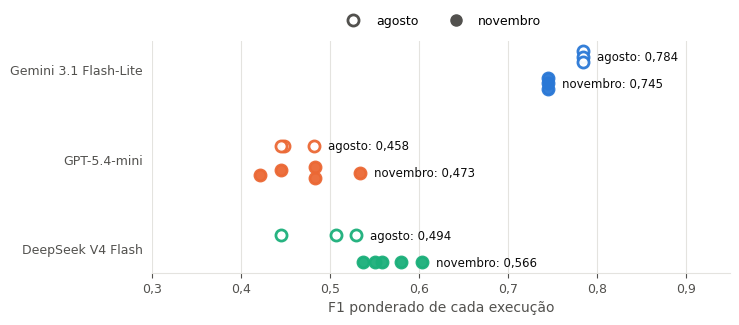

Salvo em: output\sec11_instabilidade.csv e sec11_instabilidade.png


In [41]:
# ── 11.2b Instabilidade entre execuções: hoje × agosto ─────────────────────────
from itertools import combinations


def perfil_instabilidade(dfs: list) -> dict:
    canons = [canon_por_titulo(d) for d in dfs]
    titulos = list(canons[0])
    P = np.array([d["pred_weighted"].values for d in dfs])
    f1s = [metricas(Y, p)["f1"] for p in P]
    estavel = lambda cs: np.mean([len({c[t] for c in cs}) == 1 for t in titulos])
    instaveis = ~(P == P[0]).all(axis=0)
    return {
        "execuções": len(dfs),
        "títulos estáveis (todas)": estavel(canons),
        "títulos estáveis (3 primeiras)": estavel(canons[:3]) if len(dfs) >= 3 else np.nan,
        "concordância média entre 2 execuções": np.mean([np.mean([a[t] == b[t] for t in titulos])
                                                          for a, b in combinations(canons, 2)]),
        "pares com mesma predição (todas)": 1 - instaveis.mean(),
        "pares instáveis": int(instaveis.sum()),
        "positivos instáveis": int((instaveis & (Y == 1)).sum()),
        "F1 por execução": [round(f, 3) for f in f1s],
        "F1 média ± dp": fmt_md(np.mean(f1s), np.std(f1s, ddof=1) if len(f1s) > 1 else float("nan")),
        "F1 mín–máx": f"{min(f1s):.3f}–{max(f1s):.3f}",
        "_f1s": f1s,
    }


linhas = []
for m in MODELOS_G2:
    for quando, dfs in [("agosto", AGOSTO[m]), ("hoje", HOJE[m]["completa"])]:
        linhas.append({"modelo": NOME_G2[m], "quando": quando, **perfil_instabilidade(dfs)})
tab_inst = pd.DataFrame(linhas)
tab_inst.drop(columns=["_f1s"]).to_csv(SEC10_DIR.parent / "sec11_instabilidade.csv", index=False)
_pct = ["títulos estáveis (todas)", "títulos estáveis (3 primeiras)", "concordância média entre 2 execuções",
        "pares com mesma predição (todas)"]
vis = tab_inst.drop(columns=["_f1s"]).copy()
for c in _pct:
    vis[c] = vis[c].map(lambda v: "—" if pd.isna(v) else f"{v:.1%}")
print("Variante ponderada. 'títulos estáveis (3 primeiras)' é a medida comparável com agosto (3 execuções);")
print("'concordância média entre 2 execuções' não depende do número de execuções.")
display(vis.set_index(["modelo", "quando"]))

for m in MODELOS_G2:
    hj = HOJE[m]["completa"]
    iguais = all((canon_por_titulo(d) == canon_por_titulo(hj[0])) for d in hj[1:])
    if m == "gemini":
        print(f"Gemini hoje: {len(hj)} execuções com nomes canônicos {'IDÊNTICOS' if iguais else 'DIFERENTES'} em todos os títulos.")

# Figura: F1 de cada execução, agosto × novembro
ROTULO_PERIODO = {"agosto": "agosto", "hoje": "novembro"}
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for i, m in enumerate(MODELOS_G2):
    for j, quando in enumerate(["agosto", "hoje"]):
        f1s = tab_inst[(tab_inst.modelo == NOME_G2[m]) & (tab_inst.quando == quando)]["_f1s"].iloc[0]
        yv = i + (j - 0.5) * 0.3
        jit = np.linspace(-0.06, 0.06, len(f1s)) if len(set(np.round(f1s, 4))) < len(f1s) else np.zeros(len(f1s))
        ax.plot(f1s, yv + jit, "o", ms=8, color=CORES_G2[m], mfc="white" if quando == "agosto" else CORES_G2[m],
                mew=2, alpha=0.95, zorder=3)
        ax.annotate(f"{ROTULO_PERIODO[quando]}: {br(np.mean(f1s))}", (max(f1s), yv), xytext=(10, -3), textcoords="offset points",
                    fontsize=8.5, color=TXT1)
ax.set_yticks(range(len(MODELOS_G2)))
ax.set_yticklabels([NOME_G2[m] for m in MODELOS_G2], color=TXT1, fontsize=9.5)
ax.invert_yaxis()
ax.set_xlim(0.3, 0.95)
ax.set_xlabel("F1 ponderado de cada execução", color=TXT2)
ax.grid(axis="x", color=GRADE, lw=0.8); ax.set_axisbelow(True)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color(GRADE)
ax.tick_params(colors=TXT2, labelsize=9, left=False)
eixos_br(ax, y=False)
ax.legend([Line2D([], [], marker="o", ls="", color=TXT2, mfc="white", mew=2, ms=8),
           Line2D([], [], marker="o", ls="", color=TXT2, ms=8)], ["agosto", "novembro"],
          frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, 1.16), ncol=2)
plt.tight_layout()
salva_figura(fig, "instabilidade", SEC10_DIR.parent / "sec11_instabilidade.png")
plt.show()
print(f"Salvo em: {SEC10_DIR.parent / 'sec11_instabilidade.csv'} e sec11_instabilidade.png")

execuções  \
modelo                variante                                   
Gemini 3.1 Flash-Lite Completa (referência de hoje)          3   
                      (a) Sem pré-normalização               1   
                      (b) Sem pós-processamento              3   
                      (c) Prompt sem as regras 5–9           1   
GPT-5.4-mini          Completa (referência de hoje)          5   
                      (a) Sem pré-normalização               3   
                      (b) Sem pós-processamento              5   
                      (c) Prompt sem as regras 5–9           3   
DeepSeek V4 Flash     Completa (referência de hoje)          5   
                      (a) Sem pré-normalização               3   
                      (b) Sem pós-processamento              5   
                      (c) Prompt sem as regras 5–9           3   

                                                    VP/FP/FN (média)  \
modelo                variante                                         
Gemini 3.1 Flash-Lite Completa (referência de hoje)    19.0/2.0/11.0   
                      (a) Sem pré-normalização         18.0/3.0/12.0   
                      (b) Sem pós-processamento        19.0/4.0/11.0   
                      (c) Prompt sem as regras 5–9     18.0/7.0/12.0   
GPT-5.4-mini          Completa (referência de hoje)   13.6/13.8/16.4   
                      (a) Sem pré-normalização        14.7/14.7/15.3   
                      (b) Sem pós-processamento       13.2/11.6/16.8   
                      (c) Prompt sem as regras 5–9    13.7/14.3/16.3   
DeepSeek V4 Flash     Completa (referência de hoje)   19.0/18.2/11.0   
                      (a) Sem pré-normalização        19.0/16.7/11.0   
                      (b) Sem pós-processamento       18.6/17.8/11.4   
                      (c) Prompt sem as regras 5–9    18.3/14.3/11.7   

                                                    F1 pond. (média ± dp)  \
modelo                variante                                              
Gemini 3.1 Flash-Lite Completa (referência de hoje)         0.745 ± 0.000   
                      (a) Sem pré-normalização                      0.706   
                      (b) Sem pós-processamento             0.717 ± 0.000   
                      (c) Prompt sem as regras 5–9                  0.655   
GPT-5.4-mini          Completa (referência de hoje)         0.473 ± 0.043   
                      (a) Sem pré-normalização              0.494 ± 0.029   
                      (b) Sem pós-processamento             0.480 ± 0.038   
                      (c) Prompt sem as regras 5–9          0.472 ± 0.040   
DeepSeek V4 Flash     Completa (referência de hoje)         0.566 ± 0.026   
                      (a) Sem pré-normalização              0.578 ± 0.022   
                      (b) Sem pós-processamento             0.561 ± 0.026   
                      (c) Prompt sem as regras 5–9          0.585 ± 0.045   

                                                     F1 exact (média)  \
modelo                variante                                          
Gemini 3.1 Flash-Lite Completa (referência de hoje)            0.6222   
                      (a) Sem pré-normalização                 0.6522   
                      (b) Sem pós-processamento                0.6222   
                      (c) Prompt sem as regras 5–9             0.6222   
GPT-5.4-mini          Completa (referência de hoje)            0.4806   
                      (a) Sem pré-normalização                 0.4715   
                      (b) Sem pós-processamento                0.4787   
                      (c) Prompt sem as regras 5–9             0.4658   
DeepSeek V4 Flash     Completa (referência de hoje)            0.5000   
                      (a) Sem pré-normalização                 0.5146   
                      (b) Sem pós-processamento                0.4982   
                      (c) Prompt sem as regras 5–9             0.4969   

                 

Leitura automática:
  (a) Sem pré-normalização       Gemini 3.1 Flash-Lite -3.9 pp | GPT-5.4-mini +2.1 pp | DeepSeek V4 Flash +1.3 pp
  (b) Sem pós-processamento      Gemini 3.1 Flash-Lite -2.8 pp | GPT-5.4-mini +0.7 pp | DeepSeek V4 Flash -0.5 pp
  (c) Prompt sem as regras 5–9   Gemini 3.1 Flash-Lite -9.1 pp | GPT-5.4-mini -0.0 pp | DeepSeek V4 Flash +1.9 pp
  (* = IC 95% não contém 0)


Figura salva em: figuras_tcc\ablacao.pdf e .png (300 dpi)


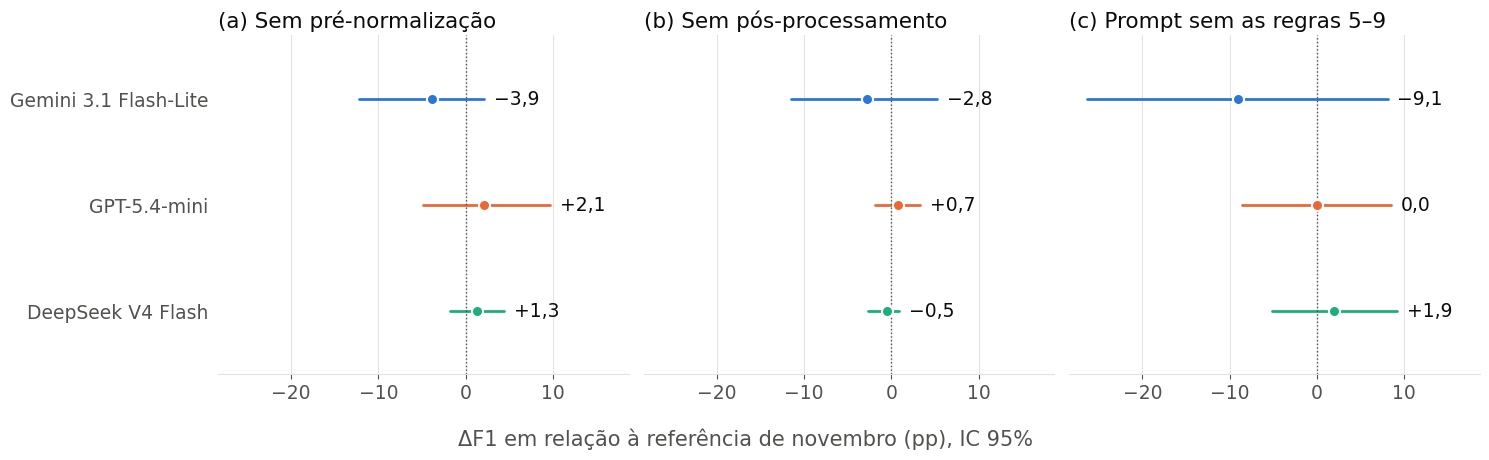

Salvo em: output\sec11_ablacao_pipeline.csv, sec11_deriva.csv e sec11_ablacao_delta.png


In [42]:
# ── 11.3 Ablação: quanto cada componente contribui, por modelo ─────────────────
linhas, deltas = [], {}
for m in MODELOS_G2:
    ref_p = [d["pred_weighted"].values for d in HOJE[m]["completa"]]
    f_ref, b_ref = g2.f1_boot(Y, ref_p, CID)
    for v in VAR_DESC:
        ps = [d["pred_weighted"].values for d in HOJE[m][v]]
        f, b = g2.f1_boot(Y, ps, CID)
        ms = [metricas(Y, p) for p in ps]
        sd = np.std([x["f1"] for x in ms], ddof=1) if len(ms) > 1 else float("nan")
        linha = {"modelo": NOME_G2[m], "variante": VAR_DESC[v], "execuções": len(ps),
                 "VP/FP/FN (média)": "/".join(f"{np.mean([x[k] for x in ms]):.1f}" for k in ("tp", "fp", "fn")),
                 "F1 pond. (média ± dp)": fmt_md(f, sd), "f1": f, "dp": sd,
                 "F1 exact (média)": round(np.mean([metricas(Y, d["pred_exact"])["f1"] for d in HOJE[m][v]]), 4)}
        if v != "completa":
            lo, hi = g2.ic95(b - b_ref)
            deltas[(m, v)] = (f - f_ref, lo, hi)
            linha["ΔF1 vs referência [IC95%] (pp)"] = f"{100*(f-f_ref):+.1f} [{100*lo:+.1f}; {100*hi:+.1f}]"
            linha["significativo"] = "sim" if (lo > 0 or hi < 0) else "não"
        linhas.append(linha)
tab_abl_g2 = pd.DataFrame(linhas)
tab_abl_g2.to_csv(SEC10_DIR.parent / "sec11_ablacao_pipeline.csv", index=False)
display(tab_abl_g2.drop(columns=["f1", "dp"]).set_index(["modelo", "variante"]))

print("Leitura automática:")
for v in ["sem_pre", "sem_pos", "sem_regras_5_9"]:
    partes = []
    for m in MODELOS_G2:
        d, lo, hi = deltas[(m, v)]
        partes.append(f"{NOME_G2[m]} {100*d:+.1f} pp{' *' if (lo > 0 or hi < 0) else ''}")
    print(f"  {VAR_DESC[v]:30s} " + " | ".join(partes))
print("  (* = IC 95% não contém 0)")

# Figura: ΔF1 com IC por variante (painéis) e modelo (linhas)
_vs = ["sem_pre", "sem_pos", "sem_regras_5_9"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
for ax, v in zip(axes, _vs):
    for i, m in enumerate(MODELOS_G2):
        d, lo, hi = (100 * x for x in deltas[(m, v)])
        ax.plot([lo, hi], [i, i], color=CORES_G2[m], lw=2, solid_capstyle="round")
        ax.plot(d, i, "o", ms=8, color=CORES_G2[m], mec="white", mew=1.5, zorder=3)
        # rótulo à direita do fim do IC: nunca encosta na linha pontilhada do zero
        ax.annotate(br(d, 1, sinal=True), (hi, i), xytext=(7, 0), textcoords="offset points",
                    ha="left", va="center", fontsize=13.5, color=TXT1)
    ax.axvline(0, color=TXT2, lw=1, ls=":")
    ax.set_title(VAR_DESC[v], loc="left", fontsize=15.5, color=TXT1)
    ax.set_yticks(range(len(MODELOS_G2)))
    ax.set_yticklabels([NOME_G2[m] for m in MODELOS_G2], fontsize=13.5, color=TXT1)
    ax.set_ylim(-0.6, len(MODELOS_G2) - 0.4)
    ax.invert_yaxis()
    ax.grid(axis="x", color=GRADE, lw=0.8); ax.set_axisbelow(True)
    for lado in ["top", "right", "left"]:
        ax.spines[lado].set_visible(False)
    ax.spines["bottom"].set_color(GRADE)
    ax.tick_params(colors=TXT2, labelsize=13.5, left=False)
    eixos_br(ax, y=False)
_lo_min = min(100 * x[1] for x in deltas.values()); _hi_max = max(100 * x[2] for x in deltas.values())
axes[0].set_xlim(_lo_min - 2, _hi_max + 9)          # espaço para os rótulos à direita
fig.supxlabel("ΔF1 em relação à referência de novembro (pp), IC 95%", color=TXT2, fontsize=15)
plt.tight_layout()
salva_figura(fig, "ablacao", SEC10_DIR.parent / "sec11_ablacao_delta.png")
plt.show()
print(f"Salvo em: {SEC10_DIR.parent / 'sec11_ablacao_pipeline.csv'}, sec11_deriva.csv e sec11_ablacao_delta.png")

## 12. Comparação direta: perguntar a cada modelo se os dois títulos são o mesmo produto

**Pergunta.** A diferença de ~30 pp entre os modelos é fraqueza dos modelos em si ou só aparece quando eles passam pelo pipeline de normalização?

- se GPT e DeepSeek forem bem na comparação direta → normalizar é mais exigente do que comparar, e só o Gemini sustenta a normalização;
- se forem mal também → a dependência do modelo é intrínseca, não efeito do TAIL.

**Desenho.** Os três modelos recebem os 1.200 pares em lotes de 5 (240 chamadas por execução), com os títulos brutos (sem o hash), **3 execuções cada**, e o mesmo prompt — o prompt geral de Peeters & Bizer (2023), traduzido, sem regras de domínio. **O prompt foi fixado em `grupo2.PROMPT_COMPARACAO_DIRETA` antes de qualquer resultado e não foi ajustado depois.** Cada modelo usa a mesma configuração de chamada do pipeline (formato JSON, temperatura 0).

**Respostas fora do formato.** No modo `json_object`, o DeepSeek às vezes devolve só `{"type": "json_object"}` em vez das respostas (14 a 27 lotes por execução; não acontece com Gemini e GPT, nem nas rodadas de normalização). Como é não-determinístico, o lote é tratado como falha transitória e repetido até 5 vezes; a contagem está na tabela 12.1. O que continuar sem resposta válida conta como não-match e também é reportado.

O pipeline de comparação é a **referência de hoje** (Seção 11), não o número de agosto.

In [43]:
# ── 12.1 Execução (com cache) ───────────────────────────────────────────────────
print("Prompt (fixo):", g2.PROMPT_COMPARACAO_DIRETA)
if EXECUTAR_API:
    g2.executar_plano(MODELOS_G2, so_direta=True)
EXEC_DIRETA = list(range(1, g2.EXECUCOES_DIRETA + 1))
DIRETA = {m: [] for m in MODELOS_G2}
linhas = []
for m in MODELOS_G2:
    for r in EXEC_DIRETA:
        p, res = g2.predicoes_comparacao_direta(m, r, df_pares_g2)
        DIRETA[m].append(p)
        linhas.append({"modelo": NOME_G2[m], "exec.": r, "lotes": f"{res['lotes_respondidos']}/{res['lotes_total']}",
                       "bloqueados": res["lotes_bloqueados"], "lotes repetidos (formato)": res["lotes_repetidos_formato"],
                       "pares sem resposta": res["pares_sem_resposta"],
                       "tokens entrada": res["tokens_entrada"], "tokens saída": res["tokens_saida"]})
tab_rod_direta = pd.DataFrame(linhas)
display(tab_rod_direta.set_index(["modelo", "exec."]))

Prompt (fixo): 
Você receberá um ou mais pares de títulos de anúncios de produtos de e-commerce brasileiro.
Para CADA par, responda: os dois títulos se referem ao mesmo produto do mundo real?

Retorne SOMENTE um array JSON válido, sem texto extra e sem markdown, com um objeto por par:
  {"idx": <int, o índice recebido>, "mesmo_produto": true | false}



lotes  bloqueados  lotes repetidos (formato)  \
modelo                exec.                                                   
Gemini 3.1 Flash-Lite 1      240/240           0                          0   
                      2      240/240           0                          0   
                      3      240/240           0                          0   
GPT-5.4-mini          1      240/240           0                          0   
                      2      240/240           0                          0   
                      3      240/240           0                          0   
DeepSeek V4 Flash     1      240/240           0                         27   
                      2      240/240           0                         14   
                      3      240/240           0                         23   

                             pares sem resposta  tokens entrada  tokens saída  
modelo                exec.                                                    
Gemini 3.1 Flash-Lite 1                       0           86644         22410  
                      2                       0           86644         22410  
                      3                       0           86644         22410  
GPT-5.4-mini          1                       0           79985         14636  
                      2                       0           79985         14642  
                      3                       0           79985         14648  
DeepSeek V4 Flash     1                       5           90635         20360  
                      2                       5           90635         20300  
                      3                       5           90635         20318

execuções VP/FP/FN (média)  \
modelo                modo                                                
Gemini 3.1 Flash-Lite TAIL ponderada (hoje)          3    19.0/2.0/11.0   
                      Comparação direta              3    29.0/35.0/1.0   
GPT-5.4-mini          TAIL ponderada (hoje)          5   13.6/13.8/16.4   
                      Comparação direta              3    27.0/26.3/3.0   
DeepSeek V4 Flash     TAIL ponderada (hoje)          5   19.0/18.2/11.0   
                      Comparação direta              3    30.0/48.7/0.0   

                                                  Precisão         Recall  \
modelo                modo                                                  
Gemini 3.1 Flash-Lite TAIL ponderada (hoje)  0.905 ± 0.000  0.633 ± 0.000   
                      Comparação direta      0.453 ± 0.000  0.967 ± 0.000   
GPT-5.4-mini          TAIL ponderada (hoje)  0.496 ± 0.032  0.453 ± 0.056   
                      Comparação direta      0.507 ± 0.014  0.900 ± 0.000   
DeepSeek V4 Flash     TAIL ponderada (hoje)  0.512 ± 0.037  0.633 ± 0.024   
                      Comparação direta      0.382 ± 0.011  1.000 ± 0.000   

                                                        F1  \
modelo                modo                                   
Gemini 3.1 Flash-Lite TAIL ponderada (hoje)  0.745 ± 0.000   
                      Comparação direta      0.617 ± 0.000   
GPT-5.4-mini          TAIL ponderada (hoje)  0.473 ± 0.043   
                      Comparação direta      0.648 ± 0.012   
DeepSeek V4 Flash     TAIL ponderada (hoje)  0.566 ± 0.026   
                      Comparação direta      0.552 ± 0.012   

                                            pares com mesma predição nas execuções  
modelo                modo                                                          
Gemini 3.1 Flash-Lite TAIL ponderada (hoje)                                 100.0%  
                      Comparação direta                                     100.0%  
GPT-5.4-mini          TAIL ponderada (hoje)                                  98.0%  
                      Comparação direta                                      99.4%  
DeepSeek V4 Flash     TAIL ponderada (hoje)                                  98.4%  
                      Comparação direta                                      99.2%

TAIL − comparação direta, por modelo (pp, IC 95%; * = significativo):
  Gemini 3.1 Flash-Lite    +12.8 [-4.2; +29.6]
  GPT-5.4-mini             -17.5 [-34.4; -1.3] *
  DeepSeek V4 Flash        +1.4 [-13.8; +15.7]

A diferença entre modelos aparece nos dois modos? (Gemini − outro, pp, IC 95%)


,no TAIL,na comparação direta,gap TAIL − gap direta
comparação,,,
Gemini − GPT-5.4-mini,+27.2 [+10.0; +45.6] *,-3.1 [-11.9; +6.3],+30.3 [+12.1; +49.7] *
Gemini − DeepSeek V4 Flash,+17.9 [+3.6; +33.3] *,+6.5 [+0.3; +12.8] *,+11.4 [-4.1; +27.8]



Custo médio por execução nesta avaliação (TAIL: 452 chamadas; direta: 240 chamadas):


TAIL                      direta             
                      tokens entrada tokens saída tokens entrada tokens saída
modelo                                                                       
DeepSeek V4 Flash             637191       205106          90635        20326
GPT-5.4-mini                  541468       136077          79985        14642
Gemini 3.1 Flash-Lite         625782       231827          86644        22410

Escala: deduplicar N itens sem bloqueio = N(N−1)/2 julgamentos na direta contra N normalizações no TAIL (N = 10.000: 9,999,000 chamadas contra 2,000).


Figura salva em: figuras_tcc\tail_vs_direta.pdf e .png (300 dpi)


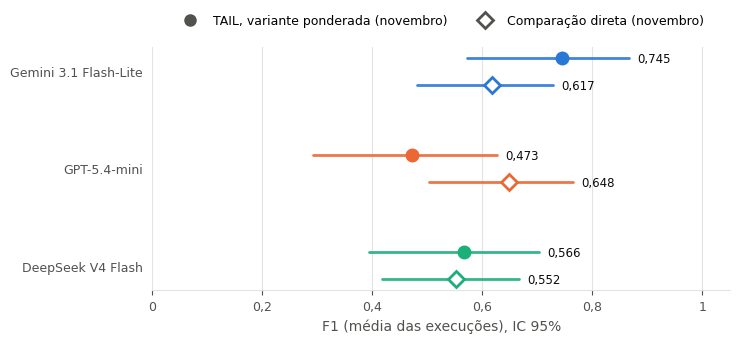

Salvo em: output\sec12_comparacao_direta.csv, sec12_gap_modelos.csv, sec12_tail_vs_direta.png e dados/grupo2/comparacao_direta_predicoes.csv


In [44]:
# ── 12.2 Resultado: pipeline × comparação direta, por modelo ───────────────────
BOOT = {}
for m in MODELOS_G2:
    BOOT[(m, "TAIL")] = g2.f1_boot(Y, [d["pred_weighted"].values for d in HOJE[m]["completa"]], CID)
    BOOT[(m, "direta")] = g2.f1_boot(Y, DIRETA[m], CID)

linhas = []
for m in MODELOS_G2:
    for modo, preds in [("TAIL ponderada (hoje)", [d["pred_weighted"].values for d in HOJE[m]["completa"]]),
                        ("Comparação direta", DIRETA[m])]:
        ms = [metricas(Y, p) for p in preds]
        sd = lambda k: np.std([x[k] for x in ms], ddof=1) if len(ms) > 1 else float("nan")
        mean = lambda k: float(np.mean([x[k] for x in ms]))
        estavel = np.mean(np.all(np.array(preds) == preds[0], axis=0)) if len(preds) > 1 else float("nan")
        linhas.append({"modelo": NOME_G2[m], "modo": modo, "execuções": len(preds),
                       "VP/FP/FN (média)": "/".join(f"{mean(k):.1f}" for k in ("tp", "fp", "fn")),
                       "Precisão": fmt_md(mean("precision"), sd("precision")),
                       "Recall": fmt_md(mean("recall"), sd("recall")),
                       "F1": fmt_md(mean("f1"), sd("f1")),
                       "pares com mesma predição nas execuções": "—" if np.isnan(estavel) else f"{estavel:.1%}"})
tab_dir = pd.DataFrame(linhas).set_index(["modelo", "modo"])
tab_dir.to_csv(SEC10_DIR.parent / "sec12_comparacao_direta.csv")
display(tab_dir)

def _fmt_delta(a, b):
    (fa, da), (fb, db) = BOOT[a], BOOT[b]
    lo, hi = g2.ic95(da - db)
    return fa - fb, lo, hi, f"{100*(fa-fb):+.1f} [{100*lo:+.1f}; {100*hi:+.1f}]" + (" *" if (lo > 0 or hi < 0) else "")

print("TAIL − comparação direta, por modelo (pp, IC 95%; * = significativo):")
for m in MODELOS_G2:
    print(f"  {NOME_G2[m]:24s} {_fmt_delta((m, 'TAIL'), (m, 'direta'))[3]}")

print("\nA diferença entre modelos aparece nos dois modos? (Gemini − outro, pp, IC 95%)")
linhas = []
for outro in [m for m in MODELOS_G2 if m != "gemini"]:
    tail = _fmt_delta(("gemini", "TAIL"), (outro, "TAIL"))
    dire = _fmt_delta(("gemini", "direta"), (outro, "direta"))
    # diferença de diferenças: o gap do pipeline é maior que o gap da comparação direta?
    dd = (BOOT[("gemini", "TAIL")][1] - BOOT[(outro, "TAIL")][1]) - (BOOT[("gemini", "direta")][1] - BOOT[(outro, "direta")][1])
    dd_obs = tail[0] - dire[0]
    lo, hi = g2.ic95(dd)
    linhas.append({"comparação": f"Gemini − {NOME_G2[outro]}", "no TAIL": tail[3], "na comparação direta": dire[3],
                   "gap TAIL − gap direta": f"{100*dd_obs:+.1f} [{100*lo:+.1f}; {100*hi:+.1f}]" + (" *" if (lo > 0 or hi < 0) else "")})
tab_gap = pd.DataFrame(linhas).set_index("comparação")
tab_gap.to_csv(SEC10_DIR.parent / "sec12_gap_modelos.csv")
display(tab_gap)

# Custo por modelo (média por execução)
_c = tab_rodadas[tab_rodadas.rodada == "completa"].groupby("modelo")[["tokens entrada", "tokens saída"]].mean()
_d = tab_rod_direta.groupby("modelo")[["tokens entrada", "tokens saída"]].mean()
print("\nCusto médio por execução nesta avaliação (TAIL: 452 chamadas; direta: 240 chamadas):")
display(pd.concat({"TAIL": _c, "direta": _d}, axis=1).round(0).astype(int))
print("Escala: deduplicar N itens sem bloqueio = N(N−1)/2 julgamentos na direta contra N normalizações no TAIL "
      f"(N = 10.000: {-(-(10_000*9_999//2)//5):,} chamadas contra {10_000//5:,}).")

# Figura: F1 do TAIL e da comparação direta por modelo (média das execuções, IC 95%)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
_modos = [("TAIL", "o", "TAIL, variante ponderada (novembro)"), ("direta", "D", "Comparação direta (novembro)")]
for i, m in enumerate(MODELOS_G2):
    for j, (modo, mk, _) in enumerate(_modos):
        f, dist = BOOT[(m, modo)]
        lo, hi = g2.ic95(dist)
        yv = i + (j - 0.5) * 0.28
        ax.plot([lo, hi], [yv, yv], color=CORES_G2[m], lw=2, alpha=0.9, solid_capstyle="round")
        ax.plot(f, yv, mk, ms=8, color=CORES_G2[m], mfc=CORES_G2[m] if modo == "TAIL" else "white", mew=2, zorder=3)
        ax.annotate(br(f), (hi, yv), xytext=(6, -3), textcoords="offset points", fontsize=8.5, color=TXT1)
ax.set_yticks(range(len(MODELOS_G2)))
ax.set_yticklabels([NOME_G2[m] for m in MODELOS_G2], color=TXT1, fontsize=9.5)
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.set_xlabel("F1 (média das execuções), IC 95%", color=TXT2)
ax.grid(axis="x", color=GRADE, lw=0.8); ax.set_axisbelow(True)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color(GRADE)
ax.tick_params(colors=TXT2, labelsize=9, left=False)
eixos_br(ax, y=False)
ax.legend([Line2D([], [], marker="o", ls="", color=TXT2, ms=8), Line2D([], [], marker="D", ls="", color=TXT2, mfc="white", mew=2, ms=8)],
          [_modos[0][2], _modos[1][2]], frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, 1.18), ncol=2)
plt.tight_layout()
salva_figura(fig, "tail_vs_direta", SEC10_DIR.parent / "sec12_tail_vs_direta.png")
plt.show()

pd.DataFrame({"title_a": df_pares_g2.title_a, "title_b": df_pares_g2.title_b, "label": Y,
              **{f"direta_{m}_r{r}": DIRETA[m][r - 1] for m in MODELOS_G2 for r in EXEC_DIRETA}}) \
  .to_csv("dados/grupo2/comparacao_direta_predicoes.csv", index=False, encoding="utf-8-sig")
print(f"Salvo em: {SEC10_DIR.parent / 'sec12_comparacao_direta.csv'}, sec12_gap_modelos.csv, sec12_tail_vs_direta.png "
      "e dados/grupo2/comparacao_direta_predicoes.csv")

## 13. Linha de base com embeddings de sentenças (local, sem API)

Similaridade do cosseno entre os embeddings dos dois títulos (sem o hash), com dois modelos multilíngues rodando na CPU:

- **SBERT** `paraphrase-multilingual-mpnet-base-v2` (Reimers & Gurevych, 2020);
- **E5** `multilingual-e5-base` (Wang et al., 2024), com o prefixo `query:` exigido pelo modelo.

Para comparar em pé de igualdade com o TF-IDF, o limiar é escolhido **do mesmo jeito do `baseline.ipynb`** (o que maximiza F1 no próprio conjunto — otimista para a linha de base) e também por **validação cruzada** (limiar escolhido só nos folds de treino, como na 10.4b). A coluna AUC-PR (precisão média) independe de limiar. ΔF1 = Gemini ponderado (rodada do artigo) − método, com bootstrap pareado por cluster e McNemar.

Fora do notebook: `python grupo2.py embeddings` (baixa os modelos do Hugging Face na primeira vez).

1.200 pares, 30 positivos. 'F1 validação cruzada' = média [2,5–97,5%] de 200 repetições × 5 folds por cluster.


,limiar,Precisão,Recall,F1 (limiar ótimo),F1 validação cruzada,AUC-PR,ΔF1 Gemini − método [IC95%] (pp),McNemar p
método,,,,,,,,
Gemini ponderada (artigo),0.9000,0.952,0.667,0.7843,0.756 [0.717; 0.760],NaN,NaN,NaN
TF-IDF palavra,0.6080,0.541,0.667,0.5970,0.534 [0.492; 0.576],0.5790,+18.7 [+1.1; +37.3],0.003719
TF-IDF caractere,0.7789,0.514,0.633,0.5672,0.494 [0.452; 0.531],0.5742,+21.7 [+5.3; +39.4],0.000912
SBERT paraphrase-multilingual-mpnet,0.9146,0.410,0.533,0.4638,0.387 [0.316; 0.432],0.4978,+32.0 [+15.4; +50.1],0.000006
multilingual-e5-base,0.9698,0.714,0.667,0.6897,0.635 [0.582; 0.678],0.7429,+9.5 [-9.8; +30.3],0.210040


Figura salva em: figuras_tcc\linhas_base_pr.pdf e .png (300 dpi)


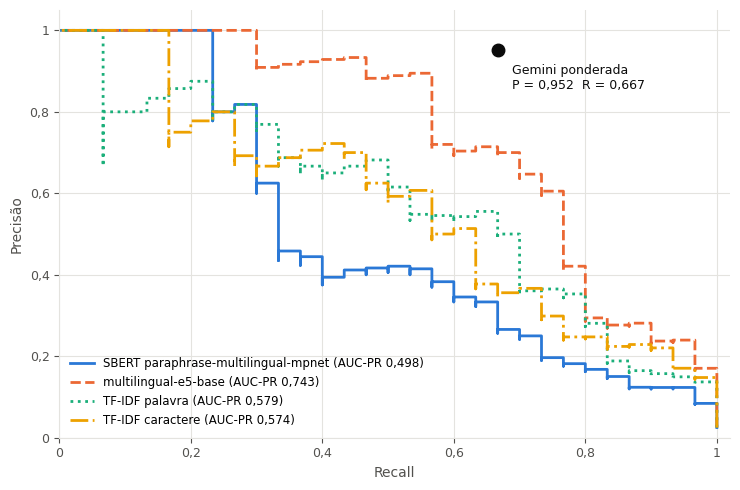

Salvo em: output\sec13_embeddings.csv, sec13_pr_embeddings.png e dados/grupo2/embeddings_predictions.csv


In [45]:
# ── 13.1 Embeddings × TF-IDF × Gemini ───────────────────────────────────────────
from sklearn.metrics import average_precision_score, precision_recall_curve

_bl = pd.read_csv("dados/baseline_predictions.csv", encoding="utf-8-sig")
assert (_bl["title_a"].values == df_pares_g2["title_a"].values).all() and (_bl["label"].values == Y).all()

escores = {"TF-IDF palavra": _bl["sim_tfidf_word"].values.astype(float),
           "TF-IDF caractere": _bl["sim_tfidf_char"].values.astype(float)}
for nome in g2.MODELOS_EMBEDDING:
    escores[nome] = g2.similaridades_embedding(nome, df_pares_g2)

_gem = artigo_g["pred_weighted"].values
_grade_tail = np.round(np.arange(0.80, 0.98 + 1e-9, 0.02), 2)
_cv_gem = g2.cv_limiar(Y, artigo_g["sim"].values, CID, grade=_grade_tail, bloqueado=artigo_g[BLOQUEIOS].any(axis=1).values)

linhas, preds_emb = [], {}
mg = metricas(Y, _gem)
linhas.append({"método": "Gemini ponderada (artigo)", "limiar": 0.90, "Precisão": round(mg["precision"], 3),
               "Recall": round(mg["recall"], 3), "F1 (limiar ótimo)": round(mg["f1"], 4),
               "F1 validação cruzada": f"{_cv_gem.mean():.3f} [{np.percentile(_cv_gem, 2.5):.3f}; {np.percentile(_cv_gem, 97.5):.3f}]",
               "AUC-PR": None})
for nome, s in escores.items():
    thr, _ = g2.limiar_otimo(Y, s)
    p = (s >= thr).astype(int)
    preds_emb[nome] = p
    m = metricas(Y, p)
    cv = g2.cv_limiar(Y, s, CID)
    bs = paired_bootstrap(Y, _gem, p, CID)
    mc = mcnemar(Y, _gem, p)
    linhas.append({"método": nome, "limiar": round(thr, 4), "Precisão": round(m["precision"], 3),
                   "Recall": round(m["recall"], 3), "F1 (limiar ótimo)": round(m["f1"], 4),
                   "F1 validação cruzada": f"{cv.mean():.3f} [{np.percentile(cv, 2.5):.3f}; {np.percentile(cv, 97.5):.3f}]",
                   "AUC-PR": round(average_precision_score(Y, s), 4),
                   "ΔF1 Gemini − método [IC95%] (pp)": f"{100*bs['delta_f1']:+.1f} [{100*bs['ci_lo']:+.1f}; {100*bs['ci_hi']:+.1f}]",
                   "McNemar p": mc["p_value"]})
tab_emb = pd.DataFrame(linhas).set_index("método")
tab_emb.to_csv(SEC10_DIR.parent / "sec13_embeddings.csv")
print("1.200 pares, 30 positivos. 'F1 validação cruzada' = média [2,5–97,5%] de 200 repetições × 5 folds por cluster.")
display(tab_emb)

pd.DataFrame({"title_a": df_pares_g2.title_a, "title_b": df_pares_g2.title_b, "label": Y,
              **{f"sim_{k}": np.round(v, 4) for k, v in escores.items() if k in g2.MODELOS_EMBEDDING},
              **{f"pred_{k}": v for k, v in preds_emb.items() if k in g2.MODELOS_EMBEDDING}}) \
  .to_csv("dados/grupo2/embeddings_predictions.csv", index=False, encoding="utf-8-sig")

# Curvas precisão-recall + ponto de operação do Gemini
_CORES_PR = {"SBERT paraphrase-multilingual-mpnet": "#2a78d6", "multilingual-e5-base": "#eb6834",
             "TF-IDF palavra": "#1baf7a", "TF-IDF caractere": "#eda100"}
fig, ax = plt.subplots(figsize=(7.5, 5))
# Traço diferente por curva: legível também impresso em preto e branco.
_TRACO_PR = {"SBERT paraphrase-multilingual-mpnet": "-", "multilingual-e5-base": "--",
             "TF-IDF palavra": ":", "TF-IDF caractere": "-."}
for nome in _CORES_PR:
    pr, rc, _ = precision_recall_curve(Y, escores[nome])
    ax.step(rc, pr, where="post", color=_CORES_PR[nome], lw=2, ls=_TRACO_PR[nome],
            label=f"{nome} (AUC-PR {br(average_precision_score(Y, escores[nome]))})")
ax.plot(mg["recall"], mg["precision"], "o", ms=9, color=TXT1, zorder=5)
ax.annotate(f"Gemini ponderada\nP = {br(mg['precision'])}  R = {br(mg['recall'])}", (mg["recall"], mg["precision"]),
            xytext=(10, -28), textcoords="offset points", fontsize=9, color=TXT1)
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.05)
ax.set_xlabel("Recall", color=TXT2); ax.set_ylabel("Precisão", color=TXT2)
ax.grid(color=GRADE, lw=0.8); ax.set_axisbelow(True)
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)
for lado in ["left", "bottom"]:
    ax.spines[lado].set_color(GRADE)
ax.tick_params(colors=TXT2, labelsize=9)
eixos_br(ax)
ax.legend(frameon=False, fontsize=8.5, loc="lower left")
plt.tight_layout()
salva_figura(fig, "linhas_base_pr", SEC10_DIR.parent / "sec13_pr_embeddings.png")
plt.show()
print(f"Salvo em: {SEC10_DIR.parent / 'sec13_embeddings.csv'}, sec13_pr_embeddings.png e dados/grupo2/embeddings_predictions.csv")